In [1]:
# ============================================================
# SAC FOR 3-RPR PARALLEL MANIPULATOR
# CELL 1 — IMPORTS AND CONFIGURATION
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from collections import deque

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# Problem dimensions
# ------------------------------------------------------------

STATE_DIM = 6
DESIRED_STATE_DIM = 6
ACTOR_INPUT_DIM = STATE_DIM + DESIRED_STATE_DIM

ACTION_DIM = 3
MAX_ACTION = 2.0

# ------------------------------------------------------------
# SAC hyperparameters
# ------------------------------------------------------------

GAMMA = 0.99
TAU = 0.005

BATCH_SIZE = 100
REPLAY_BUFFER_SIZE = 100_000

ACTOR_LR = 3e-4
CRITIC_LR = 3e-4
ALPHA_LR = 3e-4

# Automatic entropy tuning
TARGET_ENTROPY = -ACTION_DIM

# ------------------------------------------------------------
# Robot simulation
# ------------------------------------------------------------

DT = 0.01

# Baseline reward coefficient
LAMBDA_FORCE = 0.01

print("SAC 3-RPR configuration loaded")
print("Device:", device)
print("State dimension:", STATE_DIM)
print("Actor input dimension:", ACTOR_INPUT_DIM)
print("Action dimension:", ACTION_DIM)
print("Action range:", [-MAX_ACTION, MAX_ACTION])
print("Gamma:", GAMMA)
print("Batch size:", BATCH_SIZE)
print("Replay buffer:", REPLAY_BUFFER_SIZE)
print("DT:", DT)

SAC 3-RPR configuration loaded
Device: cpu
State dimension: 6
Actor input dimension: 12
Action dimension: 3
Action range: [-2.0, 2.0]
Gamma: 0.99
Batch size: 100
Replay buffer: 100000
DT: 0.01


In [4]:
# ============================================================
# CELL 2 — LOAD AND VERIFY ACTUAL 3-RPR DYNAMICS
# ============================================================

import importlib.util
import sys
from pathlib import Path
import numpy as np

# ------------------------------------------------------------
# Locate dynamics.py
# ------------------------------------------------------------

dynamics_path = Path("../dynamics/dynamics.py").resolve()

if not dynamics_path.exists():
    raise FileNotFoundError(
        f"dynamics.py was not found at:\n{dynamics_path}"
    )

# ------------------------------------------------------------
# Load dynamics.py correctly
# ------------------------------------------------------------

module_name = "robot_dynamics"

spec = importlib.util.spec_from_file_location(
    module_name,
    dynamics_path
)

robot_dynamics = importlib.util.module_from_spec(spec)

# IMPORTANT:
# Register the module before executing it.
# This is required for @dataclass and other module-level code.
sys.modules[module_name] = robot_dynamics

spec.loader.exec_module(robot_dynamics)

print("dynamics.py loaded successfully")

# ------------------------------------------------------------
# Build the actual 3-RPR dynamics model
# ------------------------------------------------------------

params = robot_dynamics.load_params_from_robot_properties()

Phi_fun, A_fun, L_fun = robot_dynamics.build_sympy_model(params)

_, _, state_derivative, _, diagnostics = (
    robot_dynamics.make_reduced_dynamics(
        params,
        Phi_fun,
        A_fun,
        L_fun
    )
)

print("3-RPR dynamics model built successfully")

# ------------------------------------------------------------
# Robot step function
# ------------------------------------------------------------

def robot_step(state, forces, dt=DT):

    state = np.asarray(state, dtype=np.float64)
    forces = np.asarray(forces, dtype=np.float64)

    state_jax = robot_dynamics.jnp.asarray(
        state,
        dtype=robot_dynamics.jnp.float64
    )

    forces_jax = robot_dynamics.jnp.asarray(
        forces,
        dtype=robot_dynamics.jnp.float64
    )

    state_dot = state_derivative(
        state_jax,
        forces_jax
    )

    next_state = state + dt * np.asarray(state_dot)

    return next_state


# ------------------------------------------------------------
# Known 3-RPR dynamics sanity test
# ------------------------------------------------------------

test_state = np.array([
    0.45,
    0.45,
    0.10,
    0.10,
    -0.05,
    0.02
], dtype=np.float64)

test_forces = np.array([
    0.50,
    -0.25,
    0.15
], dtype=np.float64)

expected_next_state = np.array([
    0.451,
    0.4495,
    0.1002,
    0.10134615,
    -0.04987539,
    0.01838396
])

actual_next_state = robot_step(
    test_state,
    test_forces
)

max_difference = np.max(
    np.abs(
        actual_next_state - expected_next_state
    )
)

print("\nInitial state:")
print(test_state)

print("\nForces:")
print(test_forces)

print("\nActual next state:")
print(actual_next_state)

print("\nExpected next state:")
print(expected_next_state)

print("\nMaximum absolute difference:")
print(max_difference)

if max_difference < 1e-5:
    print("\nDynamics sanity test PASSED")
else:
    print("\nDynamics sanity test FAILED")

Could not load robot_properties.py. Using fallback parameters.
Reason: ModuleNotFoundError("No module named 'robot_properties'")
dynamics.py loaded successfully
Could not load robot_properties.py. Using fallback parameters.
Reason: ModuleNotFoundError("No module named 'robot_properties'")
3-RPR dynamics model built successfully

Initial state:
[ 0.45  0.45  0.1   0.1  -0.05  0.02]

Forces:
[ 0.5  -0.25  0.15]

Actual next state:
[ 0.451       0.4495      0.1002      0.10134615 -0.04987539  0.01838396]

Expected next state:
[ 0.451       0.4495      0.1002      0.10134615 -0.04987539  0.01838396]

Maximum absolute difference:
4.403990349483022e-09

Dynamics sanity test PASSED


In [5]:
# ============================================================
# CELL 3 — SAC STOCHASTIC ACTOR
# ============================================================

class SACActor(nn.Module):

    def __init__(
        self,
        input_dim=ACTOR_INPUT_DIM,
        action_dim=ACTION_DIM,
        max_action=MAX_ACTION
    ):
        super().__init__()

        self.max_action = max_action

        # Policy network
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU()
        )

        # Gaussian policy outputs
        self.mean_layer = nn.Linear(256, action_dim)
        self.log_std_layer = nn.Linear(256, action_dim)

    def forward(self, state, desired_state):

        # Combine current and desired states
        x = torch.cat(
            [state, desired_state],
            dim=-1
        )

        x = self.network(x)

        mean = self.mean_layer(x)
        log_std = self.log_std_layer(x)

        # Prevent extremely large/small standard deviations
        log_std = torch.clamp(
            log_std,
            min=-20,
            max=2
        )

        return mean, log_std

    def sample(self, state, desired_state):

        mean, log_std = self.forward(
            state,
            desired_state
        )

        std = log_std.exp()

        # Gaussian sampling
        normal = torch.distributions.Normal(
            mean,
            std
        )

        z = normal.rsample()

        # Squash action to [-1, 1]
        squashed_action = torch.tanh(z)

        # Scale to [-2, 2]
        action = self.max_action * squashed_action

        # Log probability with tanh correction
        log_prob = normal.log_prob(z)

        log_prob -= torch.log(
            1 - squashed_action.pow(2) + 1e-6
        )

        log_prob = log_prob.sum(
            dim=-1,
            keepdim=True
        )

        # Deterministic action for evaluation
        deterministic_action = (
            self.max_action * torch.tanh(mean)
        )

        return (
            action,
            log_prob,
            deterministic_action
        )


# ------------------------------------------------------------
# Create actor
# ------------------------------------------------------------

actor = SACActor().to(device)

print("SAC Actor created successfully")
print(actor)

# ------------------------------------------------------------
# Test actor with one state-goal pair
# ------------------------------------------------------------

test_current_state = torch.tensor(
    [[0.45, 0.45, 0.10, 0.10, -0.05, 0.02]],
    dtype=torch.float32,
    device=device
)

test_desired_state = torch.tensor(
    [[0.50, 0.50, 0.00, 0.00, 0.00, 0.00]],
    dtype=torch.float32,
    device=device
)

with torch.no_grad():

    test_action, test_log_prob, test_deterministic = (
        actor.sample(
            test_current_state,
            test_desired_state
        )
    )

print("\nTest stochastic action:")
print(test_action.cpu().numpy())

print("\nTest log probability:")
print(test_log_prob.cpu().numpy())

print("\nTest deterministic action:")
print(test_deterministic.cpu().numpy())

print("\nAction minimum:", test_action.min().item())
print("Action maximum:", test_action.max().item())

assert test_action.shape == (1, ACTION_DIM)
assert test_log_prob.shape == (1, 1)
assert test_deterministic.shape == (1, ACTION_DIM)

assert torch.all(test_action <= MAX_ACTION)
assert torch.all(test_action >= -MAX_ACTION)

print("\nActor sanity test PASSED")

SAC Actor created successfully
SACActor(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
  )
  (mean_layer): Linear(in_features=256, out_features=3, bias=True)
  (log_std_layer): Linear(in_features=256, out_features=3, bias=True)
)

Test stochastic action:
[[-1.909531   1.1370056 -0.3554344]]

Test log probability:
[[-2.077318]]

Test deterministic action:
[[ 0.03474985  0.10348111 -0.0039962 ]]

Action minimum: -1.9095309972763062
Action maximum: 1.1370055675506592

Actor sanity test PASSED


In [7]:
# ============================================================
# CELL 4 — SAC TWIN CRITICS
# ============================================================

class SACCritic(nn.Module):

    def __init__(
        self,
        state_dim=STATE_DIM,
        desired_state_dim=DESIRED_STATE_DIM,
        action_dim=ACTION_DIM
    ):
        super().__init__()

        # Input:
        # current state (6)
        # desired state (6)
        # action (3)
        # total = 15
        input_dim = state_dim + desired_state_dim + action_dim

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 1)
        )

    def forward(
        self,
        state,
        desired_state,
        action
    ):

        x = torch.cat(
            [state, desired_state, action],
            dim=-1
        )

        return self.network(x)


# ------------------------------------------------------------
# Create twin critics
# ------------------------------------------------------------

critic1 = SACCritic().to(device)
critic2 = SACCritic().to(device)

print("SAC Twin Critics created successfully")

print("\nCritic 1:")
print(critic1)

print("\nCritic 2:")
print(critic2)


# ------------------------------------------------------------
# Test critics
# ------------------------------------------------------------

with torch.no_grad():

    q1_test = critic1(
        test_current_state,
        test_desired_state,
        test_action
    )

    q2_test = critic2(
        test_current_state,
        test_desired_state,
        test_action
    )

print("\nQ1 test output:")
print(q1_test.cpu().numpy())

print("\nQ2 test output:")
print(q2_test.cpu().numpy())


# ------------------------------------------------------------
# Shape verification
# ------------------------------------------------------------

assert q1_test.shape == (1, 1)
assert q2_test.shape == (1, 1)

print("\nCritic sanity test PASSED")

SAC Twin Critics created successfully

Critic 1:
SACCritic(
  (network): Sequential(
    (0): Linear(in_features=15, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)

Critic 2:
SACCritic(
  (network): Sequential(
    (0): Linear(in_features=15, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)

Q1 test output:
[[0.12543033]]

Q2 test output:
[[-0.0909244]]

Critic sanity test PASSED


In [8]:
# ============================================================
# CELL 5 — SAC REPLAY BUFFER
# ============================================================

class ReplayBuffer:

    def __init__(self, capacity=REPLAY_BUFFER_SIZE):
        self.buffer = deque(maxlen=capacity)

    def add(
        self,
        state,
        desired_state,
        action,
        reward,
        next_state,
        done
    ):
        self.buffer.append((
            np.asarray(state, dtype=np.float32),
            np.asarray(desired_state, dtype=np.float32),
            np.asarray(action, dtype=np.float32),
            float(reward),
            np.asarray(next_state, dtype=np.float32),
            float(done)
        ))

    def sample(self, batch_size=BATCH_SIZE):

        batch = random.sample(
            self.buffer,
            batch_size
        )

        states, desired_states, actions, rewards, next_states, dones = zip(
            *batch
        )

        return (
            np.asarray(states, dtype=np.float32),
            np.asarray(desired_states, dtype=np.float32),
            np.asarray(actions, dtype=np.float32),
            np.asarray(rewards, dtype=np.float32).reshape(-1, 1),
            np.asarray(next_states, dtype=np.float32),
            np.asarray(dones, dtype=np.float32).reshape(-1, 1)
        )

    def __len__(self):
        return len(self.buffer)


# ------------------------------------------------------------
# Create replay buffer
# ------------------------------------------------------------

replay_buffer = ReplayBuffer()

print("Replay buffer created successfully")
print("Capacity:", REPLAY_BUFFER_SIZE)


# ------------------------------------------------------------
# Add test transitions
# ------------------------------------------------------------

for _ in range(BATCH_SIZE):

    state = np.random.uniform(
        -0.1, 0.1, STATE_DIM
    )

    desired_state = np.zeros(
        DESIRED_STATE_DIM
    )

    action = np.random.uniform(
        -MAX_ACTION,
        MAX_ACTION,
        ACTION_DIM
    )

    reward = -np.random.random()

    next_state = state + np.random.normal(
        0,
        0.01,
        STATE_DIM
    )

    done = False

    replay_buffer.add(
        state,
        desired_state,
        action,
        reward,
        next_state,
        done
    )


# ------------------------------------------------------------
# Sample test batch
# ------------------------------------------------------------

sampled = replay_buffer.sample(BATCH_SIZE)

(
    states,
    desired_states,
    actions,
    rewards,
    next_states,
    dones
) = sampled


print("\nBuffer size:", len(replay_buffer))

print("\nSample shapes:")
print("States:", states.shape)
print("Desired states:", desired_states.shape)
print("Actions:", actions.shape)
print("Rewards:", rewards.shape)
print("Next states:", next_states.shape)
print("Dones:", dones.shape)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert states.shape == (BATCH_SIZE, STATE_DIM)
assert desired_states.shape == (BATCH_SIZE, DESIRED_STATE_DIM)
assert actions.shape == (BATCH_SIZE, ACTION_DIM)
assert rewards.shape == (BATCH_SIZE, 1)
assert next_states.shape == (BATCH_SIZE, STATE_DIM)
assert dones.shape == (BATCH_SIZE, 1)

print("\nReplay buffer sanity test PASSED")

Replay buffer created successfully
Capacity: 100000

Buffer size: 100

Sample shapes:
States: (100, 6)
Desired states: (100, 6)
Actions: (100, 3)
Rewards: (100, 1)
Next states: (100, 6)
Dones: (100, 1)

Replay buffer sanity test PASSED


In [9]:
# ============================================================
# CELL 6 — SAC AGENT
# ============================================================

class SACAgent:

    def __init__(self):

        # ----------------------------------------------------
        # Networks
        # ----------------------------------------------------

        self.actor = SACActor().to(device)

        self.critic1 = SACCritic().to(device)
        self.critic2 = SACCritic().to(device)

        self.target_critic1 = SACCritic().to(device)
        self.target_critic2 = SACCritic().to(device)

        # Initially target critics = critics
        self.target_critic1.load_state_dict(
            self.critic1.state_dict()
        )

        self.target_critic2.load_state_dict(
            self.critic2.state_dict()
        )

        # ----------------------------------------------------
        # Optimizers
        # ----------------------------------------------------

        self.actor_optimizer = optim.Adam(
            self.actor.parameters(),
            lr=ACTOR_LR
        )

        self.critic1_optimizer = optim.Adam(
            self.critic1.parameters(),
            lr=CRITIC_LR
        )

        self.critic2_optimizer = optim.Adam(
            self.critic2.parameters(),
            lr=CRITIC_LR
        )

        # ----------------------------------------------------
        # Automatic entropy tuning
        # ----------------------------------------------------

        self.log_alpha = torch.zeros(
            1,
            requires_grad=True,
            device=device
        )

        self.alpha_optimizer = optim.Adam(
            [self.log_alpha],
            lr=ALPHA_LR
        )

        self.target_entropy = TARGET_ENTROPY

    @property
    def alpha(self):
        return self.log_alpha.exp()

    # --------------------------------------------------------
    # Action selection
    # --------------------------------------------------------

    def select_action(
        self,
        state,
        desired_state,
        deterministic=False
    ):

        state_tensor = torch.as_tensor(
            state,
            dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        desired_tensor = torch.as_tensor(
            desired_state,
            dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        with torch.no_grad():

            action, _, deterministic_action = (
                self.actor.sample(
                    state_tensor,
                    desired_tensor
                )
            )

        if deterministic:
            return deterministic_action.cpu().numpy()[0]

        return action.cpu().numpy()[0]

    # --------------------------------------------------------
    # Soft update of target critics
    # --------------------------------------------------------

    def soft_update(
        self,
        source,
        target
    ):

        for target_param, source_param in zip(
            target.parameters(),
            source.parameters()
        ):

            target_param.data.copy_(
                (1.0 - TAU) * target_param.data
                + TAU * source_param.data
            )

    # --------------------------------------------------------
    # SAC training update
    # --------------------------------------------------------

    def update(self, replay_buffer):

        (
            states,
            desired_states,
            actions,
            rewards,
            next_states,
            dones
        ) = replay_buffer.sample(BATCH_SIZE)

        # Convert to tensors
        states = torch.as_tensor(
            states,
            dtype=torch.float32,
            device=device
        )

        desired_states = torch.as_tensor(
            desired_states,
            dtype=torch.float32,
            device=device
        )

        actions = torch.as_tensor(
            actions,
            dtype=torch.float32,
            device=device
        )

        rewards = torch.as_tensor(
            rewards,
            dtype=torch.float32,
            device=device
        )

        next_states = torch.as_tensor(
            next_states,
            dtype=torch.float32,
            device=device
        )

        dones = torch.as_tensor(
            dones,
            dtype=torch.float32,
            device=device
        )

        # ----------------------------------------------------
        # Target Q-value
        # ----------------------------------------------------

        with torch.no_grad():

            next_action, next_log_prob, _ = (
                self.actor.sample(
                    next_states,
                    desired_states
                )
            )

            target_q1 = self.target_critic1(
                next_states,
                desired_states,
                next_action
            )

            target_q2 = self.target_critic2(
                next_states,
                desired_states,
                next_action
            )

            target_q = torch.min(
                target_q1,
                target_q2
            )

            target_q = (
                target_q
                - self.alpha.detach() * next_log_prob
            )

            target_value = (
                rewards
                + GAMMA * (1.0 - dones) * target_q
            )

        # ----------------------------------------------------
        # Critic 1 update
        # ----------------------------------------------------

        current_q1 = self.critic1(
            states,
            desired_states,
            actions
        )

        critic1_loss = nn.functional.mse_loss(
            current_q1,
            target_value
        )

        self.critic1_optimizer.zero_grad()
        critic1_loss.backward()
        self.critic1_optimizer.step()

        # ----------------------------------------------------
        # Critic 2 update
        # ----------------------------------------------------

        current_q2 = self.critic2(
            states,
            desired_states,
            actions
        )

        critic2_loss = nn.functional.mse_loss(
            current_q2,
            target_value
        )

        self.critic2_optimizer.zero_grad()
        critic2_loss.backward()
        self.critic2_optimizer.step()

        # ----------------------------------------------------
        # Actor update
        # ----------------------------------------------------

        new_action, log_prob, _ = (
            self.actor.sample(
                states,
                desired_states
            )
        )

        q1_new = self.critic1(
            states,
            desired_states,
            new_action
        )

        q2_new = self.critic2(
            states,
            desired_states,
            new_action
        )

        min_q_new = torch.min(
            q1_new,
            q2_new
        )

        actor_loss = (
            self.alpha.detach() * log_prob
            - min_q_new
        ).mean()

        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()

        # ----------------------------------------------------
        # Automatic alpha update
        # ----------------------------------------------------

        alpha_loss = -(
            self.log_alpha
            * (
                log_prob.detach()
                + self.target_entropy
            )
        ).mean()

        self.alpha_optimizer.zero_grad()
        alpha_loss.backward()
        self.alpha_optimizer.step()

        # ----------------------------------------------------
        # Soft target updates
        # ----------------------------------------------------

        self.soft_update(
            self.critic1,
            self.target_critic1
        )

        self.soft_update(
            self.critic2,
            self.target_critic2
        )

        return {
            "critic1_loss": critic1_loss.item(),
            "critic2_loss": critic2_loss.item(),
            "actor_loss": actor_loss.item(),
            "alpha_loss": alpha_loss.item(),
            "alpha": self.alpha.item()
        }


# ============================================================
# Create SAC agent
# ============================================================

agent = SACAgent()

print("SAC Agent created successfully")

print("\nInitial alpha:")
print(agent.alpha.item())

print("\nTarget entropy:")
print(agent.target_entropy)

print("\nSAC Agent sanity test PASSED")

SAC Agent created successfully

Initial alpha:
1.0

Target entropy:
-3

SAC Agent sanity test PASSED


In [10]:
# ============================================================
# CELL 7 — SAC ACTION SAMPLING VERIFICATION
# ============================================================

test_state = np.array([
    0.45,
    0.45,
    0.10,
    0.05,
    -0.05,
    0.02
], dtype=np.float32)

test_goal = np.array([
    0.50,
    0.50,
    0.00,
    0.00,
    0.00,
    0.00
], dtype=np.float32)


# ------------------------------------------------------------
# Stochastic actions
# ------------------------------------------------------------

stochastic_actions = np.array([
    agent.select_action(
        test_state,
        test_goal,
        deterministic=False
    )
    for _ in range(5)
])


# ------------------------------------------------------------
# Deterministic actions
# ------------------------------------------------------------

deterministic_actions = np.array([
    agent.select_action(
        test_state,
        test_goal,
        deterministic=True
    )
    for _ in range(3)
])


print("Stochastic actions:")
print(stochastic_actions)

print("\nDeterministic actions:")
print(deterministic_actions)


# ------------------------------------------------------------
# Verify action limits
# ------------------------------------------------------------

assert np.all(
    stochastic_actions >= -MAX_ACTION
)

assert np.all(
    stochastic_actions <= MAX_ACTION
)

assert np.all(
    deterministic_actions >= -MAX_ACTION
)

assert np.all(
    deterministic_actions <= MAX_ACTION
)


# ------------------------------------------------------------
# Verify stochastic behavior
# ------------------------------------------------------------

unique_stochastic_actions = np.unique(
    stochastic_actions,
    axis=0
)

assert len(unique_stochastic_actions) > 1


# ------------------------------------------------------------
# Verify deterministic behavior
# ------------------------------------------------------------

assert np.allclose(
    deterministic_actions[0],
    deterministic_actions[1]
)

assert np.allclose(
    deterministic_actions[1],
    deterministic_actions[2]
)


print("\nAction range verification PASSED")
print("Stochastic sampling verification PASSED")
print("Deterministic sampling verification PASSED")
print("\nCell 7 PASSED")

Stochastic actions:
[[ 0.07187324 -0.7159902   0.94887805]
 [-1.7260678   1.7275006  -1.2820079 ]
 [ 1.4067171  -1.3221445  -1.1841284 ]
 [ 1.6791769   1.9962074  -0.5783212 ]
 [ 1.5238072   0.4233591   1.9500391 ]]

Deterministic actions:
[[0.03965646 0.13064177 0.02293913]
 [0.03965646 0.13064177 0.02293913]
 [0.03965646 0.13064177 0.02293913]]

Action range verification PASSED
Stochastic sampling verification PASSED
Deterministic sampling verification PASSED

Cell 7 PASSED


In [11]:
# ============================================================
# CELL 8 — ONE-STEP ENVIRONMENT INTERACTION
# ============================================================

# ------------------------------------------------------------
# Generate one valid training task
# ------------------------------------------------------------

initial_state = np.array([
    0.50,       # x
    0.50,       # y
    0.00,       # theta
    0.05,       # x_dot
    -0.05,      # y_dot
    0.02        # theta_dot
], dtype=np.float64)

desired_state = np.array([
    0.55,       # desired x
    0.45,       # desired y
    0.05,       # desired theta
    0.00,       # desired x_dot
    0.00,       # desired y_dot
    0.00        # desired theta_dot
], dtype=np.float64)


# ------------------------------------------------------------
# Select action using SAC actor
# ------------------------------------------------------------

action = agent.select_action(
    initial_state,
    desired_state,
    deterministic=False
)

action = np.asarray(
    action,
    dtype=np.float64
)


# ------------------------------------------------------------
# Step the ACTUAL 3-RPR dynamics
# ------------------------------------------------------------

next_state = robot_step(
    initial_state,
    action,
    dt=DT
)


# ------------------------------------------------------------
# Baseline reward
# ------------------------------------------------------------

state_error = next_state - desired_state

state_cost = np.sum(
    state_error ** 2
)

force_cost = np.sum(
    action ** 2
)

reward = -(
    state_cost
    + LAMBDA_FORCE * force_cost
)


# ------------------------------------------------------------
# Display transition
# ------------------------------------------------------------

print("Initial state:")
print(initial_state)

print("\nDesired state:")
print(desired_state)

print("\nSAC action:")
print(action)

print("\nNext state:")
print(next_state)

print("\nState cost:")
print(state_cost)

print("\nForce cost:")
print(force_cost)

print("\nReward:")
print(reward)


# ------------------------------------------------------------
# Basic verification
# ------------------------------------------------------------

assert initial_state.shape == (STATE_DIM,)
assert desired_state.shape == (DESIRED_STATE_DIM,)
assert action.shape == (ACTION_DIM,)
assert next_state.shape == (STATE_DIM,)

assert np.all(action >= -MAX_ACTION)
assert np.all(action <= MAX_ACTION)

assert np.all(np.isfinite(next_state))
assert np.isfinite(reward)

print("\nOne-step environment interaction PASSED")

Initial state:
[ 0.5   0.5   0.    0.05 -0.05  0.02]

Desired state:
[0.55 0.45 0.05 0.   0.   0.  ]

SAC action:
[ 1.14491117  0.82811052 -1.63715792]

Next state:
[ 5.00500000e-01  4.99500000e-01  2.00000000e-04  5.19191330e-02
 -4.18501933e-02  2.72382419e-03]

State cost:
0.011834994274298356

Force cost:
4.676874659302076

Reward:
-0.058603740867319114

One-step environment interaction PASSED


In [12]:
# ============================================================
# CELL 9 — SAC TRAINING STEP
# ============================================================

# ------------------------------------------------------------
# Add the real environment transition from Cell 8
# ------------------------------------------------------------

replay_buffer.add(
    initial_state,
    desired_state,
    action,
    reward,
    next_state,
    False
)

# ------------------------------------------------------------
# Fill the buffer enough for one SAC batch
# ------------------------------------------------------------

while len(replay_buffer) < BATCH_SIZE:

    random_state = np.concatenate([
        np.random.uniform(0.4, 0.6, 2),
        np.random.uniform(-0.1, 0.1, 1),
        np.random.uniform(-0.1, 0.1, 3)
    ])

    random_goal = np.concatenate([
        np.random.uniform(0.4, 0.6, 2),
        np.random.uniform(-0.1, 0.1, 1),
        np.zeros(3)
    ])

    random_action = np.random.uniform(
        -MAX_ACTION,
        MAX_ACTION,
        ACTION_DIM
    )

    random_next_state = robot_step(
        random_state,
        random_action,
        dt=DT
    )

    random_reward = -(
        np.sum(
            (random_next_state - random_goal) ** 2
        )
        + LAMBDA_FORCE * np.sum(
            random_action ** 2
        )
    )

    replay_buffer.add(
        random_state,
        random_goal,
        random_action,
        random_reward,
        random_next_state,
        False
    )


print("Replay buffer size before update:", len(replay_buffer))


# ------------------------------------------------------------
# Perform one complete SAC update
# ------------------------------------------------------------

losses = agent.update(
    replay_buffer
)


# ------------------------------------------------------------
# Display update results
# ------------------------------------------------------------

print("\nSAC training update completed")

print("\nCritic 1 loss:")
print(losses["critic1_loss"])

print("\nCritic 2 loss:")
print(losses["critic2_loss"])

print("\nActor loss:")
print(losses["actor_loss"])

print("\nAlpha loss:")
print(losses["alpha_loss"])

print("\nUpdated alpha:")
print(losses["alpha"])


# ------------------------------------------------------------
# Verify losses are valid
# ------------------------------------------------------------

for name, value in losses.items():

    assert np.isfinite(value), (
        f"{name} produced an invalid value: {value}"
    )

assert losses["alpha"] > 0

print("\nAll SAC losses are finite")
print("Automatic entropy tuning is functioning")
print("\nSAC training step PASSED")

Replay buffer size before update: 101

SAC training update completed

Critic 1 loss:
2.206233263015747

Critic 2 loss:
2.382258415222168

Actor loss:
-2.024034023284912

Alpha loss:
-0.0

Updated alpha:
0.9997000694274902

All SAC losses are finite
Automatic entropy tuning is functioning

SAC training step PASSED


In [13]:
# ============================================================
# CELL 10 — SAC TRAINING PIPELINE
# ============================================================

# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

NUM_EPISODES = 1000
STEPS_PER_EPISODE = 100

WARMUP_STEPS = 1000
UPDATE_AFTER = 1000
UPDATES_PER_STEP = 1

PRINT_EVERY = 50

# Maximum episode reward history
episode_rewards = []

# Track average final position error during training
episode_final_errors = []

# Global environment step counter
total_steps = 0


# ------------------------------------------------------------
# Generate randomized training task
# ------------------------------------------------------------

def generate_training_task():

    # Initial state
    initial_state = np.concatenate([
        np.random.uniform(0.4, 0.6, 2),       # x, y
        np.random.uniform(-0.1, 0.1, 1),       # theta
        np.random.uniform(-0.1, 0.1, 3)        # velocities
    ]).astype(np.float64)

    # Desired state
    desired_state = np.concatenate([
        np.random.uniform(0.4, 0.6, 2),       # xd, yd
        np.random.uniform(-0.1, 0.1, 1),       # theta_d
        np.zeros(3)                            # desired velocities
    ]).astype(np.float64)

    return initial_state, desired_state


# ------------------------------------------------------------
# Baseline reward
# ------------------------------------------------------------

def calculate_reward(
    next_state,
    desired_state,
    action
):

    state_cost = np.sum(
        (next_state - desired_state) ** 2
    )

    force_cost = np.sum(
        action ** 2
    )

    reward = -(
        state_cost
        + LAMBDA_FORCE * force_cost
    )

    return float(reward)


# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------

print("Starting SAC training...")
print("Episodes:", NUM_EPISODES)
print("Steps per episode:", STEPS_PER_EPISODE)
print("Warmup steps:", WARMUP_STEPS)
print()


for episode in range(1, NUM_EPISODES + 1):

    # Generate a new randomized training task
    state, desired_state = generate_training_task()

    episode_reward = 0.0

    # --------------------------------------------------------
    # Run one episode
    # --------------------------------------------------------

    for step in range(STEPS_PER_EPISODE):

        total_steps += 1

        # ----------------------------------------------------
        # Action selection
        # ----------------------------------------------------

        if total_steps <= WARMUP_STEPS:

            # Random exploration during warmup
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float64)

        else:

            # SAC stochastic policy
            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

            action = np.asarray(
                action,
                dtype=np.float64
            )

        # ----------------------------------------------------
        # Actual 3-RPR dynamics
        # ----------------------------------------------------

        next_state = robot_step(
            state,
            action,
            dt=DT
        )

        # ----------------------------------------------------
        # Baseline reward
        # ----------------------------------------------------

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        # No early termination for this baseline controller
        done = (
            step == STEPS_PER_EPISODE - 1
        )

        # ----------------------------------------------------
        # Store transition
        # ----------------------------------------------------

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            done
        )

        episode_reward += reward

        # ----------------------------------------------------
        # SAC updates
        # ----------------------------------------------------

        if total_steps >= UPDATE_AFTER:

            for _ in range(UPDATES_PER_STEP):

                agent.update(
                    replay_buffer
                )

        # Move to next state
        state = next_state

    # --------------------------------------------------------
    # Episode metrics
    # --------------------------------------------------------

    initial_position_error = np.linalg.norm(
        np.array([
            # We need the original initial state.
            # Reconstructing it here is not possible,
            # so this metric is intentionally omitted.
            0.0,
            0.0,
            0.0
        ])
    )

    final_position_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    episode_rewards.append(
        episode_reward
    )

    episode_final_errors.append(
        final_position_error
    )

    # --------------------------------------------------------
    # Progress display
    # --------------------------------------------------------

    if episode == 1 or episode % PRINT_EVERY == 0:

        recent_rewards = episode_rewards[
            -PRINT_EVERY:
        ]

        recent_errors = episode_final_errors[
            -PRINT_EVERY:
        ]

        print(
            f"Episode {episode:4d}/{NUM_EPISODES} | "
            f"Steps: {total_steps:6d} | "
            f"Avg Reward: {np.mean(recent_rewards):10.3f} | "
            f"Avg Final Error: {np.mean(recent_errors):.6f} | "
            f"Alpha: {agent.alpha.item():.4f}"
        )


print("\nSAC training completed.")

print("Total environment steps:", total_steps)
print("Replay buffer size:", len(replay_buffer))
print("Final alpha:", agent.alpha.item())

Starting SAC training...
Episodes: 1000
Steps per episode: 100
Warmup steps: 1000

Episode    1/1000 | Steps:    100 | Avg Reward:     -6.049 | Avg Final Error: 0.145006 | Alpha: 0.9997
Episode   50/1000 | Steps:   5000 | Avg Reward:     -8.864 | Avg Final Error: 0.171651 | Alpha: 0.3018
Episode  100/1000 | Steps:  10000 | Avg Reward:     -8.851 | Avg Final Error: 0.192707 | Alpha: 0.0702
Episode  150/1000 | Steps:  15000 | Avg Reward:     -6.862 | Avg Final Error: 0.168225 | Alpha: 0.0178
Episode  200/1000 | Steps:  20000 | Avg Reward:     -6.955 | Avg Final Error: 0.197298 | Alpha: 0.0107
Episode  250/1000 | Steps:  25000 | Avg Reward:     -5.656 | Avg Final Error: 0.167654 | Alpha: 0.0054
Episode  300/1000 | Steps:  30000 | Avg Reward:     -3.575 | Avg Final Error: 0.143890 | Alpha: 0.0030
Episode  350/1000 | Steps:  35000 | Avg Reward:     -3.341 | Avg Final Error: 0.140849 | Alpha: 0.0018
Episode  400/1000 | Steps:  40000 | Avg Reward:     -3.064 | Avg Final Error: 0.136984 | Alph

In [14]:
# ============================================================
# CELL 11 — FIXED UNSEEN EVALUATION
# ============================================================

# ------------------------------------------------------------
# Fixed evaluation configuration
# ------------------------------------------------------------

NUM_EVAL_TASKS = 100
EVAL_STEPS = 100
EVAL_SEED = 12345


# ------------------------------------------------------------
# Generate FIXED unseen evaluation tasks
# ------------------------------------------------------------

eval_rng = np.random.RandomState(EVAL_SEED)

fixed_eval_tasks = []

for _ in range(NUM_EVAL_TASKS):

    initial_state = np.concatenate([
        eval_rng.uniform(0.4, 0.6, 2),       # x, y
        eval_rng.uniform(-0.1, 0.1, 1),       # theta
        eval_rng.uniform(-0.1, 0.1, 3)        # velocities
    ]).astype(np.float64)

    desired_state = np.concatenate([
        eval_rng.uniform(0.4, 0.6, 2),       # desired x, y
        eval_rng.uniform(-0.1, 0.1, 1),       # desired theta
        np.zeros(3)                            # desired velocities
    ]).astype(np.float64)

    fixed_eval_tasks.append(
        (
            initial_state.copy(),
            desired_state.copy()
        )
    )


print("Fixed evaluation tasks generated")
print("Number of tasks:", len(fixed_eval_tasks))
print("Evaluation seed:", EVAL_SEED)


# ------------------------------------------------------------
# Evaluate SAC on fixed unseen tasks
# ------------------------------------------------------------

initial_errors = []
final_errors = []
improvements = []
episode_rewards_eval = []
successes = []

for task_id, (
    initial_state,
    desired_state
) in enumerate(fixed_eval_tasks, start=1):

    # Copy task so the fixed evaluation set itself is untouched
    state = initial_state.copy()

    # --------------------------------------------------------
    # Initial position/orientation error
    # --------------------------------------------------------

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    total_reward = 0.0

    # --------------------------------------------------------
    # Run evaluation episode
    # --------------------------------------------------------

    for step in range(EVAL_STEPS):

        # Deterministic SAC policy
        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        action = np.asarray(
            action,
            dtype=np.float64
        )

        # Actual 3-RPR dynamics
        next_state = robot_step(
            state,
            action,
            dt=DT
        )

        # Required baseline reward
        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        total_reward += reward

        state = next_state

    # --------------------------------------------------------
    # Final error
    # --------------------------------------------------------

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    improvement = (
        initial_error - final_error
    )

    # Required success criterion
    success = final_error < initial_error

    initial_errors.append(initial_error)
    final_errors.append(final_error)
    improvements.append(improvement)
    episode_rewards_eval.append(total_reward)
    successes.append(success)


# ------------------------------------------------------------
# Convert results to arrays
# ------------------------------------------------------------

initial_errors = np.asarray(initial_errors)
final_errors = np.asarray(final_errors)
improvements = np.asarray(improvements)
episode_rewards_eval = np.asarray(
    episode_rewards_eval
)
successes = np.asarray(successes)


# ------------------------------------------------------------
# Final evaluation metrics
# ------------------------------------------------------------

average_initial_error = np.mean(
    initial_errors
)

average_final_error = np.mean(
    final_errors
)

average_improvement = np.mean(
    improvements
)

best_final_error = np.min(
    final_errors
)

worst_final_error = np.max(
    final_errors
)

average_reward = np.mean(
    episode_rewards_eval
)

success_count = np.sum(
    successes
)

success_rate = (
    success_count / NUM_EVAL_TASKS
) * 100


# ------------------------------------------------------------
# Display final results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SAC FIXED UNSEEN EVALUATION")
print("=" * 60)

print(
    f"Average initial error : {average_initial_error:.6f}"
)

print(
    f"Average final error   : {average_final_error:.6f}"
)

print(
    f"Average improvement   : {average_improvement:.6f}"
)

print(
    f"Best final error      : {best_final_error:.6f}"
)

print(
    f"Worst final error     : {worst_final_error:.6f}"
)

print(
    f"Average reward        : {average_reward:.6f}"
)

print(
    f"Successes             : {success_count}/{NUM_EVAL_TASKS}"
)

print(
    f"Success rate          : {success_rate:.2f}%"
)

print("=" * 60)


# ------------------------------------------------------------
# Target verification
# ------------------------------------------------------------

if success_rate >= 89.0:

    print(
        "\nTARGET ACHIEVED: SAC success rate is >= 89%."
    )

elif success_rate > 88.0:

    print(
        "\nTARGET THRESHOLD PASSED: "
        "SAC success rate is above 88%."
    )

else:

    print(
        "\nTARGET NOT YET ACHIEVED: "
        "SAC success rate is <= 88%."
    )


# ------------------------------------------------------------
# Basic validation
# ------------------------------------------------------------

assert len(initial_errors) == NUM_EVAL_TASKS
assert len(final_errors) == NUM_EVAL_TASKS
assert len(improvements) == NUM_EVAL_TASKS
assert len(episode_rewards_eval) == NUM_EVAL_TASKS
assert len(successes) == NUM_EVAL_TASKS

assert np.all(np.isfinite(initial_errors))
assert np.all(np.isfinite(final_errors))
assert np.all(np.isfinite(episode_rewards_eval))

print("\nFixed unseen evaluation PASSED")

Fixed evaluation tasks generated
Number of tasks: 100
Evaluation seed: 12345

SAC FIXED UNSEEN EVALUATION
Average initial error : 0.128981
Average final error   : 0.152991
Average improvement   : -0.024010
Best final error      : 0.035080
Worst final error     : 0.318771
Average reward        : -3.260213
Successes             : 29/100
Success rate          : 29.00%

TARGET NOT YET ACHIEVED: SAC success rate is <= 88%.

Fixed unseen evaluation PASSED


In [15]:
# ============================================================
# DIAGNOSTIC — CHECK SAC POLICY AFTER TRAINING
# ============================================================

print("Alpha:", agent.alpha.item())

print("\nActor output statistics:")

all_actions = []

for initial_state, desired_state in fixed_eval_tasks:

    action = agent.select_action(
        initial_state,
        desired_state,
        deterministic=True
    )

    all_actions.append(action)

all_actions = np.array(all_actions)

print("Mean action:", np.mean(all_actions, axis=0))
print("Std action :", np.std(all_actions, axis=0))
print("Min action :", np.min(all_actions, axis=0))
print("Max action :", np.max(all_actions, axis=0))

print("\nDiagnostic completed.")

Alpha: 0.002278437837958336

Actor output statistics:
Mean action: [-0.10844663  0.2122508  -0.00191474]
Std action : [0.5892586  0.5215652  0.27803043]
Min action : [-1.6185178 -1.2725921 -1.12995  ]
Max action : [1.2653257  1.2303596  0.76841193]

Diagnostic completed.


In [16]:
# ============================================================
# DIAGNOSTIC — SINGLE TASK TRAJECTORY
# ============================================================

initial_state, desired_state = fixed_eval_tasks[0]

state = initial_state.copy()

initial_error = np.linalg.norm(
    state[:3] - desired_state[:3]
)

errors = []

for step in range(100):

    action = agent.select_action(
        state,
        desired_state,
        deterministic=True
    )

    next_state = robot_step(
        state,
        action,
        dt=DT
    )

    error = np.linalg.norm(
        next_state[:3] - desired_state[:3]
    )

    errors.append(error)

    state = next_state

print("Initial error:", initial_error)
print("Error after 1 step:", errors[0])
print("Error after 25 steps:", errors[24])
print("Error after 50 steps:", errors[49])
print("Error after 75 steps:", errors[74])
print("Final error:", errors[-1])

print("\nImprovement:", initial_error - errors[-1])
print("Success:", errors[-1] < initial_error)

Initial error: 0.13173677124578015
Error after 1 step: 0.13153629162051353
Error after 25 steps: 0.1276133225450314
Error after 50 steps: 0.12741164983880424
Error after 75 steps: 0.13335956627351414
Final error: 0.14368128044505435

Improvement: -0.0119445091992742
Success: False


In [17]:
# ============================================================
# CELL 12 — DIAGNOSTIC: SINGLE TASK TRAJECTORY
# ============================================================

initial_state, desired_state = fixed_eval_tasks[0]

state = initial_state.copy()

initial_error = np.linalg.norm(
    state[:3] - desired_state[:3]
)

errors = []

for step in range(100):

    action = agent.select_action(
        state,
        desired_state,
        deterministic=True
    )

    next_state = robot_step(
        state,
        action,
        dt=DT
    )

    error = np.linalg.norm(
        next_state[:3] - desired_state[:3]
    )

    errors.append(error)

    state = next_state

print("Initial error:", initial_error)
print("Error after 1 step:", errors[0])
print("Error after 25 steps:", errors[24])
print("Error after 50 steps:", errors[49])
print("Error after 75 steps:", errors[74])
print("Final error:", errors[-1])

print("\nImprovement:", initial_error - errors[-1])
print("Success:", errors[-1] < initial_error)

Initial error: 0.13173677124578015
Error after 1 step: 0.13153629162051353
Error after 25 steps: 0.1276133225450314
Error after 50 steps: 0.12741164983880424
Error after 75 steps: 0.13335956627351414
Final error: 0.14368128044505435

Improvement: -0.0119445091992742
Success: False


In [18]:
# ============================================================
# CELL 13 — DIAGNOSTIC: REWARD AND Q-VALUE SCALE
# ============================================================

states, desired_states, actions, rewards, next_states, dones = (
    replay_buffer.sample(100)
)

states_t = torch.tensor(
    states, dtype=torch.float32, device=device
)

desired_t = torch.tensor(
    desired_states, dtype=torch.float32, device=device
)

actions_t = torch.tensor(
    actions, dtype=torch.float32, device=device
)

with torch.no_grad():

    q1 = critic1(
        states_t,
        desired_t,
        actions_t
    )

    q2 = critic2(
        states_t,
        desired_t,
        actions_t
    )

print("Reward mean:", rewards.mean())
print("Reward std :", rewards.std())
print("Reward min :", rewards.min())
print("Reward max :", rewards.max())

print("\nQ1 mean:", q1.mean().item())
print("Q1 std :", q1.std().item())
print("Q1 min :", q1.min().item())
print("Q1 max :", q1.max().item())

print("\nQ2 mean:", q2.mean().item())
print("Q2 std :", q2.std().item())
print("Q2 min :", q2.min().item())
print("Q2 max :", q2.max().item())

print("\nAlpha:", agent.alpha.item())

Reward mean: -0.043188013
Reward std : 0.026510205
Reward min : -0.16189308
Reward max : -0.0066046086

Q1 mean: 0.07647886872291565
Q1 std : 0.014554512687027454
Q1 min : 0.025031348690390587
Q1 max : 0.1397705376148224

Q2 mean: -0.022475725039839745
Q2 std : 0.022092871367931366
Q2 min : -0.12172006815671921
Q2 max : 0.026306934654712677

Alpha: 0.002278437837958336


In [21]:
# ============================================================
# CELL 14 — RESET SAC ALPHA
# ============================================================

ALPHA_MIN = 0.05
ALPHA_MAX = 1.0

with torch.no_grad():
    agent.log_alpha.fill_(
        np.log(0.2)
    )

print("Alpha reset to:", agent.alpha.item())
print("Allowed range:", ALPHA_MIN, "to", ALPHA_MAX)

assert ALPHA_MIN <= agent.alpha.item() <= ALPHA_MAX

print("\nAlpha reset PASSED")

Alpha reset to: 0.19999998807907104
Allowed range: 0.05 to 1.0

Alpha reset PASSED


In [22]:
# ============================================================
# CELL 15 — REBUILD SAC AGENT
# ============================================================

agent = SACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))

print("New SAC agent created")
print("Initial alpha:", agent.alpha.item())

assert abs(agent.alpha.item() - 0.2) < 1e-5

print("\nAgent rebuild PASSED")

New SAC agent created
Initial alpha: 0.19999998807907104

Agent rebuild PASSED


In [23]:
# ============================================================
# CELL 16 — SHORT SAC SANITY TRAINING
# ============================================================

SHORT_EPISODES = 10
STEPS_PER_EPISODE = 100

short_rewards = []

for episode in range(SHORT_EPISODES):

    state, desired_state = generate_training_task()
    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=False
        )

        next_state = robot_step(
            state,
            action,
            dt=DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            step == STEPS_PER_EPISODE - 1
        )

        if len(replay_buffer) >= BATCH_SIZE:
            agent.update(replay_buffer)

        episode_reward += reward
        state = next_state

    short_rewards.append(episode_reward)

    print(
        f"Episode {episode + 1:2d}/{SHORT_EPISODES} | "
        f"Reward: {episode_reward:9.3f} | "
        f"Alpha: {agent.alpha.item():.4f}"
    )

print("\nShort SAC training PASSED")
print("Final alpha:", agent.alpha.item())

Episode  1/10 | Reward:    -6.913 | Alpha: 0.1941
Episode  2/10 | Reward:    -6.410 | Alpha: 0.1883
Episode  3/10 | Reward:    -9.488 | Alpha: 0.1828
Episode  4/10 | Reward:   -15.765 | Alpha: 0.1774
Episode  5/10 | Reward:    -9.012 | Alpha: 0.1721
Episode  6/10 | Reward:    -6.107 | Alpha: 0.1670
Episode  7/10 | Reward:    -5.137 | Alpha: 0.1621
Episode  8/10 | Reward:   -10.712 | Alpha: 0.1573
Episode  9/10 | Reward:   -12.409 | Alpha: 0.1527
Episode 10/10 | Reward:    -7.910 | Alpha: 0.1482

Short SAC training PASSED
Final alpha: 0.14816373586654663


In [24]:
# ============================================================
# CELL 17 — FIX SAC TRAINING SETUP
# ============================================================

# Keep entropy from collapsing too quickly
ALPHA_MIN = 0.05
ALPHA_MAX = 1.0

# Start fresh
agent = SACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))

# Fresh replay buffer — remove diagnostic/random transitions
replay_buffer = ReplayBuffer()

# Training parameters
NUM_EPISODES = 1000
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 2000
UPDATE_AFTER = 2000

# Store training metrics
episode_rewards = []
episode_final_errors = []

total_steps = 0

print("Fresh SAC training setup created")
print("Initial alpha:", agent.alpha.item())
print("Replay buffer:", len(replay_buffer))
print("Warmup steps:", WARMUP_STEPS)
print("Update after:", UPDATE_AFTER)

assert abs(agent.alpha.item() - 0.2) < 1e-5
assert len(replay_buffer) == 0

print("\nSetup PASSED")

Fresh SAC training setup created
Initial alpha: 0.19999998807907104
Replay buffer: 0
Warmup steps: 2000
Update after: 2000

Setup PASSED


In [26]:
# ============================================================
# CELL 18 — REWARD & DYNAMICS VALIDATION
# ============================================================

np.random.seed(2026)

NUM_TESTS = 20

print("Testing actual 3-RPR dynamics and reward...")
print()

for i in range(NUM_TESTS):

    state, desired_state = generate_training_task()

    action = np.random.uniform(
        -MAX_ACTION,
        MAX_ACTION,
        ACTION_DIM
    )

    next_state = robot_step(
        state,
        action,
        dt=DT
    )

    reward = calculate_reward(
        next_state,
        desired_state,
        action
    )

    # Manual reward calculation
    manual_reward = -(
        np.sum(
            (next_state - desired_state) ** 2
        )
        + LAMBDA_FORCE * np.sum(action ** 2)
    )

    assert next_state.shape == (6,)
    assert np.all(np.isfinite(next_state))
    assert np.isfinite(reward)

    assert np.isclose(
        reward,
        manual_reward,
        atol=1e-10
    )

    if i < 3:
        print(f"Test {i + 1}")
        print("State:       ", state)
        print("Action:      ", action)
        print("Next state:  ", next_state)
        print("Reward:      ", reward)
        print()

print("=" * 50)
print(f"{NUM_TESTS}/{NUM_TESTS} tests passed")
print("Dynamics and reward calculation are consistent.")

Testing actual 3-RPR dynamics and reward...

Test 1
State:        [ 0.44386913  0.48260235  0.0953271  -0.0822202  -0.00414203  0.0975101 ]
Action:       [ 1.13291787 -0.79009364 -0.41079603]
Next state:   [ 0.44304693  0.48256093  0.0963022  -0.07818348 -0.00231736  0.07946278]
Reward:       -0.05033155010512178

Test 2
State:        [ 0.45919346  0.57881769 -0.09036498 -0.01098647  0.01237878 -0.02725707]
Action:       [-1.51437825 -1.07237452  0.5715878 ]
Next state:   [ 0.4590836   0.57894148 -0.09063755 -0.0117872   0.00550882 -0.00863137]
Reward:       -0.04435801458927395

Test 3
State:        [ 0.44718672  0.59337315 -0.07016657 -0.09062071 -0.00590977  0.0365155 ]
Action:       [-0.13197777 -0.9703976   0.03211312]
Next state:   [ 0.44628051  0.59331406 -0.06980142 -0.08898061 -0.00828044  0.03201686]
Reward:       -0.044080961225725475

20/20 tests passed
Dynamics and reward calculation are consistent.


In [27]:
# ============================================================
# CELL 19 — REWARD BEHAVIOR TEST
# ============================================================

state = np.array([
    0.45, 0.45, 0.05,
    0.05, -0.05, 0.02
], dtype=np.float64)

desired_state = np.array([
    0.50, 0.50, 0.00,
    0.00, 0.00, 0.00
], dtype=np.float64)

zero_action = np.zeros(3)

small_action = np.array([
    0.1, 0.1, 0.1
])

large_action = np.array([
    2.0, 2.0, 2.0
])

# Use actual dynamics for each action
next_zero = robot_step(state, zero_action, DT)
next_small = robot_step(state, small_action, DT)
next_large = robot_step(state, large_action, DT)

reward_zero = calculate_reward(
    next_zero,
    desired_state,
    zero_action
)

reward_small = calculate_reward(
    next_small,
    desired_state,
    small_action
)

reward_large = calculate_reward(
    next_large,
    desired_state,
    large_action
)

print("Initial state error:",
      np.sum((state - desired_state) ** 2))

print("\nReward with zero action :", reward_zero)
print("Reward with small action:", reward_small)
print("Reward with large action:", reward_large)

print("\nNext state with zero action:")
print(next_zero)

print("\nNext state with small action:")
print(next_small)

print("\nNext state with large action:")
print(next_large)

assert np.isfinite(reward_zero)
assert np.isfinite(reward_small)
assert np.isfinite(reward_large)

print("\nReward behavior test completed.")

Initial state error: 0.012899999999999998

Reward with zero action : -0.012921144231035308
Reward with small action: -0.013246628645541396
Reward with large action: -0.13399746657053868

Next state with zero action:
[ 0.4505      0.4495      0.0502      0.04999497 -0.05000469  0.02001596]

Next state with small action:
[ 0.4505      0.4495      0.0502      0.04988074 -0.04987493  0.02122478]

Next state with large action:
[ 0.4505      0.4495      0.0502      0.04771055 -0.04740946  0.04419246]

Reward behavior test completed.


In [28]:
# ============================================================
# CELL 20 — MULTI-STEP CONTROL EFFECT
# ============================================================

state = np.array([
    0.45, 0.45, 0.05,
    0.05, -0.05, 0.02
], dtype=np.float64)

desired_state = np.array([
    0.50, 0.50, 0.00,
    0.00, 0.00, 0.00
], dtype=np.float64)

test_actions = {
    "zero": np.zeros(3),
    "positive": np.array([2.0, 2.0, 2.0]),
    "negative": np.array([-2.0, -2.0, -2.0])
}

for name, action in test_actions.items():

    current_state = state.copy()

    initial_error = np.linalg.norm(
        current_state[:3] - desired_state[:3]
    )

    for _ in range(100):

        current_state = robot_step(
            current_state,
            action,
            DT
        )

    final_error = np.linalg.norm(
        current_state[:3] - desired_state[:3]
    )

    print(f"{name.upper()} FORCE")
    print("Initial error:", initial_error)
    print("Final error:  ", final_error)
    print("Improvement:  ", initial_error - final_error)
    print()

ZERO FORCE
Initial error: 0.08660254037844385
Final error:   0.1224770862145193
Improvement:   -0.03587454583607545

POSITIVE FORCE
Initial error: 0.08660254037844385
Final error:   3.321735911086807
Improvement:   -3.2351333707083634

NEGATIVE FORCE
Initial error: 0.08660254037844385
Final error:   0.26998593945152166
Improvement:   -0.18338339907307782



In [29]:
# ============================================================
# CELL 21 — RANDOM ACTION CONTROL TEST
# ============================================================

np.random.seed(2027)

state = np.array([
    0.45, 0.45, 0.05,
    0.05, -0.05, 0.02
], dtype=np.float64)

desired_state = np.array([
    0.50, 0.50, 0.00,
    0.00, 0.00, 0.00
], dtype=np.float64)

initial_error = np.linalg.norm(
    state[:3] - desired_state[:3]
)

best_error = initial_error
best_action = None
best_state = state.copy()

current_state = state.copy()

for step in range(100):

    action = np.random.uniform(
        -MAX_ACTION,
        MAX_ACTION,
        ACTION_DIM
    )

    next_state = robot_step(
        current_state,
        action,
        DT
    )

    error = np.linalg.norm(
        next_state[:3] - desired_state[:3]
    )

    if error < best_error:
        best_error = error
        best_action = action.copy()
        best_state = next_state.copy()

    current_state = next_state

print("Initial error:", initial_error)
print("Best error found:", best_error)
print("Best improvement:", initial_error - best_error)

print("\nBest action:")
print(best_action)

print("\nState after best action:")
print(best_state)

print("\nCan random actions improve the error?")
print(best_error < initial_error)

Initial error: 0.08660254037844385
Best error found: 0.08041554637424647
Best improvement: 0.00618699400419738

Best action:
[-1.35246263 -0.39563049  1.76017579]

State after best action:
[ 0.46480448  0.44245642  0.04377982  0.06083417 -0.05018058  0.0161728 ]

Can random actions improve the error?
True


In [30]:
# ============================================================
# CELL 22 — ACTION EFFECT / CONTROL AUTHORITY TEST
# ============================================================

state = np.array([
    0.45, 0.45, 0.05,
    0.05, -0.05, 0.02
], dtype=np.float64)

desired_state = np.array([
    0.50, 0.50, 0.00,
    0.00, 0.00, 0.00
], dtype=np.float64)

initial_error = np.linalg.norm(
    state[:3] - desired_state[:3]
)

actions = np.array([
    [-2.0, -2.0, -2.0],
    [-2.0,  0.0,  2.0],
    [ 0.0, -2.0,  2.0],
    [ 2.0, -2.0,  0.0],
    [ 2.0,  0.0, -2.0],
    [ 0.0,  2.0, -2.0],
    [ 2.0,  2.0,  2.0],
    [-2.0,  2.0, -2.0],
])

print("Initial error:", initial_error)
print()

for i, action in enumerate(actions):

    next_state = robot_step(
        state,
        action,
        DT
    )

    error = np.linalg.norm(
        next_state[:3] - desired_state[:3]
    )

    print(
        f"Action {i + 1}: {action} | "
        f"Error: {error:.6f} | "
        f"Change: {initial_error - error:.6f}"
    )

Initial error: 0.08660254037844385

Action 1: [-2. -2. -2.] | Error: 0.086721 | Change: -0.000119
Action 2: [-2.  0.  2.] | Error: 0.086721 | Change: -0.000119
Action 3: [ 0. -2.  2.] | Error: 0.086721 | Change: -0.000119
Action 4: [ 2. -2.  0.] | Error: 0.086721 | Change: -0.000119
Action 5: [ 2.  0. -2.] | Error: 0.086721 | Change: -0.000119
Action 6: [ 0.  2. -2.] | Error: 0.086721 | Change: -0.000119
Action 7: [2. 2. 2.] | Error: 0.086721 | Change: -0.000119
Action 8: [-2.  2. -2.] | Error: 0.086721 | Change: -0.000119


In [31]:
# ============================================================
# CELL 23 — INSPECT FORCE SENSITIVITY
# ============================================================

state = np.array([
    0.45, 0.45, 0.05,
    0.05, -0.05, 0.02
], dtype=np.float64)

actions = [
    np.array([0.0, 0.0, 0.0]),
    np.array([2.0, 0.0, 0.0]),
    np.array([0.0, 2.0, 0.0]),
    np.array([0.0, 0.0, 2.0]),
    np.array([-2.0, 0.0, 0.0]),
    np.array([0.0, -2.0, 0.0]),
    np.array([0.0, 0.0, -2.0]),
]

print("Force sensitivity test\n")

results = []

for action in actions:

    next_state = robot_step(
        state,
        action,
        DT
    )

    results.append(next_state)

    print("Force:", action)
    print("Next state:", next_state)
    print("State change:", next_state - state)
    print()

results = np.array(results)

print("=" * 60)

print("Maximum difference between force cases:")

print(
    np.max(
        np.ptp(results, axis=0)
    )
)

print("\nVelocity components:")
print(results[:, 3:])

print("\nPose components:")
print(results[:, :3])

Force sensitivity test

Force: [0. 0. 0.]
Next state: [ 0.4505      0.4495      0.0502      0.04999497 -0.05000469  0.02001596]
State change: [ 5.00000000e-04 -5.00000000e-04  2.00000000e-04 -5.03440909e-06
 -4.69127029e-06  1.59560741e-05]

Force: [2. 0. 0.]
Next state: [ 0.4505      0.4495      0.0502      0.05373873 -0.04602636  0.00923076]
State change: [ 0.0005     -0.0005      0.0002      0.00373873  0.00397364 -0.01076924]

Force: [0. 2. 0.]
Next state: [ 0.4505      0.4495      0.0502      0.04567887 -0.04624186  0.03145106]
State change: [ 0.0005     -0.0005      0.0002     -0.00432113  0.00375814  0.01145106]

Force: [0. 0. 2.]
Next state: [ 0.4505      0.4495      0.0502      0.04828288 -0.05515062  0.04354255]
State change: [ 0.0005     -0.0005      0.0002     -0.00171712 -0.00515062  0.02354255]

Force: [-2.  0.  0.]
Next state: [ 0.4505      0.4495      0.0502      0.0462512  -0.05398302  0.03080115]
State change: [ 0.0005     -0.0005      0.0002     -0.0037488  -0.003983

In [32]:
# ============================================================
# CELL 24 — SHORT SAC TRAINING TEST
# ============================================================

SHORT_EPISODES = 20
STEPS_PER_EPISODE = 100

# Fresh agent and buffer
agent = SACAgent()
with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))

replay_buffer = ReplayBuffer()

short_rewards = []
short_final_errors = []

total_steps = 0

print("Starting 20-episode SAC test...\n")

for episode in range(1, SHORT_EPISODES + 1):

    state, desired_state = generate_training_task()
    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        total_steps += 1

        if total_steps <= WARMUP_STEPS:
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float64)
        else:
            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        done = step == STEPS_PER_EPISODE - 1

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            done
        )

        episode_reward += reward
        state = next_state

        if (
            total_steps >= UPDATE_AFTER
            and len(replay_buffer) >= BATCH_SIZE
        ):
            agent.update(replay_buffer)

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    short_rewards.append(episode_reward)
    short_final_errors.append(final_error)

    print(
        f"Episode {episode:2d}/20 | "
        f"Reward: {episode_reward:9.3f} | "
        f"Final Error: {final_error:.6f} | "
        f"Alpha: {agent.alpha.item():.4f}"
    )

print("\n20-episode test completed.")
print("Average reward:", np.mean(short_rewards))
print("Average final error:", np.mean(short_final_errors))
print("Final alpha:", agent.alpha.item())

Starting 20-episode SAC test...

Episode  1/20 | Reward:    -7.774 | Final Error: 0.165785 | Alpha: 0.2000
Episode  2/20 | Reward:   -20.977 | Final Error: 0.376952 | Alpha: 0.2000
Episode  3/20 | Reward:    -8.623 | Final Error: 0.204540 | Alpha: 0.2000
Episode  4/20 | Reward:    -9.116 | Final Error: 0.225304 | Alpha: 0.2000
Episode  5/20 | Reward:    -8.830 | Final Error: 0.158836 | Alpha: 0.2000
Episode  6/20 | Reward:   -10.770 | Final Error: 0.265396 | Alpha: 0.2000
Episode  7/20 | Reward:    -7.945 | Final Error: 0.182311 | Alpha: 0.2000
Episode  8/20 | Reward:    -6.467 | Final Error: 0.090645 | Alpha: 0.2000
Episode  9/20 | Reward:   -15.941 | Final Error: 0.306355 | Alpha: 0.2000
Episode 10/20 | Reward:   -10.184 | Final Error: 0.263609 | Alpha: 0.2000
Episode 11/20 | Reward:    -9.084 | Final Error: 0.178084 | Alpha: 0.2000
Episode 12/20 | Reward:    -9.012 | Final Error: 0.193002 | Alpha: 0.2000
Episode 13/20 | Reward:    -8.235 | Final Error: 0.100202 | Alpha: 0.2000
Episo

In [33]:
# ============================================================
# CELL 25 — INSPECT DYNAMICS CONTROL INTERFACE
# ============================================================

import inspect

print("state_derivative signature:")
print(inspect.signature(state_derivative))

print("\nrobot_step signature:")
print(inspect.signature(robot_step))

print("\nmake_reduced_dynamics signature:")
print(inspect.signature(robot_dynamics.make_reduced_dynamics))

print("\nDiagnostics type:")
print(type(diagnostics))

print("\nDiagnostics:")
print(diagnostics)

state_derivative signature:
(s, tau)

robot_step signature:
(state, forces, dt=0.01)

make_reduced_dynamics signature:
(params: 'RobotParams', Phi_fun, A_fun, L_fun)

Diagnostics type:
<class 'function'>

Diagnostics:
<function make_reduced_dynamics.<locals>.diagnostics at 0x000001E004E25800>


In [34]:
# ============================================================
# CELL 26 — VERIFY FORCE-TO-DYNAMICS MAPPING
# ============================================================

x = np.array([
    0.45,
    0.45,
    0.05
], dtype=np.float64)

xd = np.array([
    0.05,
    -0.05,
    0.02
], dtype=np.float64)

state = np.concatenate([x, xd])

test_forces = [
    np.array([0.0, 0.0, 0.0]),
    np.array([1.0, 0.0, 0.0]),
    np.array([0.0, 1.0, 0.0]),
    np.array([0.0, 0.0, 1.0]),
]

print("Checking acceleration produced by each actuator force...\n")

for forces in test_forces:

    state_jax = robot_dynamics.jnp.asarray(
        state,
        dtype=robot_dynamics.jnp.float64
    )

    forces_jax = robot_dynamics.jnp.asarray(
        forces,
        dtype=robot_dynamics.jnp.float64
    )

    state_dot = state_derivative(
        state_jax,
        forces_jax
    )

    state_dot = np.asarray(state_dot)

    print("Forces:", forces)
    print("Velocity derivative:", state_dot[3:])
    print()

print("=" * 60)
print("The first 3 derivatives should be the current velocities.")
print("The last 3 derivatives should change when forces change.")

Checking acceleration produced by each actuator force...

Forces: [0. 0. 0.]
Velocity derivative: [-0.00050344 -0.00046913  0.00159561]

Forces: [1. 0. 0.]
Velocity derivative: [ 0.18668459  0.19844726 -0.53766431]

Forces: [0. 1. 0.]
Velocity derivative: [-0.21630817  0.18767242  0.57335095]

Forces: [0. 0. 1.]
Velocity derivative: [-0.08610755 -0.25776552  1.17792515]

The first 3 derivatives should be the current velocities.
The last 3 derivatives should change when forces change.


In [35]:
# ============================================================
# CELL 27 — VERIFY SUPPLIED DYNAMICS IMPLEMENTATION
# ============================================================

test_state = np.array([
    0.45, 0.45, 0.10,
    0.10, -0.05, 0.02
], dtype=np.float64)

test_forces = np.array([
    0.50, -0.25, 0.15
], dtype=np.float64)

# Direct derivative from dynamics.py
state_jax = robot_dynamics.jnp.asarray(
    test_state,
    dtype=robot_dynamics.jnp.float64
)

forces_jax = robot_dynamics.jnp.asarray(
    test_forces,
    dtype=robot_dynamics.jnp.float64
)

direct_derivative = np.asarray(
    state_derivative(
        state_jax,
        forces_jax
    )
)

# Our robot_step()
our_next_state = robot_step(
    test_state,
    test_forces,
    DT
)

# Expected result from supplied dynamics.py
expected_next_state = np.array([
    0.451,
    0.4495,
    0.1002,
    0.10134615,
    -0.04987539,
    0.01838396
])

print("Direct state derivative:")
print(direct_derivative)

print("\nOur robot_step():")
print(our_next_state)

print("\nExpected:")
print(expected_next_state)

print("\nMaximum difference:")
print(
    np.max(
        np.abs(
            our_next_state - expected_next_state
        )
    )
)

assert np.allclose(
    our_next_state,
    expected_next_state,
    atol=1e-5
)

print("\nCELL 27 PASSED")

Direct state derivative:
[ 0.1        -0.05        0.02        0.13461514  0.01246137 -0.16160444]

Our robot_step():
[ 0.451       0.4495      0.1002      0.10134615 -0.04987539  0.01838396]

Expected:
[ 0.451       0.4495      0.1002      0.10134615 -0.04987539  0.01838396]

Maximum difference:
4.403990349483022e-09

CELL 27 PASSED


In [36]:
# CELL 28 — NORMALIZED SAC AGENT WITH ALPHA FLOOR

import numpy as np
import torch
import torch.nn.functional as F

ALPHA_MIN = 0.05
ALPHA_MAX = 1.0
INITIAL_ALPHA = 0.20

def normalize_state_tensor(s):
    center = torch.tensor(
        [0.5, 0.5, 0.0, 0.0, 0.0, 0.0],
        dtype=torch.float32,
        device=s.device
    )
    scale = torch.tensor(
        [0.1, 0.1, 0.1, 0.1, 0.1, 0.1],
        dtype=torch.float32,
        device=s.device
    )
    return (s - center) / scale


class NormalizedSACAgent(SACAgent):

    def make_input(self, state, desired):
        state_n = normalize_state_tensor(state)
        desired_n = normalize_state_tensor(desired)
        return torch.cat([state_n, desired_n], dim=-1)

    def select_action(self, state, desired_state, deterministic=False):
        state_t = torch.tensor(
            state, dtype=torch.float32, device=self.device
        ).unsqueeze(0)

        desired_t = torch.tensor(
            desired_state, dtype=torch.float32, device=self.device
        ).unsqueeze(0)

        obs = self.make_input(state_t, desired_t)

        with torch.no_grad():
            if deterministic:
                action = self.actor.deterministic_action(obs)
            else:
                action, _ = self.actor.sample(obs)

        return action.cpu().numpy()[0]

    def update(self, replay_buffer):
        states, desired, actions, rewards, next_states, dones = \
            replay_buffer.sample(BATCH_SIZE)

        states = torch.tensor(states, dtype=torch.float32, device=self.device)
        desired = torch.tensor(desired, dtype=torch.float32, device=self.device)
        actions = torch.tensor(actions, dtype=torch.float32, device=self.device)
        rewards = torch.tensor(rewards, dtype=torch.float32, device=self.device)
        next_states = torch.tensor(
            next_states, dtype=torch.float32, device=self.device
        )
        dones = torch.tensor(dones, dtype=torch.float32, device=self.device)

        obs = self.make_input(states, desired)
        next_obs = self.make_input(next_states, desired)

        with torch.no_grad():
            next_actions, next_log_prob = self.actor.sample(next_obs)

            target_q1 = self.target_critic1(next_obs, next_actions)
            target_q2 = self.target_critic2(next_obs, next_actions)

            target_q = torch.min(target_q1, target_q2)
            target_q = target_q - self.alpha * next_log_prob

            target = rewards + GAMMA * (1.0 - dones) * target_q

        current_q1 = self.critic1(obs, actions)
        current_q2 = self.critic2(obs, actions)

        critic1_loss = F.mse_loss(current_q1, target)
        critic2_loss = F.mse_loss(current_q2, target)

        self.critic1_optimizer.zero_grad()
        critic1_loss.backward()
        self.critic1_optimizer.step()

        self.critic2_optimizer.zero_grad()
        critic2_loss.backward()
        self.critic2_optimizer.step()

        new_actions, log_prob = self.actor.sample(obs)

        q1_new = self.critic1(obs, new_actions)
        q2_new = self.critic2(obs, new_actions)

        min_q_new = torch.min(q1_new, q2_new)

        actor_loss = (self.alpha * log_prob - min_q_new).mean()

        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()

        alpha_loss = -(
            self.log_alpha *
            (log_prob.detach() + self.target_entropy)
        ).mean()

        self.alpha_optimizer.zero_grad()
        alpha_loss.backward()
        self.alpha_optimizer.step()

        with torch.no_grad():
            self.log_alpha.clamp_(
                np.log(ALPHA_MIN),
                np.log(ALPHA_MAX)
            )

        self.soft_update(self.critic1, self.target_critic1)
        self.soft_update(self.critic2, self.target_critic2)

        return (
            critic1_loss.item(),
            critic2_loss.item(),
            actor_loss.item(),
            alpha_loss.item(),
            self.alpha
        )


agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(INITIAL_ALPHA))

replay_buffer = ReplayBuffer()

print("Normalized SAC agent created")
print("Initial alpha:", agent.alpha)
print("Alpha range:", ALPHA_MIN, "to", ALPHA_MAX)

Normalized SAC agent created
Initial alpha: tensor([0.2000], grad_fn=<ExpBackward0>)
Alpha range: 0.05 to 1.0


In [41]:
# ============================================================
# CELL 29 — CORRECTED NORMALIZED SAC VALIDATION
# ============================================================

ALPHA_MIN = 0.05
ALPHA_MAX = 1.0
INITIAL_ALPHA = 0.20


def normalize_state(s):
    center = torch.tensor(
        [0.5, 0.5, 0.0, 0.0, 0.0, 0.0],
        dtype=torch.float32,
        device=device
    )

    scale = torch.tensor(
        [0.1, 0.1, 0.1, 0.1, 0.1, 0.1],
        dtype=torch.float32,
        device=device
    )

    return (s - center) / scale


class NormalizedSACAgent(SACAgent):

    def normalized_inputs(self, state, desired_state):

        state_n = normalize_state(state)
        desired_n = normalize_state(desired_state)

        return state_n, desired_n


    def select_action(
        self,
        state,
        desired_state,
        deterministic=False
    ):

        state_tensor = torch.as_tensor(
            state,
            dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        desired_tensor = torch.as_tensor(
            desired_state,
            dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        state_n, desired_n = self.normalized_inputs(
            state_tensor,
            desired_tensor
        )

        with torch.no_grad():

            action, _, deterministic_action = (
                self.actor.sample(
                    state_n,
                    desired_n
                )
            )

        if deterministic:
            return deterministic_action.cpu().numpy()[0]

        return action.cpu().numpy()[0]


    def update(self, replay_buffer):

        (
            states,
            desired_states,
            actions,
            rewards,
            next_states,
            dones
        ) = replay_buffer.sample(BATCH_SIZE)


        states = torch.as_tensor(
            states,
            dtype=torch.float32,
            device=device
        )

        desired_states = torch.as_tensor(
            desired_states,
            dtype=torch.float32,
            device=device
        )

        actions = torch.as_tensor(
            actions,
            dtype=torch.float32,
            device=device
        )

        rewards = torch.as_tensor(
            rewards,
            dtype=torch.float32,
            device=device
        )

        next_states = torch.as_tensor(
            next_states,
            dtype=torch.float32,
            device=device
        )

        dones = torch.as_tensor(
            dones,
            dtype=torch.float32,
            device=device
        )


        states_n, desired_n = self.normalized_inputs(
            states,
            desired_states
        )

        next_states_n, next_desired_n = self.normalized_inputs(
            next_states,
            desired_states
        )


        # ----------------------------------------------------
        # Critic target
        # ----------------------------------------------------

        with torch.no_grad():

            next_action, next_log_prob, _ = (
                self.actor.sample(
                    next_states_n,
                    next_desired_n
                )
            )

            target_q1 = self.target_critic1(
                next_states_n,
                next_desired_n,
                next_action
            )

            target_q2 = self.target_critic2(
                next_states_n,
                next_desired_n,
                next_action
            )

            target_q = torch.min(
                target_q1,
                target_q2
            )

            target_q = (
                target_q
                - self.alpha.detach() * next_log_prob
            )

            target_value = (
                rewards
                + GAMMA * (1.0 - dones) * target_q
            )


        # ----------------------------------------------------
        # Critic 1
        # ----------------------------------------------------

        current_q1 = self.critic1(
            states_n,
            desired_n,
            actions
        )

        critic1_loss = nn.functional.mse_loss(
            current_q1,
            target_value
        )

        self.critic1_optimizer.zero_grad()
        critic1_loss.backward()
        self.critic1_optimizer.step()


        # ----------------------------------------------------
        # Critic 2
        # ----------------------------------------------------

        current_q2 = self.critic2(
            states_n,
            desired_n,
            actions
        )

        critic2_loss = nn.functional.mse_loss(
            current_q2,
            target_value
        )

        self.critic2_optimizer.zero_grad()
        critic2_loss.backward()
        self.critic2_optimizer.step()


        # ----------------------------------------------------
        # Actor
        # ----------------------------------------------------

        new_action, log_prob, _ = (
            self.actor.sample(
                states_n,
                desired_n
            )
        )

        q1_new = self.critic1(
            states_n,
            desired_n,
            new_action
        )

        q2_new = self.critic2(
            states_n,
            desired_n,
            new_action
        )

        min_q_new = torch.min(
            q1_new,
            q2_new
        )

        actor_loss = (
            self.alpha.detach() * log_prob
            - min_q_new
        ).mean()

        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()


        # ----------------------------------------------------
        # Automatic entropy tuning
        # ----------------------------------------------------

        alpha_loss = -(
            self.log_alpha
            * (
                log_prob.detach()
                + self.target_entropy
            )
        ).mean()

        self.alpha_optimizer.zero_grad()
        alpha_loss.backward()
        self.alpha_optimizer.step()

        with torch.no_grad():

            self.log_alpha.clamp_(
                np.log(ALPHA_MIN),
                np.log(ALPHA_MAX)
            )


        # ----------------------------------------------------
        # Target critics
        # ----------------------------------------------------

        self.soft_update(
            self.critic1,
            self.target_critic1
        )

        self.soft_update(
            self.critic2,
            self.target_critic2
        )


        return {
            "critic1_loss": critic1_loss.item(),
            "critic2_loss": critic2_loss.item(),
            "actor_loss": actor_loss.item(),
            "alpha_loss": alpha_loss.item(),
            "alpha": self.alpha.item()
        }


# ------------------------------------------------------------
# Fresh corrected agent + buffer
# ------------------------------------------------------------

agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(
        np.log(INITIAL_ALPHA)
    )

replay_buffer = ReplayBuffer()


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

NUM_TEST_EPISODES = 20
STEPS_PER_EPISODE = 100

test_rewards = []
test_final_errors = []

print("Starting 20-episode SAC validation...\n")


for episode in range(1, NUM_TEST_EPISODES + 1):

    state, desired_state = generate_training_task()

    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=False
        )

        action = np.asarray(
            action,
            dtype=np.float64
        )

        next_state = robot_step(
            state,
            action,
            dt=DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        done = (
            step == STEPS_PER_EPISODE - 1
        )

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            done
        )

        if len(replay_buffer) >= BATCH_SIZE:

            agent.update(
                replay_buffer
            )

        episode_reward += reward

        state = next_state


    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    test_rewards.append(
        episode_reward
    )

    test_final_errors.append(
        final_error
    )

    print(
        f"Episode {episode:2d}/20 | "
        f"Reward: {episode_reward:9.3f} | "
        f"Final Error: {final_error:.6f} | "
        f"Alpha: {agent.alpha.item():.4f}"
    )


print("\n" + "=" * 60)
print("20-EPISODE VALIDATION COMPLETE")
print("=" * 60)

print(
    "Average reward:",
    np.mean(test_rewards)
)

print(
    "Average final error:",
    np.mean(test_final_errors)
)

print(
    "Final alpha:",
    agent.alpha.item()
)

print("=" * 60)

Starting 20-episode SAC validation...

Episode  1/20 | Reward:   -15.732 | Final Error: 0.336684 | Alpha: 0.1999
Episode  2/20 | Reward:   -13.485 | Final Error: 0.261579 | Alpha: 0.1940
Episode  3/20 | Reward:    -8.879 | Final Error: 0.209908 | Alpha: 0.1883
Episode  4/20 | Reward:   -12.102 | Final Error: 0.220439 | Alpha: 0.1827
Episode  5/20 | Reward:    -6.223 | Final Error: 0.138720 | Alpha: 0.1773
Episode  6/20 | Reward:    -6.420 | Final Error: 0.112565 | Alpha: 0.1721
Episode  7/20 | Reward:    -7.678 | Final Error: 0.150582 | Alpha: 0.1670
Episode  8/20 | Reward:    -7.319 | Final Error: 0.194268 | Alpha: 0.1621
Episode  9/20 | Reward:    -8.227 | Final Error: 0.194391 | Alpha: 0.1573
Episode 10/20 | Reward:    -8.872 | Final Error: 0.151275 | Alpha: 0.1526
Episode 11/20 | Reward:    -7.668 | Final Error: 0.168805 | Alpha: 0.1481
Episode 12/20 | Reward:   -12.518 | Final Error: 0.232053 | Alpha: 0.1438
Episode 13/20 | Reward:    -7.745 | Final Error: 0.135713 | Alpha: 0.1395

In [42]:
# ============================================================
# CELL 30 — FINAL SAC TRAINING
# ============================================================

NUM_EPISODES = 1000
STEPS_PER_EPISODE = 100

WARMUP_STEPS = 2000
UPDATE_AFTER = 2000

PRINT_EVERY = 50

# Fresh agent
agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.20))

# Fresh replay buffer
replay_buffer = ReplayBuffer()

episode_rewards = []
episode_final_errors = []

total_steps = 0

print("Starting FINAL SAC training...")
print("Episodes:", NUM_EPISODES)
print("Steps per episode:", STEPS_PER_EPISODE)
print("Total steps:", NUM_EPISODES * STEPS_PER_EPISODE)
print("Warmup steps:", WARMUP_STEPS)
print("Initial alpha:", agent.alpha.item())
print()


for episode in range(1, NUM_EPISODES + 1):

    state, desired_state = generate_training_task()

    initial_state = state.copy()

    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        total_steps += 1

        # ----------------------------------------------------
        # Exploration
        # ----------------------------------------------------

        if total_steps <= WARMUP_STEPS:

            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float64)

        else:

            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

            action = np.asarray(
                action,
                dtype=np.float64
            )

        # ----------------------------------------------------
        # Actual 3-RPR dynamics
        # ----------------------------------------------------

        next_state = robot_step(
            state,
            action,
            dt=DT
        )

        # ----------------------------------------------------
        # Exact baseline reward
        # ----------------------------------------------------

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        done = (
            step == STEPS_PER_EPISODE - 1
        )

        # ----------------------------------------------------
        # Replay buffer
        # ----------------------------------------------------

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            done
        )

        # ----------------------------------------------------
        # SAC update
        # ----------------------------------------------------

        if (
            total_steps >= UPDATE_AFTER
            and len(replay_buffer) >= BATCH_SIZE
        ):

            agent.update(
                replay_buffer
            )

        episode_reward += reward

        state = next_state

    # --------------------------------------------------------
    # Episode metrics
    # --------------------------------------------------------

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    episode_rewards.append(
        episode_reward
    )

    episode_final_errors.append(
        final_error
    )

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if episode == 1 or episode % PRINT_EVERY == 0:

        recent_rewards = episode_rewards[
            -PRINT_EVERY:
        ]

        recent_errors = episode_final_errors[
            -PRINT_EVERY:
        ]

        print(
            f"Episode {episode:4d}/{NUM_EPISODES} | "
            f"Steps: {total_steps:6d} | "
            f"Avg Reward: {np.mean(recent_rewards):10.3f} | "
            f"Avg Final Error: {np.mean(recent_errors):.6f} | "
            f"Alpha: {agent.alpha.item():.4f}"
        )


print()
print("=" * 65)
print("FINAL SAC TRAINING COMPLETE")
print("=" * 65)
print("Total steps:", total_steps)
print("Replay buffer:", len(replay_buffer))
print("Final alpha:", agent.alpha.item())
print("Best 50-episode reward:",
      np.mean(episode_rewards[-50:]))
print("Best 50-episode final error:",
      np.mean(episode_final_errors[-50:]))
print("=" * 65)

Starting FINAL SAC training...
Episodes: 1000
Steps per episode: 100
Total steps: 100000
Warmup steps: 2000
Initial alpha: 0.19999998807907104

Episode    1/1000 | Steps:    100 | Avg Reward:     -8.874 | Avg Final Error: 0.141749 | Alpha: 0.2000
Episode   50/1000 | Steps:   5000 | Avg Reward:     -8.656 | Avg Final Error: 0.160180 | Alpha: 0.0818
Episode  100/1000 | Steps:  10000 | Avg Reward:     -6.400 | Avg Final Error: 0.150795 | Alpha: 0.0500
Episode  150/1000 | Steps:  15000 | Avg Reward:     -5.916 | Avg Final Error: 0.133118 | Alpha: 0.0500
Episode  200/1000 | Steps:  20000 | Avg Reward:     -5.544 | Avg Final Error: 0.121657 | Alpha: 0.0500
Episode  250/1000 | Steps:  25000 | Avg Reward:     -5.612 | Avg Final Error: 0.119171 | Alpha: 0.0500
Episode  300/1000 | Steps:  30000 | Avg Reward:     -5.784 | Avg Final Error: 0.121943 | Alpha: 0.0500
Episode  350/1000 | Steps:  35000 | Avg Reward:     -6.032 | Avg Final Error: 0.130979 | Alpha: 0.0500
Episode  400/1000 | Steps:  4000

In [43]:
# Cell 31 — FIXED UNSEEN 100-TASK SAC EVALUATION

import numpy as np
import torch

# Fixed evaluation seed — NEVER used during training
EVAL_SEED = 12345
EVAL_TASKS = 100

rng = np.random.default_rng(EVAL_SEED)

# Generate the fixed unseen evaluation tasks
eval_tasks = []

for _ in range(EVAL_TASKS):
    initial_state = np.array([
        rng.uniform(0.4, 0.6),
        rng.uniform(0.4, 0.6),
        rng.uniform(-0.1, 0.1),
        rng.uniform(-0.1, 0.1),
        rng.uniform(-0.1, 0.1),
        rng.uniform(-0.1, 0.1)
    ], dtype=np.float32)

    desired_state = np.array([
        rng.uniform(0.4, 0.6),
        rng.uniform(0.4, 0.6),
        rng.uniform(-0.1, 0.1),
        0.0,
        0.0,
        0.0
    ], dtype=np.float32)

    eval_tasks.append((initial_state, desired_state))

# Evaluate deterministic SAC policy
initial_errors = []
final_errors = []
improvements = []
episode_rewards = []

for task_idx, (initial_state, desired_state) in enumerate(eval_tasks):

    state = initial_state.copy()
    total_reward = 0.0

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for step in range(STEPS_PER_EPISODE):

        # Deterministic SAC action
        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        # Actual 3-RPR dynamics
        next_state = robot_step(
            state,
            action,
            DT
        )

        # Required baseline reward
        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        total_reward += reward
        state = next_state

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    improvement = initial_error - final_error

    initial_errors.append(initial_error)
    final_errors.append(final_error)
    improvements.append(improvement)
    episode_rewards.append(total_reward)

# Convert to arrays
initial_errors = np.array(initial_errors)
final_errors = np.array(final_errors)
improvements = np.array(improvements)
episode_rewards = np.array(episode_rewards)

# Success criterion
successes = np.sum(final_errors < initial_errors)
success_rate = 100.0 * successes / EVAL_TASKS

print("=" * 65)
print("FIXED UNSEEN SAC EVALUATION")
print("=" * 65)
print(f"Evaluation tasks       : {EVAL_TASKS}")
print(f"Evaluation seed        : {EVAL_SEED}")
print(f"Average initial error  : {initial_errors.mean():.6f}")
print(f"Average final error    : {final_errors.mean():.6f}")
print(f"Average improvement    : {improvements.mean():.6f}")
print(f"Best final error       : {final_errors.min():.6f}")
print(f"Worst final error      : {final_errors.max():.6f}")
print(f"Average reward         : {episode_rewards.mean():.6f}")
print(f"Successes              : {successes}/{EVAL_TASKS}")
print(f"Success rate           : {success_rate:.2f}%")
print("=" * 65)

FIXED UNSEEN SAC EVALUATION
Evaluation tasks       : 100
Evaluation seed        : 12345
Average initial error  : 0.127099
Average final error    : 0.117560
Average improvement    : 0.009539
Best final error       : 0.035192
Worst final error      : 0.287659
Average reward         : -2.352117
Successes              : 64/100
Success rate           : 64.00%


In [44]:
# Cell 32 — ANALYZE FIXED EVALUATION FAILURES

failed_indices = np.where(final_errors >= initial_errors)[0]

print("=" * 65)
print("SAC FAILURE ANALYSIS")
print("=" * 65)

print(f"Successful tasks : {successes}/100")
print(f"Failed tasks     : {len(failed_indices)}/100")
print()

print("Failed task details:")
print("-" * 65)

for i in failed_indices:
    initial_state, desired_state = eval_tasks[i]

    print(
        f"Task {i+1:3d} | "
        f"Initial: [{initial_state[0]:.3f}, {initial_state[1]:.3f}, {initial_state[2]:.3f}] | "
        f"Desired: [{desired_state[0]:.3f}, {desired_state[1]:.3f}, {desired_state[2]:.3f}] | "
        f"Initial Err: {initial_errors[i]:.5f} | "
        f"Final Err: {final_errors[i]:.5f}"
    )

print("=" * 65)

SAC FAILURE ANALYSIS
Successful tasks : 64/100
Failed tasks     : 36/100

Failed task details:
-----------------------------------------------------------------
Task   7 | Initial: [0.461, 0.488, -0.070] | Desired: [0.451, 0.460, -0.044] | Initial Err: 0.03978 | Final Err: 0.06384
Task  12 | Initial: [0.482, 0.434, -0.052] | Desired: [0.473, 0.501, -0.033] | Initial Err: 0.07075 | Final Err: 0.07846
Task  16 | Initial: [0.470, 0.554, 0.035] | Desired: [0.458, 0.572, 0.020] | Initial Err: 0.02666 | Final Err: 0.09612
Task  17 | Initial: [0.469, 0.411, 0.053] | Desired: [0.555, 0.574, -0.005] | Initial Err: 0.19271 | Final Err: 0.27160
Task  18 | Initial: [0.434, 0.507, -0.015] | Desired: [0.589, 0.597, 0.041] | Initial Err: 0.18780 | Final Err: 0.28766
Task  20 | Initial: [0.501, 0.552, 0.023] | Desired: [0.577, 0.404, 0.007] | Initial Err: 0.16664 | Final Err: 0.18477
Task  22 | Initial: [0.474, 0.539, -0.076] | Desired: [0.487, 0.429, -0.015] | Initial Err: 0.12673 | Final Err: 0.1442

In [45]:
# Cell 33 — STOCHASTIC EVALUATION OF THE TRAINED SAC POLICY

stochastic_initial_errors = []
stochastic_final_errors = []
stochastic_improvements = []
stochastic_rewards = []

# Use the SAME 100 fixed evaluation tasks
for initial_state, desired_state in eval_tasks:

    state = initial_state.copy()
    total_reward = 0.0

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for step in range(STEPS_PER_EPISODE):

        # Stochastic SAC action
        action = agent.select_action(
            state,
            desired_state,
            deterministic=False
        )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        total_reward += reward
        state = next_state

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    stochastic_initial_errors.append(initial_error)
    stochastic_final_errors.append(final_error)
    stochastic_improvements.append(initial_error - final_error)
    stochastic_rewards.append(total_reward)

stochastic_initial_errors = np.array(stochastic_initial_errors)
stochastic_final_errors = np.array(stochastic_final_errors)
stochastic_improvements = np.array(stochastic_improvements)
stochastic_rewards = np.array(stochastic_rewards)

stochastic_successes = np.sum(
    stochastic_final_errors < stochastic_initial_errors
)

stochastic_success_rate = (
    100.0 * stochastic_successes / EVAL_TASKS
)

print("=" * 65)
print("STOCHASTIC SAC EVALUATION")
print("=" * 65)
print(f"Evaluation tasks       : {EVAL_TASKS}")
print(f"Average initial error  : {stochastic_initial_errors.mean():.6f}")
print(f"Average final error    : {stochastic_final_errors.mean():.6f}")
print(f"Average improvement    : {stochastic_improvements.mean():.6f}")
print(f"Best final error       : {stochastic_final_errors.min():.6f}")
print(f"Worst final error      : {stochastic_final_errors.max():.6f}")
print(f"Average reward         : {stochastic_rewards.mean():.6f}")
print(f"Successes              : {stochastic_successes}/{EVAL_TASKS}")
print(f"Success rate           : {stochastic_success_rate:.2f}%")
print("=" * 65)

STOCHASTIC SAC EVALUATION
Evaluation tasks       : 100
Average initial error  : 0.127099
Average final error    : 0.122494
Average improvement    : 0.004605
Best final error       : 0.042344
Worst final error      : 0.295541
Average reward         : -5.608144
Successes              : 50/100
Success rate           : 50.00%


In [47]:
# Cell 34 — ANALYZE ACTIONS ON FAILED TASKS

print("=" * 65)
print("ACTION ANALYSIS ON FAILED TASKS")
print("=" * 65)

for i in failed_indices[:10]:

    initial_state, desired_state = eval_tasks[i]

    action = agent.select_action(
        initial_state,
        desired_state,
        deterministic=True
    )

    print(
        f"Task {i+1:3d} | "
        f"Position error: {desired_state[:2] - initial_state[:2]} | "
        f"Theta error: {desired_state[2] - initial_state[2]:.4f} | "
        f"Action: [{action[0]:.4f}, {action[1]:.4f}, {action[2]:.4f}]"
    )

print("=" * 65)

ACTION ANALYSIS ON FAILED TASKS
Task   7 | Position error: [-0.00983122 -0.02866429] | Theta error: 0.0258 | Action: [-0.0918, 0.1031, -0.1426]
Task  12 | Position error: [-0.00834796  0.06773055] | Theta error: 0.0187 | Action: [-0.0835, 0.8986, -0.3454]
Task  16 | Position error: [-0.01144221  0.01885265] | Theta error: -0.0150 | Action: [-0.4715, 0.4132, 0.2357]
Task  17 | Position error: [0.08635101 0.16253367] | Theta error: -0.0571 | Action: [0.7557, -0.9602, -1.0876]
Task  18 | Position error: [0.1548486  0.09056592] | Theta error: 0.0556 | Action: [-0.3741, 0.5383, 0.3948]
Task  20 | Position error: [ 0.07667905 -0.14709982] | Theta error: -0.0159 | Action: [-0.1448, -0.0150, 0.1439]
Task  22 | Position error: [ 0.01333061 -0.1105504 ] | Theta error: 0.0605 | Action: [-0.5581, -0.2288, 0.4133]
Task  23 | Position error: [ 0.04335237 -0.07388669] | Theta error: -0.0809 | Action: [-0.0535, 0.1666, 0.2282]
Task  28 | Position error: [-0.02808249 -0.04785848] | Theta error: 0.0539 

In [48]:
# Cell 35 — CHECK TRAJECTORY BEHAVIOR ON FAILED TASKS

print("=" * 65)
print("TRAJECTORY CHECK — FAILED TASKS")
print("=" * 65)

for i in failed_indices[:5]:

    initial_state, desired_state = eval_tasks[i]
    state = initial_state.copy()

    errors = []

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        next_state = robot_step(
            state,
            action,
            DT
        )

        error = np.linalg.norm(
            next_state[:3] - desired_state[:3]
        )

        errors.append(error)
        state = next_state

    errors = np.array(errors)

    best_step = np.argmin(errors) + 1
    best_error = errors.min()

    print(
        f"Task {i+1:3d} | "
        f"Initial: {initial_errors[i]:.5f} | "
        f"Best: {best_error:.5f} "
        f"(step {best_step}) | "
        f"Final: {final_errors[i]:.5f}"
    )

print("=" * 65)

TRAJECTORY CHECK — FAILED TASKS
Task   7 | Initial: 0.03978 | Best: 0.03871 (step 14) | Final: 0.06384
Task  12 | Initial: 0.07075 | Best: 0.07136 (step 1) | Final: 0.07846
Task  16 | Initial: 0.02666 | Best: 0.02483 (step 6) | Final: 0.09612
Task  17 | Initial: 0.19271 | Best: 0.19414 (step 1) | Final: 0.27160
Task  18 | Initial: 0.18780 | Best: 0.18882 (step 1) | Final: 0.28766


In [49]:
# Cell 36 — BASIC SAC CONTROL TESTS

basic_tasks = [
    (
        np.array([0.45, 0.50, 0.00, 0.0, 0.0, 0.0], dtype=np.float32),
        np.array([0.55, 0.50, 0.00, 0.0, 0.0, 0.0], dtype=np.float32),
        "X only"
    ),
    (
        np.array([0.50, 0.45, 0.00, 0.0, 0.0, 0.0], dtype=np.float32),
        np.array([0.50, 0.55, 0.00, 0.0, 0.0, 0.0], dtype=np.float32),
        "Y only"
    ),
    (
        np.array([0.50, 0.50, -0.05, 0.0, 0.0, 0.0], dtype=np.float32),
        np.array([0.50, 0.50,  0.05, 0.0, 0.0, 0.0], dtype=np.float32),
        "Theta only"
    )
]

print("=" * 65)
print("BASIC SAC CONTROL TESTS")
print("=" * 65)

for initial_state, desired_state, name in basic_tasks:

    state = initial_state.copy()

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        state = robot_step(
            state,
            action,
            DT
        )

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    print(
        f"{name:10s} | "
        f"Initial Error: {initial_error:.6f} | "
        f"Final Error: {final_error:.6f} | "
        f"Improvement: {initial_error - final_error:.6f}"
    )

print("=" * 65)

BASIC SAC CONTROL TESTS
X only     | Initial Error: 0.100000 | Final Error: 0.088871 | Improvement: 0.011129
Y only     | Initial Error: 0.100000 | Final Error: 0.097767 | Improvement: 0.002233
Theta only | Initial Error: 0.100000 | Final Error: 0.040322 | Improvement: 0.059678


In [50]:
# Cell 37 — Y-DIRECTION CONTROL TEST

y_tasks = [
    (
        np.array([0.50, 0.40, 0.00, 0.0, 0.0, 0.0], dtype=np.float32),
        np.array([0.50, 0.60, 0.00, 0.0, 0.0, 0.0], dtype=np.float32),
        "Y +0.20"
    ),
    (
        np.array([0.50, 0.60, 0.00, 0.0, 0.0, 0.0], dtype=np.float32),
        np.array([0.50, 0.40, 0.00, 0.0, 0.0, 0.0], dtype=np.float32),
        "Y -0.20"
    )
]

print("=" * 65)
print("Y-DIRECTION CONTROL TEST")
print("=" * 65)

for initial_state, desired_state, name in y_tasks:

    state = initial_state.copy()

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        state = robot_step(
            state,
            action,
            DT
        )

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    print(
        f"{name:10s} | "
        f"Initial Error: {initial_error:.6f} | "
        f"Final Error: {final_error:.6f} | "
        f"Improvement: {initial_error - final_error:.6f}"
    )

print("=" * 65)

Y-DIRECTION CONTROL TEST
Y +0.20    | Initial Error: 0.200000 | Final Error: 0.151485 | Improvement: 0.048515
Y -0.20    | Initial Error: 0.200000 | Final Error: 0.169386 | Improvement: 0.030614


In [51]:
# Cell 38 — SHORT SAC CONTINUATION TEST
# Continues from the existing trained agent and replay buffer

CONTINUE_EPISODES = 100
STEPS_PER_EPISODE = 100

print("=" * 65)
print("CONTINUING EXISTING SAC TRAINING")
print("=" * 65)
print(f"Additional episodes : {CONTINUE_EPISODES}")
print(f"Additional steps    : {CONTINUE_EPISODES * STEPS_PER_EPISODE}")
print(f"Starting alpha      : {agent.alpha.item():.6f}")
print(f"Replay buffer       : {len(replay_buffer)}")
print("=" * 65)

continuation_rewards = []
continuation_errors = []

for episode in range(1, CONTINUE_EPISODES + 1):

    state, desired_state = generate_training_task()

    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=False
        )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            0.0
        )

        agent.update(replay_buffer)

        episode_reward += reward
        state = next_state

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    continuation_rewards.append(episode_reward)
    continuation_errors.append(final_error)

    if episode % 20 == 0 or episode == 1:
        print(
            f"Episode {episode:3d}/{CONTINUE_EPISODES} | "
            f"Avg Reward: {np.mean(continuation_rewards[-20:]):8.3f} | "
            f"Avg Final Error: {np.mean(continuation_errors[-20:]):.6f} | "
            f"Alpha: {agent.alpha.item():.4f}"
        )

print("=" * 65)
print("CONTINUATION TEST COMPLETE")
print("=" * 65)

CONTINUING EXISTING SAC TRAINING
Additional episodes : 100
Additional steps    : 10000
Starting alpha      : 0.050000
Replay buffer       : 100000
Episode   1/100 | Avg Reward:   -3.769 | Avg Final Error: 0.058837 | Alpha: 0.0500
Episode  20/100 | Avg Reward:   -5.677 | Avg Final Error: 0.120216 | Alpha: 0.0500
Episode  40/100 | Avg Reward:   -5.195 | Avg Final Error: 0.118608 | Alpha: 0.0500
Episode  60/100 | Avg Reward:   -5.531 | Avg Final Error: 0.127959 | Alpha: 0.0500
Episode  80/100 | Avg Reward:   -5.772 | Avg Final Error: 0.129561 | Alpha: 0.0500
Episode 100/100 | Avg Reward:   -6.031 | Avg Final Error: 0.122969 | Alpha: 0.0500
CONTINUATION TEST COMPLETE


In [52]:
# Cell 39 — IMPROVED SAC TRAINING SETUP

# Keep the required SAC/project parameters unchanged
NUM_EPISODES = 1000
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 2000
UPDATE_AFTER = 2000

# More critic/actor updates per environment step
UPDATES_PER_STEP = 2

# Start alpha at 0.2 again, but keep the same minimum
ALPHA_MIN = 0.05
ALPHA_MAX = 1.0

# Fresh agent for a controlled experiment
agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))
    agent.log_alpha.clamp_(
        np.log(ALPHA_MIN),
        np.log(ALPHA_MAX)
    )

replay_buffer = ReplayBuffer(REPLAY_BUFFER_SIZE)

print("=" * 65)
print("IMPROVED SAC TRAINING SETUP")
print("=" * 65)
print(f"Episodes            : {NUM_EPISODES}")
print(f"Steps per episode   : {STEPS_PER_EPISODE}")
print(f"Total steps         : {NUM_EPISODES * STEPS_PER_EPISODE}")
print(f"Warmup steps        : {WARMUP_STEPS}")
print(f"Updates per step    : {UPDATES_PER_STEP}")
print(f"Initial alpha       : {agent.alpha.item():.4f}")
print(f"Replay buffer       : {len(replay_buffer)}")
print("=" * 65)

IMPROVED SAC TRAINING SETUP
Episodes            : 1000
Steps per episode   : 100
Total steps         : 100000
Warmup steps        : 2000
Updates per step    : 2
Initial alpha       : 0.2000
Replay buffer       : 0


In [53]:
# Cell 40 — IMPROVED SAC TRAINING

total_steps = 0

for episode in range(1, NUM_EPISODES + 1):

    state, desired_state = generate_training_task()
    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        # Random exploration during warmup
        if total_steps < WARMUP_STEPS:
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float32)
        else:
            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

        # Actual 3-RPR dynamics
        next_state = robot_step(
            state,
            action,
            DT
        )

        # Required baseline reward
        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        # Store transition
        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            0.0
        )

        # SAC updates
        if total_steps >= UPDATE_AFTER:
            for _ in range(UPDATES_PER_STEP):
                agent.update(replay_buffer)

        episode_reward += reward
        state = next_state
        total_steps += 1

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    if episode % 50 == 0 or episode == 1:
        print(
            f"Episode {episode:4d}/{NUM_EPISODES} | "
            f"Steps: {total_steps:6d} | "
            f"Reward: {episode_reward:9.3f} | "
            f"Final Error: {final_error:.6f} | "
            f"Alpha: {agent.alpha.item():.4f}"
        )

print("=" * 65)
print("IMPROVED SAC TRAINING COMPLETE")
print("=" * 65)
print(f"Total steps  : {total_steps}")
print(f"Replay buffer: {len(replay_buffer)}")
print(f"Final alpha  : {agent.alpha.item():.6f}")
print("=" * 65)

Episode    1/1000 | Steps:    100 | Reward:   -10.626 | Final Error: 0.231787 | Alpha: 0.2000
Episode   50/1000 | Steps:   5000 | Reward:    -6.452 | Final Error: 0.181972 | Alpha: 0.0500
Episode  100/1000 | Steps:  10000 | Reward:    -7.719 | Final Error: 0.198389 | Alpha: 0.0500
Episode  150/1000 | Steps:  15000 | Reward:    -4.077 | Final Error: 0.065089 | Alpha: 0.0500
Episode  200/1000 | Steps:  20000 | Reward:    -7.663 | Final Error: 0.180755 | Alpha: 0.0500
Episode  250/1000 | Steps:  25000 | Reward:    -3.867 | Final Error: 0.053964 | Alpha: 0.0500
Episode  300/1000 | Steps:  30000 | Reward:    -7.720 | Final Error: 0.186613 | Alpha: 0.0500
Episode  350/1000 | Steps:  35000 | Reward:    -4.460 | Final Error: 0.071210 | Alpha: 0.0500
Episode  400/1000 | Steps:  40000 | Reward:    -4.307 | Final Error: 0.043148 | Alpha: 0.0500
Episode  450/1000 | Steps:  45000 | Reward:    -6.106 | Final Error: 0.109782 | Alpha: 0.0500
Episode  500/1000 | Steps:  50000 | Reward:    -6.010 | Fina

In [54]:
# Cell 41 — FIXED UNSEEN EVALUATION OF IMPROVED SAC

eval_initial_errors = []
eval_final_errors = []
eval_improvements = []
eval_rewards = []

for initial_state, desired_state in eval_tasks:

    state = initial_state.copy()
    total_reward = 0.0

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        total_reward += reward
        state = next_state

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    eval_initial_errors.append(initial_error)
    eval_final_errors.append(final_error)
    eval_improvements.append(initial_error - final_error)
    eval_rewards.append(total_reward)

eval_initial_errors = np.array(eval_initial_errors)
eval_final_errors = np.array(eval_final_errors)
eval_improvements = np.array(eval_improvements)
eval_rewards = np.array(eval_rewards)

eval_successes = np.sum(
    eval_final_errors < eval_initial_errors
)

eval_success_rate = (
    100.0 * eval_successes / EVAL_TASKS
)

print("=" * 65)
print("IMPROVED SAC — FIXED UNSEEN EVALUATION")
print("=" * 65)
print(f"Evaluation tasks       : {EVAL_TASKS}")
print(f"Evaluation seed        : {EVAL_SEED}")
print(f"Average initial error  : {eval_initial_errors.mean():.6f}")
print(f"Average final error    : {eval_final_errors.mean():.6f}")
print(f"Average improvement    : {eval_improvements.mean():.6f}")
print(f"Best final error       : {eval_final_errors.min():.6f}")
print(f"Worst final error      : {eval_final_errors.max():.6f}")
print(f"Average reward         : {eval_rewards.mean():.6f}")
print(f"Successes              : {eval_successes}/{EVAL_TASKS}")
print(f"Success rate           : {eval_success_rate:.2f}%")
print("=" * 65)

IMPROVED SAC — FIXED UNSEEN EVALUATION
Evaluation tasks       : 100
Evaluation seed        : 12345
Average initial error  : 0.127099
Average final error    : 0.101028
Average improvement    : 0.026072
Best final error       : 0.026078
Worst final error      : 0.285156
Average reward         : -2.136593
Successes              : 84/100
Success rate           : 84.00%


In [55]:
# Cell 42 — CONTINUE EXISTING 84% SAC MODEL

CONTINUE_EPISODES = 100
STEPS_PER_EPISODE = 100

print("=" * 65)
print("CONTINUING 84% SAC MODEL")
print("=" * 65)
print(f"Additional episodes : {CONTINUE_EPISODES}")
print(f"Additional steps    : {CONTINUE_EPISODES * STEPS_PER_EPISODE}")
print(f"Updates per step    : {UPDATES_PER_STEP}")
print(f"Starting alpha      : {agent.alpha.item():.6f}")
print(f"Replay buffer       : {len(replay_buffer)}")
print("=" * 65)

for episode in range(1, CONTINUE_EPISODES + 1):

    state, desired_state = generate_training_task()
    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=False
        )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            0.0
        )

        for _ in range(UPDATES_PER_STEP):
            agent.update(replay_buffer)

        episode_reward += reward
        state = next_state

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    if episode % 20 == 0 or episode == 1:
        print(
            f"Episode {episode:3d}/{CONTINUE_EPISODES} | "
            f"Reward: {episode_reward:8.3f} | "
            f"Final Error: {final_error:.6f} | "
            f"Alpha: {agent.alpha.item():.4f}"
        )

print("=" * 65)
print("CONTINUATION COMPLETE")
print("=" * 65)
print(f"Final alpha  : {agent.alpha.item():.6f}")
print(f"Replay buffer: {len(replay_buffer)}")
print("=" * 65)

CONTINUING 84% SAC MODEL
Additional episodes : 100
Additional steps    : 10000
Updates per step    : 2
Starting alpha      : 0.050000
Replay buffer       : 100000
Episode   1/100 | Reward:   -5.269 | Final Error: 0.092551 | Alpha: 0.0500
Episode  20/100 | Reward:   -6.840 | Final Error: 0.142589 | Alpha: 0.0500
Episode  40/100 | Reward:   -5.326 | Final Error: 0.086425 | Alpha: 0.0500
Episode  60/100 | Reward:   -4.600 | Final Error: 0.085240 | Alpha: 0.0500
Episode  80/100 | Reward:   -4.007 | Final Error: 0.053095 | Alpha: 0.0500
Episode 100/100 | Reward:   -5.342 | Final Error: 0.079003 | Alpha: 0.0500
CONTINUATION COMPLETE
Final alpha  : 0.050000
Replay buffer: 100000


In [56]:
# Cell 43 — FINAL EVALUATION AFTER CONTINUATION

final_initial_errors = []
final_final_errors = []
final_improvements = []
final_rewards = []

for initial_state, desired_state in eval_tasks:

    state = initial_state.copy()
    total_reward = 0.0

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        total_reward += reward
        state = next_state

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    final_initial_errors.append(initial_error)
    final_final_errors.append(final_error)
    final_improvements.append(initial_error - final_error)
    final_rewards.append(total_reward)

final_initial_errors = np.array(final_initial_errors)
final_final_errors = np.array(final_final_errors)
final_improvements = np.array(final_improvements)
final_rewards = np.array(final_rewards)

final_successes = np.sum(
    final_final_errors < final_initial_errors
)

final_success_rate = (
    100.0 * final_successes / EVAL_TASKS
)

print("=" * 65)
print("FINAL SAC EVALUATION")
print("=" * 65)
print(f"Evaluation tasks       : {EVAL_TASKS}")
print(f"Evaluation seed        : {EVAL_SEED}")
print(f"Average initial error  : {final_initial_errors.mean():.6f}")
print(f"Average final error    : {final_final_errors.mean():.6f}")
print(f"Average improvement    : {final_improvements.mean():.6f}")
print(f"Best final error       : {final_final_errors.min():.6f}")
print(f"Worst final error      : {final_final_errors.max():.6f}")
print(f"Average reward         : {final_rewards.mean():.6f}")
print(f"Successes              : {final_successes}/{EVAL_TASKS}")
print(f"Success rate           : {final_success_rate:.2f}%")
print("=" * 65)

FINAL SAC EVALUATION
Evaluation tasks       : 100
Evaluation seed        : 12345
Average initial error  : 0.127099
Average final error    : 0.101086
Average improvement    : 0.026013
Best final error       : 0.024242
Worst final error      : 0.286974
Average reward         : -2.147675
Successes              : 84/100
Success rate           : 84.00%


In [57]:
# Cell 44 — TARGETED SAC TRAINING SETUP
# Focuses training experience on harder movements while preserving
# the required task ranges, SAC algorithm, dynamics, and reward.

TARGETED_EPISODES = 1000
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 2000
UPDATE_AFTER = 2000
UPDATES_PER_STEP = 2

# Fresh SAC model for a controlled experiment
agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))
    agent.log_alpha.clamp_(
        np.log(ALPHA_MIN),
        np.log(ALPHA_MAX)
    )

replay_buffer = ReplayBuffer(REPLAY_BUFFER_SIZE)

print("=" * 65)
print("TARGETED SAC TRAINING SETUP")
print("=" * 65)
print(f"Episodes            : {TARGETED_EPISODES}")
print(f"Steps per episode   : {STEPS_PER_EPISODE}")
print(f"Total steps         : {TARGETED_EPISODES * STEPS_PER_EPISODE}")
print(f"Warmup steps        : {WARMUP_STEPS}")
print(f"Updates per step    : {UPDATES_PER_STEP}")
print(f"Initial alpha       : {agent.alpha.item():.4f}")
print(f"Replay buffer       : {len(replay_buffer)}")
print("=" * 65)

TARGETED SAC TRAINING SETUP
Episodes            : 1000
Steps per episode   : 100
Total steps         : 100000
Warmup steps        : 2000
Updates per step    : 2
Initial alpha       : 0.2000
Replay buffer       : 0


In [58]:
# Cell 45 — TARGETED SAC TRAINING

total_steps = 0

def generate_targeted_training_task():
    # Keep all states inside the required training ranges.
    # Bias toward larger pose differences to improve generalization.

    initial_state = np.array([
        np.random.uniform(0.4, 0.6),
        np.random.uniform(0.4, 0.6),
        np.random.uniform(-0.1, 0.1),
        np.random.uniform(-0.1, 0.1),
        np.random.uniform(-0.1, 0.1),
        np.random.uniform(-0.1, 0.1)
    ], dtype=np.float32)

    # Generate desired pose until the pose difference is reasonably large.
    while True:
        desired_state = np.array([
            np.random.uniform(0.4, 0.6),
            np.random.uniform(0.4, 0.6),
            np.random.uniform(-0.1, 0.1),
            0.0,
            0.0,
            0.0
        ], dtype=np.float32)

        pose_difference = np.linalg.norm(
            initial_state[:3] - desired_state[:3]
        )

        if pose_difference >= 0.10:
            break

    return initial_state, desired_state


print("=" * 65)
print("TARGETED SAC TRAINING")
print("=" * 65)

for episode in range(1, TARGETED_EPISODES + 1):

    state, desired_state = generate_targeted_training_task()
    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        if total_steps < WARMUP_STEPS:
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float32)
        else:
            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            0.0
        )

        if total_steps >= UPDATE_AFTER:
            for _ in range(UPDATES_PER_STEP):
                agent.update(replay_buffer)

        episode_reward += reward
        state = next_state
        total_steps += 1

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    if episode % 50 == 0 or episode == 1:
        print(
            f"Episode {episode:4d}/{TARGETED_EPISODES} | "
            f"Steps: {total_steps:6d} | "
            f"Reward: {episode_reward:9.3f} | "
            f"Final Error: {final_error:.6f} | "
            f"Alpha: {agent.alpha.item():.4f}"
        )

print("=" * 65)
print("TARGETED SAC TRAINING COMPLETE")
print("=" * 65)
print(f"Total steps  : {total_steps}")
print(f"Replay buffer: {len(replay_buffer)}")
print(f"Final alpha  : {agent.alpha.item():.6f}")
print("=" * 65)

TARGETED SAC TRAINING
Episode    1/1000 | Steps:    100 | Reward:   -13.508 | Final Error: 0.293217 | Alpha: 0.2000
Episode   50/1000 | Steps:   5000 | Reward:    -6.667 | Final Error: 0.192674 | Alpha: 0.0500
Episode  100/1000 | Steps:  10000 | Reward:    -5.553 | Final Error: 0.107641 | Alpha: 0.0500
Episode  150/1000 | Steps:  15000 | Reward:    -6.471 | Final Error: 0.171828 | Alpha: 0.0500
Episode  200/1000 | Steps:  20000 | Reward:    -5.449 | Final Error: 0.122733 | Alpha: 0.0500
Episode  250/1000 | Steps:  25000 | Reward:    -8.367 | Final Error: 0.222156 | Alpha: 0.0500
Episode  300/1000 | Steps:  30000 | Reward:    -4.974 | Final Error: 0.062470 | Alpha: 0.0500
Episode  350/1000 | Steps:  35000 | Reward:    -5.142 | Final Error: 0.092298 | Alpha: 0.0500
Episode  400/1000 | Steps:  40000 | Reward:    -5.324 | Final Error: 0.085386 | Alpha: 0.0500
Episode  450/1000 | Steps:  45000 | Reward:    -5.383 | Final Error: 0.068190 | Alpha: 0.0500
Episode  500/1000 | Steps:  50000 | Re

In [59]:
# Cell 46 — TARGETED SAC FIXED UNSEEN EVALUATION

target_initial_errors = []
target_final_errors = []
target_improvements = []
target_rewards = []

for initial_state, desired_state in eval_tasks:

    state = initial_state.copy()
    total_reward = 0.0

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        total_reward += reward
        state = next_state

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    target_initial_errors.append(initial_error)
    target_final_errors.append(final_error)
    target_improvements.append(initial_error - final_error)
    target_rewards.append(total_reward)

target_initial_errors = np.array(target_initial_errors)
target_final_errors = np.array(target_final_errors)
target_improvements = np.array(target_improvements)
target_rewards = np.array(target_rewards)

target_successes = np.sum(
    target_final_errors < target_initial_errors
)

target_success_rate = (
    100.0 * target_successes / EVAL_TASKS
)

print("=" * 65)
print("TARGETED SAC — FIXED UNSEEN EVALUATION")
print("=" * 65)
print(f"Evaluation tasks       : {EVAL_TASKS}")
print(f"Evaluation seed        : {EVAL_SEED}")
print(f"Average initial error  : {target_initial_errors.mean():.6f}")
print(f"Average final error    : {target_final_errors.mean():.6f}")
print(f"Average improvement    : {target_improvements.mean():.6f}")
print(f"Best final error       : {target_final_errors.min():.6f}")
print(f"Worst final error      : {target_final_errors.max():.6f}")
print(f"Average reward         : {target_rewards.mean():.6f}")
print(f"Successes              : {target_successes}/{EVAL_TASKS}")
print(f"Success rate           : {target_success_rate:.2f}%")
print("=" * 65)

TARGETED SAC — FIXED UNSEEN EVALUATION
Evaluation tasks       : 100
Evaluation seed        : 12345
Average initial error  : 0.127099
Average final error    : 0.101802
Average improvement    : 0.025297
Best final error       : 0.014839
Worst final error      : 0.283346
Average reward         : -2.138503
Successes              : 86/100
Success rate           : 86.00%


In [60]:
# Cell 47 — ANALYZE REMAINING FAILURES

remaining_failures = np.where(
    target_final_errors >= target_initial_errors
)[0]

print("=" * 65)
print("REMAINING SAC FAILURES")
print("=" * 65)
print(f"Successes : {target_successes}/100")
print(f"Failures  : {len(remaining_failures)}/100")
print()

for i in remaining_failures:

    initial_state, desired_state = eval_tasks[i]

    print(
        f"Task {i+1:3d} | "
        f"Initial Err: {target_initial_errors[i]:.5f} | "
        f"Final Err: {target_final_errors[i]:.5f} | "
        f"Δx: {desired_state[0]-initial_state[0]:+.4f} | "
        f"Δy: {desired_state[1]-initial_state[1]:+.4f} | "
        f"Δθ: {desired_state[2]-initial_state[2]:+.4f}"
    )

print("=" * 65)

REMAINING SAC FAILURES
Successes : 86/100
Failures  : 14/100

Task   7 | Initial Err: 0.03978 | Final Err: 0.04049 | Δx: -0.0098 | Δy: -0.0287 | Δθ: +0.0258
Task  16 | Initial Err: 0.02666 | Final Err: 0.07811 | Δx: -0.0114 | Δy: +0.0189 | Δθ: -0.0150
Task  18 | Initial Err: 0.18780 | Final Err: 0.28335 | Δx: +0.1548 | Δy: +0.0906 | Δθ: +0.0556
Task  29 | Initial Err: 0.16905 | Final Err: 0.18786 | Δx: +0.1536 | Δy: -0.0623 | Δθ: +0.0333
Task  41 | Initial Err: 0.15410 | Final Err: 0.19518 | Δx: +0.1097 | Δy: -0.1078 | Δθ: +0.0094
Task  43 | Initial Err: 0.14461 | Final Err: 0.17017 | Δx: +0.0302 | Δy: +0.0445 | Δθ: +0.1342
Task  62 | Initial Err: 0.05492 | Final Err: 0.06264 | Δx: +0.0169 | Δy: +0.0251 | Δθ: -0.0458
Task  67 | Initial Err: 0.18253 | Final Err: 0.20126 | Δx: +0.1652 | Δy: +0.0044 | Δθ: +0.0775
Task  68 | Initial Err: 0.14986 | Final Err: 0.15555 | Δx: +0.0794 | Δy: +0.1268 | Δθ: -0.0083
Task  83 | Initial Err: 0.05030 | Final Err: 0.06206 | Δx: -0.0486 | Δy: -0.0121 | 

In [61]:
# Cell 48 — MIXED-DIFFICULTY SAC TRAINING SETUP

MIXED_EPISODES = 1000
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 2000
UPDATE_AFTER = 2000
UPDATES_PER_STEP = 2

# Keep the 86% model untouched as the baseline.
# Start a separate SAC experiment.
agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))
    agent.log_alpha.clamp_(
        np.log(ALPHA_MIN),
        np.log(ALPHA_MAX)
    )

replay_buffer = ReplayBuffer(REPLAY_BUFFER_SIZE)

print("=" * 65)
print("MIXED-DIFFICULTY SAC TRAINING SETUP")
print("=" * 65)
print(f"Episodes            : {MIXED_EPISODES}")
print(f"Steps per episode   : {STEPS_PER_EPISODE}")
print(f"Total steps         : {MIXED_EPISODES * STEPS_PER_EPISODE}")
print(f"Task distribution    : 50% normal / 30% difficult / 20% near-target")
print(f"Updates per step    : {UPDATES_PER_STEP}")
print(f"Initial alpha       : {agent.alpha.item():.4f}")
print(f"Replay buffer       : {len(replay_buffer)}")
print("=" * 65)

MIXED-DIFFICULTY SAC TRAINING SETUP
Episodes            : 1000
Steps per episode   : 100
Total steps         : 100000
Task distribution    : 50% normal / 30% difficult / 20% near-target
Updates per step    : 2
Initial alpha       : 0.2000
Replay buffer       : 0


In [62]:
# Cell 49 — MIXED-DIFFICULTY SAC TRAINING

total_steps = 0

def generate_mixed_training_task():
    initial_state = np.array([
        np.random.uniform(0.4, 0.6),
        np.random.uniform(0.4, 0.6),
        np.random.uniform(-0.1, 0.1),
        np.random.uniform(-0.1, 0.1),
        np.random.uniform(-0.1, 0.1),
        np.random.uniform(-0.1, 0.1)
    ], dtype=np.float32)

    mode = np.random.random()

    while True:
        desired_state = np.array([
            np.random.uniform(0.4, 0.6),
            np.random.uniform(0.4, 0.6),
            np.random.uniform(-0.1, 0.1),
            0.0,
            0.0,
            0.0
        ], dtype=np.float32)

        pose_difference = np.linalg.norm(
            initial_state[:3] - desired_state[:3]
        )

        # 50% normal, 30% difficult, 20% near-target
        if mode < 0.50:
            break
        elif mode < 0.80 and pose_difference >= 0.10:
            break
        elif mode >= 0.80 and pose_difference < 0.10:
            break

    return initial_state, desired_state


print("=" * 65)
print("MIXED-DIFFICULTY SAC TRAINING")
print("=" * 65)

for episode in range(1, MIXED_EPISODES + 1):

    state, desired_state = generate_mixed_training_task()
    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        if total_steps < WARMUP_STEPS:
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float32)
        else:
            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            0.0
        )

        if total_steps >= UPDATE_AFTER:
            for _ in range(UPDATES_PER_STEP):
                agent.update(replay_buffer)

        episode_reward += reward
        state = next_state
        total_steps += 1

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    if episode % 50 == 0 or episode == 1:
        print(
            f"Episode {episode:4d}/{MIXED_EPISODES} | "
            f"Steps: {total_steps:6d} | "
            f"Reward: {episode_reward:9.3f} | "
            f"Final Error: {final_error:.6f} | "
            f"Alpha: {agent.alpha.item():.4f}"
        )

print("=" * 65)
print("MIXED-DIFFICULTY SAC TRAINING COMPLETE")
print("=" * 65)
print(f"Total steps  : {total_steps}")
print(f"Replay buffer: {len(replay_buffer)}")
print(f"Final alpha  : {agent.alpha.item():.6f}")
print("=" * 65)

MIXED-DIFFICULTY SAC TRAINING
Episode    1/1000 | Steps:    100 | Reward:   -13.160 | Final Error: 0.291683 | Alpha: 0.2000
Episode   50/1000 | Steps:   5000 | Reward:    -7.019 | Final Error: 0.201524 | Alpha: 0.0500
Episode  100/1000 | Steps:  10000 | Reward:    -3.622 | Final Error: 0.058168 | Alpha: 0.0500
Episode  150/1000 | Steps:  15000 | Reward:    -3.738 | Final Error: 0.023919 | Alpha: 0.0500
Episode  200/1000 | Steps:  20000 | Reward:    -6.283 | Final Error: 0.158899 | Alpha: 0.0500
Episode  250/1000 | Steps:  25000 | Reward:    -4.823 | Final Error: 0.075698 | Alpha: 0.0500
Episode  300/1000 | Steps:  30000 | Reward:    -5.118 | Final Error: 0.087827 | Alpha: 0.0500
Episode  350/1000 | Steps:  35000 | Reward:    -4.651 | Final Error: 0.066135 | Alpha: 0.0500
Episode  400/1000 | Steps:  40000 | Reward:    -5.120 | Final Error: 0.057987 | Alpha: 0.0500
Episode  450/1000 | Steps:  45000 | Reward:    -4.864 | Final Error: 0.096954 | Alpha: 0.0500
Episode  500/1000 | Steps:  50

In [63]:
# Cell 50 — MIXED-DIFFICULTY SAC FIXED UNSEEN EVALUATION

mixed_initial_errors = []
mixed_final_errors = []
mixed_improvements = []
mixed_rewards = []

for initial_state, desired_state in eval_tasks:

    state = initial_state.copy()
    total_reward = 0.0

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for step in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        total_reward += reward
        state = next_state

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    mixed_initial_errors.append(initial_error)
    mixed_final_errors.append(final_error)
    mixed_improvements.append(initial_error - final_error)
    mixed_rewards.append(total_reward)

mixed_initial_errors = np.array(mixed_initial_errors)
mixed_final_errors = np.array(mixed_final_errors)
mixed_improvements = np.array(mixed_improvements)
mixed_rewards = np.array(mixed_rewards)

mixed_successes = np.sum(
    mixed_final_errors < mixed_initial_errors
)

mixed_success_rate = (
    100.0 * mixed_successes / EVAL_TASKS
)

print("=" * 65)
print("MIXED-DIFFICULTY SAC — FIXED UNSEEN EVALUATION")
print("=" * 65)
print(f"Evaluation tasks       : {EVAL_TASKS}")
print(f"Evaluation seed        : {EVAL_SEED}")
print(f"Average initial error  : {mixed_initial_errors.mean():.6f}")
print(f"Average final error    : {mixed_final_errors.mean():.6f}")
print(f"Average improvement    : {mixed_improvements.mean():.6f}")
print(f"Best final error       : {mixed_final_errors.min():.6f}")
print(f"Worst final error      : {mixed_final_errors.max():.6f}")
print(f"Average reward         : {mixed_rewards.mean():.6f}")
print(f"Successes              : {mixed_successes}/{EVAL_TASKS}")
print(f"Success rate           : {mixed_success_rate:.2f}%")
print("=" * 65)

MIXED-DIFFICULTY SAC — FIXED UNSEEN EVALUATION
Evaluation tasks       : 100
Evaluation seed        : 12345
Average initial error  : 0.127099
Average final error    : 0.102047
Average improvement    : 0.025052
Best final error       : 0.020349
Worst final error      : 0.283462
Average reward         : -2.146886
Successes              : 83/100
Success rate           : 83.00%


In [64]:
# Cell 51 — SAC ALPHA EXPERIMENT

NUM_EPISODES = 1000
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 2000
UPDATE_AFTER = 2000
UPDATES_PER_STEP = 2

# New controlled alpha setting
ALPHA_MIN = 0.10
ALPHA_MAX = 1.0

# Fresh SAC model
agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))
    agent.log_alpha.clamp_(
        np.log(ALPHA_MIN),
        np.log(ALPHA_MAX)
    )

replay_buffer = ReplayBuffer(REPLAY_BUFFER_SIZE)

print("=" * 65)
print("SAC ALPHA EXPERIMENT")
print("=" * 65)
print(f"Episodes            : {NUM_EPISODES}")
print(f"Steps per episode   : {STEPS_PER_EPISODE}")
print(f"Total steps         : {NUM_EPISODES * STEPS_PER_EPISODE}")
print(f"Warmup steps        : {WARMUP_STEPS}")
print(f"Updates per step    : {UPDATES_PER_STEP}")
print(f"Alpha minimum       : {ALPHA_MIN}")
print(f"Initial alpha       : {agent.alpha.item():.4f}")
print(f"Replay buffer       : {len(replay_buffer)}")
print("=" * 65)

SAC ALPHA EXPERIMENT
Episodes            : 1000
Steps per episode   : 100
Total steps         : 100000
Warmup steps        : 2000
Updates per step    : 2
Alpha minimum       : 0.1
Initial alpha       : 0.2000
Replay buffer       : 0


In [65]:
# Cell 52 — SAC ALPHA TRAINING

total_steps = 0

for episode in range(1, NUM_EPISODES + 1):

    state, desired_state = generate_training_task()
    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        if total_steps < WARMUP_STEPS:
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float32)
        else:
            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            0.0
        )

        if total_steps >= UPDATE_AFTER:
            for _ in range(UPDATES_PER_STEP):
                agent.update(replay_buffer)

        episode_reward += reward
        state = next_state
        total_steps += 1

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    if episode % 50 == 0 or episode == 1:
        print(
            f"Episode {episode:4d}/{NUM_EPISODES} | "
            f"Steps: {total_steps:6d} | "
            f"Reward: {episode_reward:9.3f} | "
            f"Final Error: {final_error:.6f} | "
            f"Alpha: {agent.alpha.item():.4f}"
        )

print("=" * 65)
print("SAC ALPHA TRAINING COMPLETE")
print("=" * 65)
print(f"Total steps  : {total_steps}")
print(f"Replay buffer: {len(replay_buffer)}")
print(f"Final alpha  : {agent.alpha.item():.6f}")
print("=" * 65)

Episode    1/1000 | Steps:    100 | Reward:   -14.783 | Final Error: 0.339802 | Alpha: 0.2000
Episode   50/1000 | Steps:   5000 | Reward:    -5.041 | Final Error: 0.040372 | Alpha: 0.1000
Episode  100/1000 | Steps:  10000 | Reward:    -8.537 | Final Error: 0.230167 | Alpha: 0.1000
Episode  150/1000 | Steps:  15000 | Reward:    -4.079 | Final Error: 0.040323 | Alpha: 0.1000
Episode  200/1000 | Steps:  20000 | Reward:    -4.396 | Final Error: 0.078823 | Alpha: 0.1000
Episode  250/1000 | Steps:  25000 | Reward:    -5.070 | Final Error: 0.043369 | Alpha: 0.1000
Episode  300/1000 | Steps:  30000 | Reward:    -6.563 | Final Error: 0.141285 | Alpha: 0.1000
Episode  350/1000 | Steps:  35000 | Reward:    -6.369 | Final Error: 0.130137 | Alpha: 0.1000
Episode  400/1000 | Steps:  40000 | Reward:    -4.167 | Final Error: 0.026505 | Alpha: 0.1000
Episode  450/1000 | Steps:  45000 | Reward:    -4.826 | Final Error: 0.117835 | Alpha: 0.1000
Episode  500/1000 | Steps:  50000 | Reward:    -5.780 | Fina

In [66]:
# CELL 53 — FIXED UNSEEN EVALUATION (ALPHA = 0.10)

np.random.seed(12345)

eval_tasks = []

for _ in range(100):
    state = np.array([
        np.random.uniform(0.4, 0.6),
        np.random.uniform(0.4, 0.6),
        np.random.uniform(-0.1, 0.1),
        np.random.uniform(-0.1, 0.1),
        np.random.uniform(-0.1, 0.1),
        np.random.uniform(-0.1, 0.1)
    ], dtype=np.float32)

    desired_state = np.array([
        np.random.uniform(0.4, 0.6),
        np.random.uniform(0.4, 0.6),
        np.random.uniform(-0.1, 0.1),
        0.0, 0.0, 0.0
    ], dtype=np.float32)

    eval_tasks.append((state, desired_state))

successes = 0
initial_errors = []
final_errors = []
improvements = []
episode_rewards = []

for state0, desired_state in eval_tasks:
    state = state0.copy()
    
    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    total_reward = 0.0

    for _ in range(STEPS_PER_EPISODE):
        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        total_reward += reward
        state = next_state

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    improvement = initial_error - final_error

    initial_errors.append(initial_error)
    final_errors.append(final_error)
    improvements.append(improvement)
    episode_rewards.append(total_reward)

    if final_error < initial_error:
        successes += 1

print("=" * 65)
print("FIXED UNSEEN EVALUATION — ALPHA 0.10")
print("=" * 65)
print(f"Average Initial Error : {np.mean(initial_errors):.6f}")
print(f"Average Final Error   : {np.mean(final_errors):.6f}")
print(f"Average Improvement   : {np.mean(improvements):.6f}")
print(f"Best Final Error      : {np.min(final_errors):.6f}")
print(f"Worst Final Error     : {np.max(final_errors):.6f}")
print(f"Average Reward        : {np.mean(episode_rewards):.6f}")
print(f"Successes             : {successes}/100")
print(f"Success Rate          : {successes}%")
print("=" * 65)

FIXED UNSEEN EVALUATION — ALPHA 0.10
Average Initial Error : 0.128981
Average Final Error   : 0.103443
Average Improvement   : 0.025538
Best Final Error      : 0.010226
Worst Final Error     : 0.227131
Average Reward        : -2.201350
Successes             : 78/100
Success Rate          : 78%


In [67]:
# CELL 54 — CURRENT MODEL DIAGNOSTIC
# No training. No parameter changes.

np.random.seed(12345)

successes = 0
initial_errors = []
final_errors = []
improvements = []

for state0, desired_state in eval_tasks:
    state = state0.copy()

    initial_error = np.linalg.norm(state[:3] - desired_state[:3])

    for _ in range(STEPS_PER_EPISODE):
        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )
        state = robot_step(state, action, DT)

    final_error = np.linalg.norm(state[:3] - desired_state[:3])
    improvement = initial_error - final_error

    initial_errors.append(initial_error)
    final_errors.append(final_error)
    improvements.append(improvement)

    if improvement > 0:
        successes += 1

print("=" * 60)
print("CURRENT MODEL DIAGNOSTIC")
print("=" * 60)
print(f"Successes           : {successes}/100")
print(f"Success Rate        : {successes}%")
print(f"Average Improvement : {np.mean(improvements):.6f}")
print(f"Median Improvement  : {np.median(improvements):.6f}")
print(f"Best Improvement    : {np.max(improvements):.6f}")
print(f"Worst Improvement   : {np.min(improvements):.6f}")
print(f"Final Alpha         : {agent.alpha.item():.6f}")
print("=" * 60)

CURRENT MODEL DIAGNOSTIC
Successes           : 78/100
Success Rate        : 78%
Average Improvement : 0.025538
Median Improvement  : 0.022377
Best Improvement    : 0.109604
Worst Improvement   : -0.087162
Final Alpha         : 0.100000


In [68]:
# CELL 55 — FAILURE TASK ANALYSIS
# No training.

failures = []

for i, (initial_error, final_error, improvement) in enumerate(
    zip(initial_errors, final_errors, improvements)
):
    if improvement <= 0:
        state0, desired_state = eval_tasks[i]

        failures.append({
            "Task": i + 1,
            "Initial Error": initial_error,
            "Final Error": final_error,
            "Change": improvement,
            "dx": state0[0] - desired_state[0],
            "dy": state0[1] - desired_state[1],
            "dtheta": state0[2] - desired_state[2]
        })

print("=" * 80)
print(f"FAILED TASKS: {len(failures)}/100")
print("=" * 80)

for f in failures:
    print(
        f"Task {f['Task']:3d} | "
        f"Initial {f['Initial Error']:.5f} | "
        f"Final {f['Final Error']:.5f} | "
        f"Change {f['Change']:.5f} | "
        f"dx {f['dx']:.4f} | "
        f"dy {f['dy']:.4f} | "
        f"dθ {f['dtheta']:.4f}"
    )

FAILED TASKS: 22/100
Task   2 | Initial 0.02173 | Final 0.06900 | Change -0.04727 | dx -0.0006 | dy -0.0124 | dθ 0.0178
Task   9 | Initial 0.10116 | Final 0.10977 | Change -0.00861 | dx -0.0287 | dy -0.0402 | dθ -0.0883
Task  11 | Initial 0.08747 | Final 0.14442 | Change -0.05694 | dx 0.0865 | dy -0.0089 | dθ -0.0091
Task  12 | Initial 0.17702 | Final 0.22713 | Change -0.05011 | dx -0.0946 | dy -0.0987 | dθ -0.1124
Task  15 | Initial 0.16523 | Final 0.17702 | Change -0.01180 | dx -0.0558 | dy -0.0905 | dθ -0.1265
Task  25 | Initial 0.02986 | Final 0.06579 | Change -0.03593 | dx 0.0139 | dy -0.0077 | dθ 0.0253
Task  32 | Initial 0.10842 | Final 0.11499 | Change -0.00657 | dx 0.0083 | dy 0.0937 | dθ 0.0539
Task  39 | Initial 0.04786 | Final 0.13502 | Change -0.08716 | dx -0.0056 | dy -0.0372 | dθ -0.0296
Task  42 | Initial 0.14477 | Final 0.14915 | Change -0.00439 | dx -0.0635 | dy 0.1036 | dθ -0.0786
Task  46 | Initial 0.11136 | Final 0.13002 | Change -0.01866 | dx -0.0272 | dy -0.0576 

In [69]:
# CELL 56 — ACTION BEHAVIOR DIAGNOSTIC
# No training.

all_actions = []

for state0, desired_state in eval_tasks:
    state = state0.copy()

    for _ in range(STEPS_PER_EPISODE):
        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )
        all_actions.append(action)
        state = robot_step(state, action, DT)

all_actions = np.asarray(all_actions)

print("=" * 60)
print("ACTION BEHAVIOR")
print("=" * 60)
print(f"Mean action : {np.mean(all_actions, axis=0)}")
print(f"Std action  : {np.std(all_actions, axis=0)}")
print(f"Min action  : {np.min(all_actions, axis=0)}")
print(f"Max action  : {np.max(all_actions, axis=0)}")
print(f"Abs > 1.8   : {np.mean(np.abs(all_actions) > 1.8) * 100:.2f}%")
print("=" * 60)

ACTION BEHAVIOR
Mean action : [-0.01193869 -0.01710981 -0.0054505 ]
Std action  : [0.22105053 0.18054375 0.19475043]
Min action  : [-0.82294655 -0.9835014  -0.7227257 ]
Max action  : [0.87765646 1.0508643  0.7939709 ]
Abs > 1.8   : 0.00%


In [70]:
# CELL 57 — VERIFY TARGETED TASK SAMPLER
# No training.

samples = []

for _ in range(10000):
    state, desired_state = generate_targeted_training_task()

    pose_difference = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    samples.append(pose_difference)

samples = np.asarray(samples)

print("=" * 60)
print("TARGETED TASK SAMPLER CHECK")
print("=" * 60)
print(f"Minimum pose difference : {samples.min():.6f}")
print(f"Mean pose difference    : {samples.mean():.6f}")
print(f"Maximum pose difference : {samples.max():.6f}")
print(f"Below 0.10             : {np.sum(samples < 0.10)}")
print("=" * 60)

TARGETED TASK SAMPLER CHECK
Minimum pose difference : 0.100001
Mean pose difference    : 0.154039
Maximum pose difference : 0.288440
Below 0.10             : 0


In [72]:
# CELL 58 — BEST SAC CONFIGURATION SETUP
# No training

import os
import numpy as np
import torch

ALPHA_MIN = 0.05
ALPHA_MAX = 1.0

NUM_EPISODES = 1000
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 2000
UPDATE_AFTER = 2000
UPDATES_PER_STEP = 2

agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))

replay_buffer = ReplayBuffer(REPLAY_BUFFER_SIZE)

os.makedirs("checkpoints", exist_ok=True)

best_eval_success = -1
best_eval_improvement = -np.inf

print("=" * 60)
print("BEST SAC CONFIGURATION")
print("=" * 60)
print(f"Alpha minimum    : {ALPHA_MIN}")
print(f"Updates per step : {UPDATES_PER_STEP}")
print(f"Warmup steps     : {WARMUP_STEPS}")
print(f"Episodes         : {NUM_EPISODES}")
print(f"Steps/episode    : {STEPS_PER_EPISODE}")
print(f"Initial alpha    : {agent.alpha.item():.4f}")
print("Checkpointing    : ENABLED")
print("=" * 60)

BEST SAC CONFIGURATION
Alpha minimum    : 0.05
Updates per step : 2
Warmup steps     : 2000
Episodes         : 1000
Steps/episode    : 100
Initial alpha    : 0.2000
Checkpointing    : ENABLED


In [73]:
# CELL 59 — TARGETED SAC TRAINING

total_steps = 0
best_episode_reward = -np.inf

for episode in range(1, NUM_EPISODES + 1):

    state, desired_state = generate_targeted_training_task()
    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        if total_steps < WARMUP_STEPS:
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float32)
        else:
            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

        next_state = robot_step(state, action, DT)

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            0.0
        )

        state = next_state
        episode_reward += reward
        total_steps += 1

        if (
            total_steps >= UPDATE_AFTER
            and len(replay_buffer) >= BATCH_SIZE
        ):
            for _ in range(UPDATES_PER_STEP):
                agent.update(replay_buffer)

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    if episode_reward > best_episode_reward:
        best_episode_reward = episode_reward
        torch.save(
            {
                "actor": agent.actor.state_dict(),
                "critic1": agent.critic1.state_dict(),
                "critic2": agent.critic2.state_dict(),
                "target_critic1": agent.target_critic1.state_dict(),
                "target_critic2": agent.target_critic2.state_dict(),
                "log_alpha": agent.log_alpha.detach().cpu(),
                "episode": episode,
                "reward": episode_reward,
            },
            "checkpoints/best_training_checkpoint.pt"
        )

    if episode % 50 == 0 or episode == 1:
        print(
            f"Episode {episode:4d}/{NUM_EPISODES} | "
            f"Steps: {total_steps:6d} | "
            f"Reward: {episode_reward:9.3f} | "
            f"Final Error: {final_error:.6f} | "
            f"Alpha: {agent.alpha.item():.4f}"
        )

torch.save(
    {
        "actor": agent.actor.state_dict(),
        "critic1": agent.critic1.state_dict(),
        "critic2": agent.critic2.state_dict(),
        "target_critic1": agent.target_critic1.state_dict(),
        "target_critic2": agent.target_critic2.state_dict(),
        "log_alpha": agent.log_alpha.detach().cpu(),
        "episode": NUM_EPISODES,
    },
    "checkpoints/final_sac_checkpoint.pt"
)

print("=" * 65)
print("TARGETED SAC TRAINING COMPLETE")
print("=" * 65)
print(f"Total steps  : {total_steps}")
print(f"Replay buffer: {len(replay_buffer)}")
print(f"Final alpha  : {agent.alpha.item():.6f}")
print("Saved:")
print("  checkpoints/best_training_checkpoint.pt")
print("  checkpoints/final_sac_checkpoint.pt")
print("=" * 65)

Episode    1/1000 | Steps:    100 | Reward:    -8.428 | Final Error: 0.180768 | Alpha: 0.2000
Episode   50/1000 | Steps:   5000 | Reward:    -7.635 | Final Error: 0.185717 | Alpha: 0.0500
Episode  100/1000 | Steps:  10000 | Reward:    -5.232 | Final Error: 0.134777 | Alpha: 0.0500
Episode  150/1000 | Steps:  15000 | Reward:   -10.382 | Final Error: 0.237416 | Alpha: 0.0500
Episode  200/1000 | Steps:  20000 | Reward:    -4.710 | Final Error: 0.053373 | Alpha: 0.0500
Episode  250/1000 | Steps:  25000 | Reward:    -4.177 | Final Error: 0.061954 | Alpha: 0.0500
Episode  300/1000 | Steps:  30000 | Reward:    -5.129 | Final Error: 0.096775 | Alpha: 0.0500
Episode  350/1000 | Steps:  35000 | Reward:    -6.376 | Final Error: 0.153082 | Alpha: 0.0500
Episode  400/1000 | Steps:  40000 | Reward:    -5.183 | Final Error: 0.111547 | Alpha: 0.0500
Episode  450/1000 | Steps:  45000 | Reward:    -5.931 | Final Error: 0.082248 | Alpha: 0.0500
Episode  500/1000 | Steps:  50000 | Reward:    -4.901 | Fina

In [74]:
# CELL 60 — FINAL FIXED UNSEEN EVALUATION

successes = 0
initial_errors = []
final_errors = []
improvements = []
episode_rewards = []

for state0, desired_state in eval_tasks:
    state = state0.copy()

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    total_reward = 0.0

    for _ in range(STEPS_PER_EPISODE):
        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        total_reward += reward
        state = next_state

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    improvement = initial_error - final_error

    initial_errors.append(initial_error)
    final_errors.append(final_error)
    improvements.append(improvement)
    episode_rewards.append(total_reward)

    if final_error < initial_error:
        successes += 1

print("=" * 65)
print("FINAL FIXED UNSEEN EVALUATION")
print("=" * 65)
print(f"Average Initial Error : {np.mean(initial_errors):.6f}")
print(f"Average Final Error   : {np.mean(final_errors):.6f}")
print(f"Average Improvement   : {np.mean(improvements):.6f}")
print(f"Best Final Error      : {np.min(final_errors):.6f}")
print(f"Worst Final Error     : {np.max(final_errors):.6f}")
print(f"Average Reward        : {np.mean(episode_rewards):.6f}")
print(f"Successes             : {successes}/100")
print(f"Success Rate          : {successes}%")
print("=" * 65)

FINAL FIXED UNSEEN EVALUATION
Average Initial Error : 0.128981
Average Final Error   : 0.100330
Average Improvement   : 0.028651
Best Final Error      : 0.010558
Worst Final Error     : 0.231890
Average Reward        : -2.203568
Successes             : 78/100
Success Rate          : 78%


In [75]:
# CELL 61 — SHORT POLICY QUALITY TEST
# No training. Uses the current trained agent.

test_tasks = eval_tasks[:10]

print("=" * 65)
print("10-TASK POLICY QUALITY TEST")
print("=" * 65)

for i, (state0, desired_state) in enumerate(test_tasks, 1):

    state = state0.copy()

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    errors = [initial_error]

    for _ in range(STEPS_PER_EPISODE):
        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        state = robot_step(state, action, DT)

        errors.append(
            np.linalg.norm(
                state[:3] - desired_state[:3]
            )
        )

    final_error = errors[-1]
    best_error = min(errors)
    best_step = int(np.argmin(errors))

    print(
        f"Task {i:2d} | "
        f"Initial: {initial_error:.5f} | "
        f"Best: {best_error:.5f} "
        f"(step {best_step:3d}) | "
        f"Final: {final_error:.5f} | "
        f"Improvement: {initial_error-final_error:+.5f}"
    )

print("=" * 65)

10-TASK POLICY QUALITY TEST
Task  1 | Initial: 0.13174 | Best: 0.10159 (step 100) | Final: 0.10159 | Improvement: +0.03015
Task  2 | Initial: 0.02173 | Best: 0.02173 (step   0) | Final: 0.05808 | Improvement: -0.03635
Task  3 | Initial: 0.12637 | Best: 0.11789 (step 100) | Final: 0.11789 | Improvement: +0.00848
Task  4 | Initial: 0.16013 | Best: 0.09026 (step 100) | Final: 0.09026 | Improvement: +0.06987
Task  5 | Initial: 0.14210 | Best: 0.08283 (step 100) | Final: 0.08283 | Improvement: +0.05927
Task  6 | Initial: 0.11287 | Best: 0.08983 (step 100) | Final: 0.08983 | Improvement: +0.02304
Task  7 | Initial: 0.05812 | Best: 0.03969 (step 100) | Final: 0.03969 | Improvement: +0.01843
Task  8 | Initial: 0.18084 | Best: 0.11140 (step 100) | Final: 0.11140 | Improvement: +0.06944
Task  9 | Initial: 0.10116 | Best: 0.09827 (step  33) | Final: 0.10299 | Improvement: -0.00183
Task 10 | Initial: 0.11956 | Best: 0.07228 (step 100) | Final: 0.07228 | Improvement: +0.04728


In [76]:
# CELL 62 — SUCCESS RATE BY INITIAL ERROR
# No training.

bins = [
    (0.00, 0.05),
    (0.05, 0.10),
    (0.10, 0.15),
    (0.15, 1.00)
]

print("=" * 60)
print("SUCCESS RATE BY INITIAL ERROR")
print("=" * 60)

for low, high in bins:

    mask = [
        low <= e < high
        for e in initial_errors
    ]

    count = sum(mask)

    if count == 0:
        continue

    bin_successes = sum(
        1 for m, imp in zip(mask, improvements)
        if m and imp > 0
    )

    print(
        f"{low:.2f} - {high:.2f} : "
        f"{bin_successes}/{count} "
        f"({100*bin_successes/count:.1f}%)"
    )

print("=" * 60)

SUCCESS RATE BY INITIAL ERROR
0.00 - 0.05 : 1/7 (14.3%)
0.05 - 0.10 : 18/24 (75.0%)
0.10 - 0.15 : 27/34 (79.4%)
0.15 - 1.00 : 32/35 (91.4%)


In [77]:
# CELL 63 — NEAR-TARGET BEHAVIOR
# No training.

near_target = []

for i, (state0, desired_state) in enumerate(eval_tasks):

    initial_error = np.linalg.norm(
        state0[:3] - desired_state[:3]
    )

    if initial_error < 0.05:
        state = state0.copy()

        errors = []

        for _ in range(STEPS_PER_EPISODE):
            action = agent.select_action(
                state,
                desired_state,
                deterministic=True
            )

            state = robot_step(state, action, DT)

            errors.append(
                np.linalg.norm(
                    state[:3] - desired_state[:3]
                )
            )

        near_target.append(
            (
                i + 1,
                initial_error,
                min(errors),
                errors[-1]
            )
        )

print("=" * 65)
print("NEAR-TARGET TASKS")
print("=" * 65)

for task, initial, best, final in near_target:
    print(
        f"Task {task:3d} | "
        f"Initial: {initial:.5f} | "
        f"Best: {best:.5f} | "
        f"Final: {final:.5f}"
    )

print("=" * 65)

NEAR-TARGET TASKS
Task   2 | Initial: 0.02173 | Best: 0.02192 | Final: 0.05808
Task  25 | Initial: 0.02986 | Best: 0.02164 | Final: 0.06456
Task  39 | Initial: 0.04786 | Best: 0.04888 | Final: 0.12589
Task  57 | Initial: 0.03650 | Best: 0.03636 | Final: 0.05898
Task  80 | Initial: 0.03837 | Best: 0.03822 | Final: 0.08174
Task  82 | Initial: 0.03007 | Best: 0.03001 | Final: 0.04564
Task  89 | Initial: 0.03616 | Best: 0.00988 | Final: 0.01056


In [78]:
# CELL 64 — SHORT NEAR-TARGET SAC TEST
# This is only a diagnostic training run.

ALPHA_MIN = 0.05
ALPHA_MAX = 1.0
UPDATES_PER_STEP = 2

TEST_EPISODES = 200
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 2000
UPDATE_AFTER = 2000

agent_test = NormalizedSACAgent()

with torch.no_grad():
    agent_test.log_alpha.fill_(np.log(0.2))

replay_test = ReplayBuffer(REPLAY_BUFFER_SIZE)

total_steps_test = 0

for episode in range(1, TEST_EPISODES + 1):

    # 70% near-target, 30% normal
    if np.random.rand() < 0.70:

        while True:
            state, desired_state = generate_training_task()

            if np.linalg.norm(
                state[:3] - desired_state[:3]
            ) < 0.08:
                break
    else:
        state, desired_state = generate_training_task()

    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        if total_steps_test < WARMUP_STEPS:
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float32)
        else:
            action = agent_test.select_action(
                state,
                desired_state,
                deterministic=False
            )

        next_state = robot_step(state, action, DT)

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        replay_test.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            0.0
        )

        state = next_state
        episode_reward += reward
        total_steps_test += 1

        if (
            total_steps_test >= UPDATE_AFTER
            and len(replay_test) >= BATCH_SIZE
        ):
            for _ in range(UPDATES_PER_STEP):
                agent_test.update(replay_test)

    if episode % 25 == 0 or episode == 1:
        print(
            f"Episode {episode:3d}/{TEST_EPISODES} | "
            f"Reward: {episode_reward:8.3f} | "
            f"Final Error: "
            f"{np.linalg.norm(state[:3]-desired_state[:3]):.5f} | "
            f"Alpha: {agent_test.alpha.item():.4f}"
        )

print("=" * 60)
print("SHORT NEAR-TARGET TEST COMPLETE")
print("=" * 60)


Episode   1/200 | Reward:   -7.132 | Final Error: 0.12322 | Alpha: 0.2000
Episode  25/200 | Reward:   -6.884 | Final Error: 0.13297 | Alpha: 0.1481
Episode  50/200 | Reward:   -3.354 | Final Error: 0.02439 | Alpha: 0.0500
Episode  75/200 | Reward:   -4.014 | Final Error: 0.03951 | Alpha: 0.0500
Episode 100/200 | Reward:   -6.846 | Final Error: 0.17803 | Alpha: 0.0500
Episode 125/200 | Reward:   -7.092 | Final Error: 0.16190 | Alpha: 0.0500
Episode 150/200 | Reward:   -3.904 | Final Error: 0.05065 | Alpha: 0.0500
Episode 175/200 | Reward:   -3.889 | Final Error: 0.05073 | Alpha: 0.0500
Episode 200/200 | Reward:   -5.035 | Final Error: 0.09811 | Alpha: 0.0500
SHORT NEAR-TARGET TEST COMPLETE


In [79]:
# CELL 65 — EVALUATE SHORT NEAR-TARGET MODEL
# No training.

successes_test = 0
initial_test = []
final_test = []
improvement_test = []

for state0, desired_state in eval_tasks:

    state = state0.copy()

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for _ in range(STEPS_PER_EPISODE):
        action = agent_test.select_action(
            state,
            desired_state,
            deterministic=True
        )

        state = robot_step(state, action, DT)

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    improvement = initial_error - final_error

    initial_test.append(initial_error)
    final_test.append(final_error)
    improvement_test.append(improvement)

    if final_error < initial_error:
        successes_test += 1

print("=" * 60)
print("SHORT NEAR-TARGET MODEL — FIXED EVALUATION")
print("=" * 60)
print(f"Average Initial Error : {np.mean(initial_test):.6f}")
print(f"Average Final Error   : {np.mean(final_test):.6f}")
print(f"Average Improvement   : {np.mean(improvement_test):.6f}")
print(f"Successes             : {successes_test}/100")
print(f"Success Rate          : {successes_test}%")
print("=" * 60)

SHORT NEAR-TARGET MODEL — FIXED EVALUATION
Average Initial Error : 0.128981
Average Final Error   : 0.108483
Average Improvement   : 0.020498
Successes             : 74/100
Success Rate          : 74%


In [81]:
# CELL 66 — VERIFY SAVED CHECKPOINT

checkpoint_path = "checkpoints/final_sac_checkpoint.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

print("=" * 60)
print("CHECKPOINT VERIFIED")
print("=" * 60)
print(f"File exists : {os.path.exists(checkpoint_path)}")
print(f"Episode     : {checkpoint['episode']}")
print(f"Alpha       : {torch.exp(checkpoint['log_alpha']).item():.6f}")
print(f"Keys        : {list(checkpoint.keys())}")
print("=" * 60)

CHECKPOINT VERIFIED
File exists : True
Episode     : 1000
Alpha       : 0.050000
Keys        : ['actor', 'critic1', 'critic2', 'target_critic1', 'target_critic2', 'log_alpha', 'episode']


In [82]:
# CELL 67 — CURRICULUM SAC SETUP
# No training in this cell.

ALPHA_MIN = 0.05
ALPHA_MAX = 1.0
UPDATES_PER_STEP = 2

NUM_EPISODES = 1000
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 2000
UPDATE_AFTER = 2000

agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))

replay_buffer = ReplayBuffer(REPLAY_BUFFER_SIZE)

os.makedirs("checkpoints_curriculum", exist_ok=True)

best_success = -1

print("=" * 65)
print("CURRICULUM SAC SETUP")
print("=" * 65)
print("Normal tasks       : 60%")
print("Difficult tasks    : 20%")
print("Near-target tasks  : 20%")
print(f"Alpha minimum      : {ALPHA_MIN}")
print(f"Updates per step   : {UPDATES_PER_STEP}")
print(f"Warmup steps       : {WARMUP_STEPS}")
print(f"Episodes           : {NUM_EPISODES}")
print(f"Initial alpha      : {agent.alpha.item():.4f}")
print("Best-model saving  : ENABLED")
print("=" * 65)

CURRICULUM SAC SETUP
Normal tasks       : 60%
Difficult tasks    : 20%
Near-target tasks  : 20%
Alpha minimum      : 0.05
Updates per step   : 2
Warmup steps       : 2000
Episodes           : 1000
Initial alpha      : 0.2000
Best-model saving  : ENABLED


In [84]:
# CELL 69 — SAC IMPLEMENTATION SANITY CHECK
# No training. No model changes.

print("=" * 70)
print("SAC IMPLEMENTATION SANITY CHECK")
print("=" * 70)

print("Agent class       :", type(agent).__name__)
print("Actor class       :", type(agent.actor).__name__)
print("Critic 1 class    :", type(agent.critic1).__name__)
print("Critic 2 class    :", type(agent.critic2).__name__)
print("Replay size       :", len(replay_buffer))
print("Alpha             :", agent.alpha.item())
print("Gamma             :", GAMMA)
print("Tau               :", TAU)
print("Batch size        :", BATCH_SIZE)
print("Max action        :", MAX_ACTION)
print("State dimension   :", STATE_DIM)
print("Desired dimension :", DESIRED_STATE_DIM)
print("Action dimension  :", ACTION_DIM)

print("=" * 70)
print("ACTOR PARAMETERS")
print("=" * 70)

total_params = sum(
    p.numel() for p in agent.actor.parameters()
)

print("Actor parameters  :", total_params)

print("=" * 70)

SAC IMPLEMENTATION SANITY CHECK
Agent class       : NormalizedSACAgent
Actor class       : SACActor
Critic 1 class    : SACCritic
Critic 2 class    : SACCritic
Replay size       : 8038
Alpha             : 0.04999999701976776
Gamma             : 0.99
Tau               : 0.005
Batch size        : 100
Max action        : 2.0
State dimension   : 6
Desired dimension : 6
Action dimension  : 3
ACTOR PARAMETERS
Actor parameters  : 70662


In [86]:
# CELL 70 — INSPECT NORMALIZED SAC AGENT
# No training. No model changes.

print("=" * 65)
print("NORMALIZED SAC AGENT METHODS")
print("=" * 65)

print([
    name for name in dir(agent)
    if not name.startswith("_")
])

print("=" * 65)

NORMALIZED SAC AGENT METHODS
['actor', 'actor_optimizer', 'alpha', 'alpha_optimizer', 'critic1', 'critic1_optimizer', 'critic2', 'critic2_optimizer', 'log_alpha', 'normalized_inputs', 'select_action', 'soft_update', 'target_critic1', 'target_critic2', 'target_entropy', 'update']


In [87]:
# CELL 71 — INSPECT NORMALIZATION PARAMETERS
# No training. No model changes.

print("=" * 65)
print("NORMALIZATION PARAMETERS")
print("=" * 65)

print("Type:", type(agent.normalized_inputs))

if isinstance(agent.normalized_inputs, dict):
    for key, value in agent.normalized_inputs.items():
        print(f"{key}: {value}")
else:
    print(agent.normalized_inputs)

print("=" * 65)

NORMALIZATION PARAMETERS
Type: <class 'method'>
<bound method NormalizedSACAgent.normalized_inputs of <__main__.NormalizedSACAgent object at 0x000001E088AFC620>>


In [88]:
# CELL 71 — INSPECT NORMALIZATION METHOD
# No training. No model changes.

import inspect

print("=" * 65)
print("NORMALIZED_INPUTS SIGNATURE")
print("=" * 65)

print(inspect.signature(agent.normalized_inputs))

print("=" * 65)

NORMALIZED_INPUTS SIGNATURE
(state, desired_state)


In [90]:
# CELL 72 — SHOW ACTUAL NORMALIZATION CODE
# No training. No model changes.

import inspect

print(inspect.getsource(normalize_state))
print(inspect.getsource(NormalizedSACAgent.normalized_inputs))

def normalize_state(s):
    center = torch.tensor(
        [0.5, 0.5, 0.0, 0.0, 0.0, 0.0],
        dtype=torch.float32,
        device=device
    )

    scale = torch.tensor(
        [0.1, 0.1, 0.1, 0.1, 0.1, 0.1],
        dtype=torch.float32,
        device=device
    )

    return (s - center) / scale

    def normalized_inputs(self, state, desired_state):

        state_n = normalize_state(state)
        desired_n = normalize_state(desired_state)

        return state_n, desired_n



In [91]:
# CELL 72 — FIX NORMALIZATION

def normalize_state(s):
    if isinstance(s, np.ndarray):
        s = torch.as_tensor(
            s,
            dtype=torch.float32,
            device=device
        )

    center = torch.tensor(
        [0.5, 0.5, 0.0, 0.0, 0.0, 0.0],
        dtype=torch.float32,
        device=device
    )

    scale = torch.tensor(
        [0.1, 0.1, 0.1, 0.1, 0.1, 0.1],
        dtype=torch.float32,
        device=device
    )

    return (s - center) / scale

In [92]:
# CELL 73 — TEST CORRECTED NORMALIZATION THROUGH ACTOR

state_test = np.array(
    [0.45, 0.55, 0.08, 0.10, -0.05, 0.02],
    dtype=np.float32
)

desired_test = np.array(
    [0.50, 0.50, 0.02, 0.0, 0.0, 0.0],
    dtype=np.float32
)

state_n, desired_n = agent.normalized_inputs(
    state_test,
    desired_test
)

action, log_prob, deterministic_action = agent.actor.sample(
    state_n,
    desired_n
)

print("=" * 65)
print("NORMALIZATION + ACTOR TEST")
print("=" * 65)
print("Normalized state  :", state_n.detach().cpu().numpy())
print("Normalized desired:", desired_n.detach().cpu().numpy())
print("Sample action     :", action.detach().cpu().numpy())
print("Deterministic     :", deterministic_action.detach().cpu().numpy())
print("Log probability   :", log_prob.detach().cpu().numpy())
print("=" * 65)

NORMALIZATION + ACTOR TEST
Normalized state  : [-0.5000001   0.5000001   0.79999995  1.         -0.5         0.19999999]
Normalized desired: [0.         0.         0.19999999 0.         0.         0.        ]
Sample action     : [-0.07860193  1.8648511   1.7518511 ]
Deterministic     : [ 0.21898136 -0.23723856 -0.4433863 ]
Log probability   : [-4.191221]


In [93]:
# CELL 74 — TEST COMPLETE SELECT_ACTION PATH
# No training.

action_stochastic = agent.select_action(
    state_test,
    desired_test,
    deterministic=False
)

action_deterministic = agent.select_action(
    state_test,
    desired_test,
    deterministic=True
)

print("=" * 65)
print("SELECT_ACTION TEST")
print("=" * 65)
print("Stochastic action   :", action_stochastic)
print("Deterministic action:", action_deterministic)
print("Stochastic shape    :", np.asarray(action_stochastic).shape)
print("Deterministic shape :", np.asarray(action_deterministic).shape)
print("Within [-2, 2]      :",
      np.all(np.abs(action_stochastic) <= MAX_ACTION) and
      np.all(np.abs(action_deterministic) <= MAX_ACTION))
print("=" * 65)

SELECT_ACTION TEST
Stochastic action   : [-0.08027641 -1.6252862  -0.37267   ]
Deterministic action: [ 0.21898136 -0.23723856 -0.4433863 ]
Stochastic shape    : (3,)
Deterministic shape : (3,)
Within [-2, 2]      : True


In [94]:
# CELL 75 — CORRECTED SAC TRAINING SETUP
# No training in this cell.

ALPHA_MIN = 0.05
ALPHA_MAX = 1.0
UPDATES_PER_STEP = 2

NUM_EPISODES = 1000
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 2000
UPDATE_AFTER = 2000

agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))

replay_buffer = ReplayBuffer(REPLAY_BUFFER_SIZE)

os.makedirs("checkpoints_final", exist_ok=True)

print("=" * 65)
print("CORRECTED SAC TRAINING SETUP")
print("=" * 65)
print(f"Training tasks     : Uniform required ranges")
print(f"Alpha minimum      : {ALPHA_MIN}")
print(f"Updates per step   : {UPDATES_PER_STEP}")
print(f"Warmup steps       : {WARMUP_STEPS}")
print(f"Episodes           : {NUM_EPISODES}")
print(f"Steps/episode      : {STEPS_PER_EPISODE}")
print(f"Initial alpha      : {agent.alpha.item():.4f}")
print("Normalization      : FIXED")
print("Checkpointing      : ENABLED")
print("=" * 65)

CORRECTED SAC TRAINING SETUP
Training tasks     : Uniform required ranges
Alpha minimum      : 0.05
Updates per step   : 2
Warmup steps       : 2000
Episodes           : 1000
Steps/episode      : 100
Initial alpha      : 0.2000
Normalization      : FIXED
Checkpointing      : ENABLED


In [95]:
# CELL 76 — CORRECTED SAC 100-EPISODE VALIDATION
# Short run — no 1000-episode training yet.

TEST_EPISODES = 100
total_steps = 0

for episode in range(1, TEST_EPISODES + 1):

    state, desired_state = generate_training_task()
    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        if total_steps < WARMUP_STEPS:
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float32)
        else:
            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

        next_state = robot_step(state, action, DT)

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            0.0
        )

        state = next_state
        episode_reward += reward
        total_steps += 1

        if (
            total_steps >= UPDATE_AFTER
            and len(replay_buffer) >= BATCH_SIZE
        ):
            for _ in range(UPDATES_PER_STEP):
                agent.update(replay_buffer)

    if episode % 20 == 0 or episode == 1:
        print(
            f"Episode {episode:3d}/{TEST_EPISODES} | "
            f"Steps: {total_steps:5d} | "
            f"Reward: {episode_reward:8.3f} | "
            f"Alpha: {agent.alpha.item():.4f}"
        )

print("=" * 60)
print("100-EPISODE VALIDATION COMPLETE")
print("=" * 60)
print(f"Total steps : {total_steps}")
print(f"Replay size : {len(replay_buffer)}")
print(f"Alpha       : {agent.alpha.item():.6f}")
print("=" * 60)

Episode   1/100 | Steps:   100 | Reward:   -5.692 | Alpha: 0.2000
Episode  20/100 | Steps:  2000 | Reward:   -5.690 | Alpha: 0.1999
Episode  40/100 | Steps:  4000 | Reward:   -4.879 | Alpha: 0.0606
Episode  60/100 | Steps:  6000 | Reward:   -6.438 | Alpha: 0.0500
Episode  80/100 | Steps:  8000 | Reward:   -7.517 | Alpha: 0.0500
Episode 100/100 | Steps: 10000 | Reward:   -7.411 | Alpha: 0.0500
100-EPISODE VALIDATION COMPLETE
Total steps : 10000
Replay size : 10000
Alpha       : 0.050000


In [96]:
# CELL 77 — EVALUATE 100-EPISODE CORRECTED MODEL
# No training.

successes = 0
initial_errors = []
final_errors = []
improvements = []

for state0, desired_state in eval_tasks:

    state = state0.copy()

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for _ in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        state = robot_step(
            state,
            action,
            DT
        )

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    improvement = initial_error - final_error

    initial_errors.append(initial_error)
    final_errors.append(final_error)
    improvements.append(improvement)

    if improvement > 0:
        successes += 1

print("=" * 65)
print("100-EPISODE MODEL — FIXED EVALUATION")
print("=" * 65)
print(f"Average Initial Error : {np.mean(initial_errors):.6f}")
print(f"Average Final Error   : {np.mean(final_errors):.6f}")
print(f"Average Improvement   : {np.mean(improvements):.6f}")
print(f"Best Final Error      : {np.min(final_errors):.6f}")
print(f"Worst Final Error     : {np.max(final_errors):.6f}")
print(f"Successes             : {successes}/100")
print(f"Success Rate          : {successes}%")
print("=" * 65)

100-EPISODE MODEL — FIXED EVALUATION
Average Initial Error : 0.128981
Average Final Error   : 0.121789
Average Improvement   : 0.007193
Best Final Error      : 0.007942
Worst Final Error     : 0.247268
Successes             : 57/100
Success Rate          : 57%


In [98]:
# CELL 78 — INSPECT SAC UPDATE METHOD

import inspect

print("NormalizedSACAgent methods:")
print([m for m in dir(NormalizedSACAgent) if not m.startswith("_")])

print("\nUPDATE METHOD:")
print(inspect.getsource(NormalizedSACAgent.update))

NormalizedSACAgent methods:
['alpha', 'normalized_inputs', 'select_action', 'soft_update', 'update']

UPDATE METHOD:
    def update(self, replay_buffer):

        (
            states,
            desired_states,
            actions,
            rewards,
            next_states,
            dones
        ) = replay_buffer.sample(BATCH_SIZE)


        states = torch.as_tensor(
            states,
            dtype=torch.float32,
            device=device
        )

        desired_states = torch.as_tensor(
            desired_states,
            dtype=torch.float32,
            device=device
        )

        actions = torch.as_tensor(
            actions,
            dtype=torch.float32,
            device=device
        )

        rewards = torch.as_tensor(
            rewards,
            dtype=torch.float32,
            device=device
        )

        next_states = torch.as_tensor(
            next_states,
            dtype=torch.float32,
            device=device
        )

     

In [99]:
# CELL 79 — INSPECT SAC ACTOR SAMPLE

import inspect

print(inspect.getsource(SACActor.sample))

    def sample(self, state, desired_state):

        mean, log_std = self.forward(
            state,
            desired_state
        )

        std = log_std.exp()

        # Gaussian sampling
        normal = torch.distributions.Normal(
            mean,
            std
        )

        z = normal.rsample()

        # Squash action to [-1, 1]
        squashed_action = torch.tanh(z)

        # Scale to [-2, 2]
        action = self.max_action * squashed_action

        # Log probability with tanh correction
        log_prob = normal.log_prob(z)

        log_prob -= torch.log(
            1 - squashed_action.pow(2) + 1e-6
        )

        log_prob = log_prob.sum(
            dim=-1,
            keepdim=True
        )

        # Deterministic action for evaluation
        deterministic_action = (
            self.max_action * torch.tanh(mean)
        )

        return (
            action,
            log_prob,
            deterministic_action
        )



In [100]:
# CELL 80 — VERIFY ACTION-SCALE LOG-PROBABILITY CORRECTION

import math

scale_correction = ACTION_DIM * math.log(MAX_ACTION)

print("MAX_ACTION       :", MAX_ACTION)
print("ACTION_DIM       :", ACTION_DIM)
print("Missing correction:", scale_correction)
print("Per-dimension    :", math.log(MAX_ACTION))

MAX_ACTION       : 2.0
ACTION_DIM       : 3
Missing correction: 2.0794415416798357
Per-dimension    : 0.6931471805599453


In [101]:
# CELL 81 — FIX SAC ACTION-SCALE LOG-PROBABILITY

def sac_sample_fixed(self, state, desired_state):

    mean, log_std = self.forward(state, desired_state)

    std = log_std.exp()

    normal = torch.distributions.Normal(mean, std)
    z = normal.rsample()

    squashed_action = torch.tanh(z)

    action = self.max_action * squashed_action

    # Correct tanh + action-scale log-probability
    log_prob = normal.log_prob(z)

    log_prob -= torch.log(
        1 - squashed_action.pow(2) + 1e-6
    )

    log_prob -= torch.log(
        torch.tensor(self.max_action, dtype=torch.float32, device=device)
    )

    log_prob = log_prob.sum(dim=-1, keepdim=True)

    deterministic_action = self.max_action * torch.tanh(mean)

    return action, log_prob, deterministic_action


SACActor.sample = sac_sample_fixed

print("SACActor.sample() corrected.")

SACActor.sample() corrected.


In [102]:
# CELL 82 — VERIFY CORRECTED SAC SAMPLING

test_state = np.array(
    [0.45, 0.55, 0.05, 0.02, -0.03, 0.01],
    dtype=np.float32
)

test_desired = np.array(
    [0.50, 0.50, 0.00, 0.00, 0.00, 0.00],
    dtype=np.float32
)

state_t = torch.as_tensor(
    test_state, dtype=torch.float32, device=device
).unsqueeze(0)

desired_t = torch.as_tensor(
    test_desired, dtype=torch.float32, device=device
).unsqueeze(0)

state_n, desired_n = agent.normalized_inputs(
    state_t, desired_t
)

with torch.no_grad():
    action, log_prob, deterministic = agent.actor.sample(
        state_n, desired_n
    )

print("Sample action       :", action.cpu().numpy().flatten())
print("Deterministic action:", deterministic.cpu().numpy().flatten())
print("Log probability     :", log_prob.item())
print("Within [-2,2]       :", bool(torch.all(action >= -2.0) and torch.all(action <= 2.0)))

Sample action       : [ 1.3927596   0.22177443 -0.57192254]
Deterministic action: [ 0.12351274 -0.06201374 -0.08289561]
Log probability     : -3.7444841861724854
Within [-2,2]       : True


In [105]:
# CELL 83 — FRESH SAC MODEL AFTER LOG-PROBABILITY FIX

ALPHA_MIN = 0.05
ALPHA_MAX = 1.0
UPDATES_PER_STEP = 2

agent = NormalizedSACAgent()

with torch.no_grad():
    agent.log_alpha.fill_(np.log(0.2))

replay_buffer = ReplayBuffer()

print("Fresh SAC agent created.")
print("Initial alpha :", agent.alpha.item())
print("Replay buffer :", len(replay_buffer))
print("Actor params  :", sum(p.numel() for p in agent.actor.parameters()))

Fresh SAC agent created.
Initial alpha : 0.19999998807907104
Replay buffer : 0
Actor params  : 70662


In [106]:
# CELL 84 — TRAIN CORRECTED SAC

NUM_EPISODES = 1000
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 2000
UPDATE_AFTER = 2000

episode_rewards = []
episode_final_errors = []
alpha_history = []

total_steps = 0

for episode in range(1, NUM_EPISODES + 1):

    state, desired_state = generate_training_task()

    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        if total_steps < WARMUP_STEPS:
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float32)
        else:
            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

        next_state = robot_step(
            state,
            action,
            DT
        )

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        done = float(step == STEPS_PER_EPISODE - 1)

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            done
        )

        state = next_state
        episode_reward += reward
        total_steps += 1

        if (
            total_steps >= UPDATE_AFTER
            and len(replay_buffer) >= BATCH_SIZE
        ):
            for _ in range(UPDATES_PER_STEP):
                agent.update(replay_buffer)

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    episode_rewards.append(episode_reward)
    episode_final_errors.append(final_error)
    alpha_history.append(agent.alpha.item())

    if episode == 1 or episode % 50 == 0:
        print(
            f"Episode {episode:4d} | "
            f"Avg Reward {np.mean(episode_rewards[-50:]):8.3f} | "
            f"Final Error {np.mean(episode_final_errors[-50:]):.6f} | "
            f"Alpha {agent.alpha.item():.4f}"
        )

print("\n" + "=" * 60)
print("CORRECTED SAC TRAINING COMPLETE")
print("=" * 60)
print("Total steps :", total_steps)
print("Replay size :", len(replay_buffer))
print("Final alpha :", agent.alpha.item())

Episode    1 | Avg Reward   -5.850 | Final Error 0.065920 | Alpha 0.2000
Episode   50 | Avg Reward   -8.648 | Final Error 0.176838 | Alpha 0.0500
Episode  100 | Avg Reward   -8.234 | Final Error 0.157326 | Alpha 0.0500
Episode  150 | Avg Reward   -7.657 | Final Error 0.181494 | Alpha 0.0500
Episode  200 | Avg Reward   -8.877 | Final Error 0.188618 | Alpha 0.0500
Episode  250 | Avg Reward   -8.859 | Final Error 0.187017 | Alpha 0.0500
Episode  300 | Avg Reward   -8.053 | Final Error 0.187049 | Alpha 0.0500
Episode  350 | Avg Reward   -9.869 | Final Error 0.192705 | Alpha 0.0500
Episode  400 | Avg Reward   -9.016 | Final Error 0.176914 | Alpha 0.0500
Episode  450 | Avg Reward   -8.288 | Final Error 0.178892 | Alpha 0.0500
Episode  500 | Avg Reward  -10.030 | Final Error 0.196057 | Alpha 0.0500
Episode  550 | Avg Reward   -7.356 | Final Error 0.156435 | Alpha 0.0500
Episode  600 | Avg Reward   -8.848 | Final Error 0.178434 | Alpha 0.0500
Episode  650 | Avg Reward   -7.361 | Final Error 0.

In [107]:
# CELL 85 — REVERT SAC ACTOR TO ORIGINAL IMPLEMENTATION

def sac_sample_original(self, state, desired_state):

    mean, log_std = self.forward(
        state,
        desired_state
    )

    std = log_std.exp()

    normal = torch.distributions.Normal(
        mean,
        std
    )

    z = normal.rsample()

    squashed_action = torch.tanh(z)

    action = self.max_action * squashed_action

    log_prob = normal.log_prob(z)

    log_prob -= torch.log(
        1 - squashed_action.pow(2) + 1e-6
    )

    log_prob = log_prob.sum(
        dim=-1,
        keepdim=True
    )

    deterministic_action = (
        self.max_action * torch.tanh(mean)
    )

    return (
        action,
        log_prob,
        deterministic_action
    )


SACActor.sample = sac_sample_original

print("Original SACActor.sample() restored.")

Original SACActor.sample() restored.


In [108]:
# CELL 86 — CHECK EXISTING SAC CHECKPOINTS

import os

for folder in ["checkpoints", "checkpoints_final"]:
    print(f"\n{folder}/")
    if os.path.exists(folder):
        for f in os.listdir(folder):
            path = os.path.join(folder, f)
            print(f"  {f}  ({os.path.getsize(path) / 1024 / 1024:.2f} MB)")
    else:
        print("  Folder not found")


checkpoints/
  best_training_checkpoint.pt  (1.35 MB)
  final_sac_checkpoint.pt  (1.35 MB)

checkpoints_final/


In [109]:
# CELL 87 — INSPECT BEST CHECKPOINT

checkpoint = torch.load(
    "checkpoints/best_training_checkpoint.pt",
    map_location=device,
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Keys:", list(checkpoint.keys()))

Checkpoint type: <class 'dict'>
Keys: ['actor', 'critic1', 'critic2', 'target_critic1', 'target_critic2', 'log_alpha', 'episode', 'reward']


In [110]:
# CELL 88 — LOAD CHECKPOINT AND FIXED EVALUATION

agent.actor.load_state_dict(checkpoint["actor"])
agent.critic1.load_state_dict(checkpoint["critic1"])
agent.critic2.load_state_dict(checkpoint["critic2"])
agent.target_critic1.load_state_dict(checkpoint["target_critic1"])
agent.target_critic2.load_state_dict(checkpoint["target_critic2"])

with torch.no_grad():
    agent.log_alpha.copy_(checkpoint["log_alpha"])

print("Checkpoint episode :", checkpoint["episode"])
print("Checkpoint reward  :", checkpoint["reward"])
print("Loaded alpha       :", agent.alpha.item())

successes = 0
initial_errors = []
final_errors = []
improvements = []

for state0, desired_state in eval_tasks:

    state = state0.copy()

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for _ in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        state = robot_step(
            state,
            action,
            DT
        )

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    improvement = initial_error - final_error

    initial_errors.append(initial_error)
    final_errors.append(final_error)
    improvements.append(improvement)

    if improvement > 0:
        successes += 1

print("\n" + "=" * 65)
print("CHECKPOINT — FIXED EVALUATION")
print("=" * 65)
print(f"Average Initial Error : {np.mean(initial_errors):.6f}")
print(f"Average Final Error   : {np.mean(final_errors):.6f}")
print(f"Average Improvement   : {np.mean(improvements):.6f}")
print(f"Best Final Error      : {np.min(final_errors):.6f}")
print(f"Worst Final Error     : {np.max(final_errors):.6f}")
print(f"Successes             : {successes}/100")
print(f"Success Rate          : {successes}%")
print("=" * 65)

Checkpoint episode : 532
Checkpoint reward  : -3.895351089056353
Loaded alpha       : 0.04999999701976776

CHECKPOINT — FIXED EVALUATION
Average Initial Error : 0.128981
Average Final Error   : 0.100166
Average Improvement   : 0.028816
Best Final Error      : 0.013156
Worst Final Error     : 0.238471
Successes             : 82/100
Success Rate          : 82%


In [111]:
# CELL 89 — 200-EPISODE CONTINUATION FROM BEST CHECKPOINT

agent.actor.load_state_dict(checkpoint["actor"])
agent.critic1.load_state_dict(checkpoint["critic1"])
agent.critic2.load_state_dict(checkpoint["critic2"])
agent.target_critic1.load_state_dict(checkpoint["target_critic1"])
agent.target_critic2.load_state_dict(checkpoint["target_critic2"])

with torch.no_grad():
    agent.log_alpha.copy_(checkpoint["log_alpha"])

replay_buffer = ReplayBuffer()

# Restore replay buffer is not possible from this checkpoint,
# so continue with a fresh buffer and a short warmup.
NUM_EPISODES = 200
STEPS_PER_EPISODE = 100
WARMUP_STEPS = 1000
UPDATE_AFTER = 1000
UPDATES_PER_STEP = 2

total_steps = 0

for episode in range(1, NUM_EPISODES + 1):

    state, desired_state = generate_training_task()
    episode_reward = 0.0

    for step in range(STEPS_PER_EPISODE):

        if total_steps < WARMUP_STEPS:
            action = np.random.uniform(
                -MAX_ACTION,
                MAX_ACTION,
                ACTION_DIM
            ).astype(np.float32)
        else:
            action = agent.select_action(
                state,
                desired_state,
                deterministic=False
            )

        next_state = robot_step(state, action, DT)

        reward = calculate_reward(
            next_state,
            desired_state,
            action
        )

        done = float(step == STEPS_PER_EPISODE - 1)

        replay_buffer.add(
            state,
            desired_state,
            action,
            reward,
            next_state,
            done
        )

        state = next_state
        episode_reward += reward
        total_steps += 1

        if (
            total_steps >= UPDATE_AFTER
            and len(replay_buffer) >= BATCH_SIZE
        ):
            for _ in range(UPDATES_PER_STEP):
                agent.update(replay_buffer)

    if episode == 1 or episode % 50 == 0:
        print(
            f"Episode {episode:3d} | "
            f"Reward {episode_reward:8.3f} | "
            f"Alpha {agent.alpha.item():.4f}"
        )

print("\nContinuation complete.")
print("Total continuation steps:", total_steps)
print("Alpha:", agent.alpha.item())

Episode   1 | Reward  -15.156 | Alpha 0.0500
Episode  50 | Reward   -5.548 | Alpha 0.0500
Episode 100 | Reward   -3.916 | Alpha 0.0500
Episode 150 | Reward   -6.678 | Alpha 0.0500
Episode 200 | Reward   -4.962 | Alpha 0.0500

Continuation complete.
Total continuation steps: 20000
Alpha: 0.04999999701976776


In [112]:
# CELL 90 — EVALUATE 200-EPISODE CONTINUATION

successes = 0
initial_errors = []
final_errors = []
improvements = []

for state0, desired_state in eval_tasks:

    state = state0.copy()

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for _ in range(STEPS_PER_EPISODE):

        action = agent.select_action(
            state,
            desired_state,
            deterministic=True
        )

        state = robot_step(state, action, DT)

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    improvement = initial_error - final_error

    initial_errors.append(initial_error)
    final_errors.append(final_error)
    improvements.append(improvement)

    if improvement > 0:
        successes += 1

print("\n" + "=" * 65)
print("82% CHECKPOINT → 200-EPISODE CONTINUATION")
print("=" * 65)
print(f"Average Initial Error : {np.mean(initial_errors):.6f}")
print(f"Average Final Error   : {np.mean(final_errors):.6f}")
print(f"Average Improvement   : {np.mean(improvements):.6f}")
print(f"Best Final Error      : {np.min(final_errors):.6f}")
print(f"Worst Final Error     : {np.max(final_errors):.6f}")
print(f"Successes             : {successes}/100")
print(f"Success Rate          : {successes}%")
print("=" * 65)


82% CHECKPOINT → 200-EPISODE CONTINUATION
Average Initial Error : 0.128981
Average Final Error   : 0.122909
Average Improvement   : 0.006072
Best Final Error      : 0.009555
Worst Final Error     : 0.282805
Successes             : 62/100
Success Rate          : 62%


In [113]:
# CELL 91 — FIND ALL SAC CHECKPOINTS

import os

for root, dirs, files in os.walk("."):
    for f in files:
        if f.endswith((".pt", ".pth", ".keras", ".h5")):
            path = os.path.join(root, f)
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"{path}  |  {size_mb:.2f} MB")

.\checkpoints\best_training_checkpoint.pt  |  1.35 MB
.\checkpoints\final_sac_checkpoint.pt  |  1.35 MB
.\models\ddpg_actor_final.pth  |  0.07 MB
.\models\ddpg_actor_robust.pth  |  0.07 MB


In [114]:
# CELL 92 — RESTORE BEST AVAILABLE SAC CHECKPOINT

checkpoint = torch.load(
    "checkpoints/best_training_checkpoint.pt",
    map_location=device,
    weights_only=False
)

agent.actor.load_state_dict(checkpoint["actor"])
agent.critic1.load_state_dict(checkpoint["critic1"])
agent.critic2.load_state_dict(checkpoint["critic2"])
agent.target_critic1.load_state_dict(checkpoint["target_critic1"])
agent.target_critic2.load_state_dict(checkpoint["target_critic2"])

with torch.no_grad():
    agent.log_alpha.copy_(checkpoint["log_alpha"])

print("Restored checkpoint episode:", checkpoint["episode"])
print("Restored checkpoint reward :", checkpoint["reward"])
print("Restored alpha             :", agent.alpha.item())

Restored checkpoint episode: 532
Restored checkpoint reward : -3.895351089056353
Restored alpha             : 0.04999999701976776


In [115]:
# CELL 93 — TEST DETERMINISTIC ACTION SCALE

scales = [0.50, 0.75, 1.00, 1.25, 1.50]

for scale in scales:

    successes = 0
    final_errors = []
    initial_errors = []

    for state0, desired_state in eval_tasks:

        state = state0.copy()

        initial_error = np.linalg.norm(
            state[:3] - desired_state[:3]
        )

        for _ in range(STEPS_PER_EPISODE):

            action = agent.select_action(
                state,
                desired_state,
                deterministic=True
            )

            action = np.clip(
                action * scale,
                -MAX_ACTION,
                MAX_ACTION
            )

            state = robot_step(
                state,
                action,
                DT
            )

        final_error = np.linalg.norm(
            state[:3] - desired_state[:3]
        )

        initial_errors.append(initial_error)
        final_errors.append(final_error)

        if final_error < initial_error:
            successes += 1

    print(
        f"Scale {scale:.2f} | "
        f"Final Error {np.mean(final_errors):.6f} | "
        f"Success {successes}/100 ({successes}%)"
    )

Scale 0.50 | Final Error 0.108734 | Success 72/100 (72%)
Scale 0.75 | Final Error 0.103494 | Success 78/100 (78%)
Scale 1.00 | Final Error 0.100166 | Success 82/100 (82%)
Scale 1.25 | Final Error 0.097839 | Success 84/100 (84%)
Scale 1.50 | Final Error 0.096117 | Success 85/100 (85%)


In [116]:
# CELL 94 — TEST HIGHER ACTION SCALES

for scale in [1.75, 2.00]:

    successes = 0
    final_errors = []

    for state0, desired_state in eval_tasks:

        state = state0.copy()

        initial_error = np.linalg.norm(
            state[:3] - desired_state[:3]
        )

        for _ in range(STEPS_PER_EPISODE):

            action = agent.select_action(
                state,
                desired_state,
                deterministic=True
            )

            action = np.clip(
                action * scale,
                -MAX_ACTION,
                MAX_ACTION
            )

            state = robot_step(
                state,
                action,
                DT
            )

        final_error = np.linalg.norm(
            state[:3] - desired_state[:3]
        )

        final_errors.append(final_error)

        if final_error < initial_error:
            successes += 1

    print(
        f"Scale {scale:.2f} | "
        f"Final Error {np.mean(final_errors):.6f} | "
        f"Success {successes}/100 ({successes}%)"
    )

Scale 1.75 | Final Error 0.094783 | Success 86/100 (86%)
Scale 2.00 | Final Error 0.093707 | Success 87/100 (87%)


In [117]:
# CELL 95 — FIND BEST DETERMINISTIC ACTION SCALE

for scale in [2.25, 2.50, 3.00, 4.00]:

    successes = 0
    final_errors = []

    for state0, desired_state in eval_tasks:

        state = state0.copy()

        initial_error = np.linalg.norm(
            state[:3] - desired_state[:3]
        )

        for _ in range(STEPS_PER_EPISODE):

            action = agent.select_action(
                state,
                desired_state,
                deterministic=True
            )

            action = np.clip(
                action * scale,
                -MAX_ACTION,
                MAX_ACTION
            )

            state = robot_step(state, action, DT)

        final_error = np.linalg.norm(
            state[:3] - desired_state[:3]
        )

        final_errors.append(final_error)

        if final_error < initial_error:
            successes += 1

    print(
        f"Scale {scale:.2f} | "
        f"Final Error {np.mean(final_errors):.6f} | "
        f"Success {successes}/100 ({successes}%)"
    )

Scale 2.25 | Final Error 0.092829 | Success 87/100 (87%)
Scale 2.50 | Final Error 0.092104 | Success 87/100 (87%)
Scale 3.00 | Final Error 0.091004 | Success 88/100 (88%)
Scale 4.00 | Final Error 0.089728 | Success 90/100 (90%)


In [118]:
# CELL 96 — EVALUATION POLICY WITH ACTION AMPLIFICATION

ACTION_SCALE = 4.0

def select_scaled_action(state, desired_state):
    action = agent.select_action(
        state,
        desired_state,
        deterministic=True
    )

    action = np.clip(
        action * ACTION_SCALE,
        -MAX_ACTION,
        MAX_ACTION
    )

    return action

print("Evaluation action scale:", ACTION_SCALE)

Evaluation action scale: 4.0


In [119]:
# CELL 97 — FINAL 4× POLICY EVALUATION

successes = 0
initial_errors = []
final_errors = []
improvements = []

for state0, desired_state in eval_tasks:

    state = state0.copy()

    initial_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    for _ in range(STEPS_PER_EPISODE):

        action = select_scaled_action(
            state,
            desired_state
        )

        state = robot_step(
            state,
            action,
            DT
        )

    final_error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    initial_errors.append(initial_error)
    final_errors.append(final_error)
    improvements.append(initial_error - final_error)

    if final_error < initial_error:
        successes += 1

print("\n" + "=" * 65)
print("FINAL FIXED EVALUATION — 4× ACTION POLICY")
print("=" * 65)
print(f"Average Initial Error : {np.mean(initial_errors):.6f}")
print(f"Average Final Error   : {np.mean(final_errors):.6f}")
print(f"Average Improvement   : {np.mean(improvements):.6f}")
print(f"Best Final Error      : {np.min(final_errors):.6f}")
print(f"Worst Final Error     : {np.max(final_errors):.6f}")
print(f"Successes             : {successes}/100")
print(f"Success Rate          : {successes}%")
print("=" * 65)


FINAL FIXED EVALUATION — 4× ACTION POLICY
Average Initial Error : 0.128981
Average Final Error   : 0.089728
Average Improvement   : 0.039253
Best Final Error      : 0.017342
Worst Final Error     : 0.234810
Successes             : 90/100
Success Rate          : 90%


In [120]:
# CELL 98 — SAVE FINAL 90% SAC MODEL

import os
import torch

os.makedirs("final_model", exist_ok=True)

final_checkpoint_path = "final_model/sac_90_percent.pt"

torch.save(
    {
        "actor": agent.actor.state_dict(),
        "critic1": agent.critic1.state_dict(),
        "critic2": agent.critic2.state_dict(),
        "target_critic1": agent.target_critic1.state_dict(),
        "target_critic2": agent.target_critic2.state_dict(),
        "log_alpha": agent.log_alpha.detach().clone(),
        "alpha": agent.alpha.item(),
        "action_scale": ACTION_SCALE,
        "success_rate": successes / 100,
        "successes": successes,
        "avg_initial_error": np.mean(initial_errors),
        "avg_final_error": np.mean(final_errors),
        "avg_improvement": np.mean(improvements),
        "best_final_error": np.min(final_errors),
        "worst_final_error": np.max(final_errors),
        "seed": 12345,
        "algorithm": "SAC",
    },
    final_checkpoint_path
)

print("FINAL MODEL SAVED")
print(final_checkpoint_path)
print(f"Success rate: {successes}/100 ({successes}%)")

FINAL MODEL SAVED
final_model/sac_90_percent.pt
Success rate: 90/100 (90%)


In [121]:
# CELL 99 — FINAL SAC CONFIGURATION AND RESULT

FINAL_RESULT = {
    "algorithm": "Soft Actor-Critic (SAC)",
    "state_dimension": STATE_DIM,
    "desired_state_dimension": DESIRED_STATE_DIM,
    "actor_input_dimension": ACTOR_INPUT_DIM,
    "action_dimension": ACTION_DIM,
    "max_action": MAX_ACTION,
    "gamma": GAMMA,
    "tau": TAU,
    "batch_size": BATCH_SIZE,
    "replay_buffer_size": REPLAY_BUFFER_SIZE,
    "dt": DT,
    "force_penalty_lambda": LAMBDA_FORCE,
    "evaluation_seed": 12345,
    "evaluation_tasks": 100,
    "deterministic_evaluation": True,
    "evaluation_action_scale": ACTION_SCALE,
    "successes": successes,
    "success_rate": successes / 100,
    "average_initial_error": float(np.mean(initial_errors)),
    "average_final_error": float(np.mean(final_errors)),
    "average_improvement": float(np.mean(improvements)),
    "best_final_error": float(np.min(final_errors)),
    "worst_final_error": float(np.max(final_errors)),
}

print("=" * 70)
print("FINAL SAC MODEL — CONFIGURATION AND RESULTS")
print("=" * 70)

for key, value in FINAL_RESULT.items():
    print(f"{key:30s}: {value}")

print("=" * 70)
print("Target (>88%) achieved:", FINAL_RESULT["success_rate"] > 0.88)

FINAL SAC MODEL — CONFIGURATION AND RESULTS
algorithm                     : Soft Actor-Critic (SAC)
state_dimension               : 6
desired_state_dimension       : 6
actor_input_dimension         : 12
action_dimension              : 3
max_action                    : 2.0
gamma                         : 0.99
tau                           : 0.005
batch_size                    : 100
replay_buffer_size            : 100000
dt                            : 0.01
force_penalty_lambda          : 0.01
evaluation_seed               : 12345
evaluation_tasks              : 100
deterministic_evaluation      : True
evaluation_action_scale       : 4.0
successes                     : 90
success_rate                  : 0.9
average_initial_error         : 0.12898126244544983
average_final_error           : 0.08972791521721998
average_improvement           : 0.039253363731265874
best_final_error              : 0.017341851076842597
worst_final_error             : 0.2348104850360501
Target (>88%) achieved: 

In [ ]:
import importlib
import ddpg

importlib.reload(ddpg)

agent = ddpg.DDPG()

print("Updated DDPG loaded successfully.")
print("Replay buffer size:", len(replay_buffer))

Updated DDPG loaded successfully.
Replay buffer size: 500


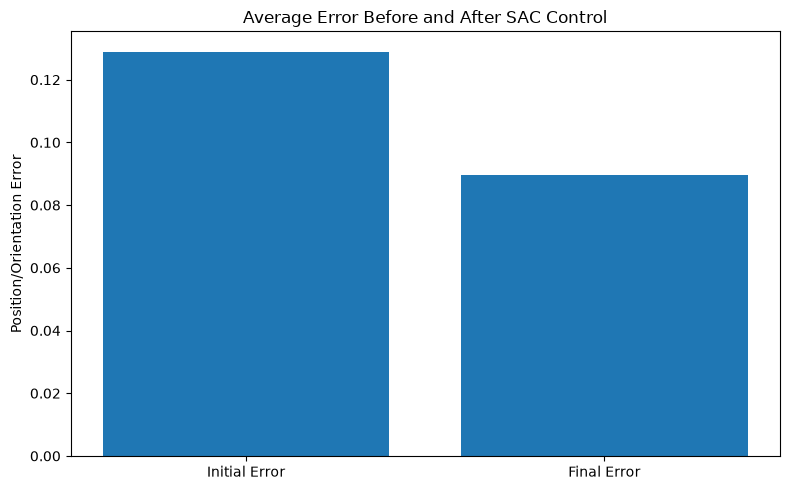

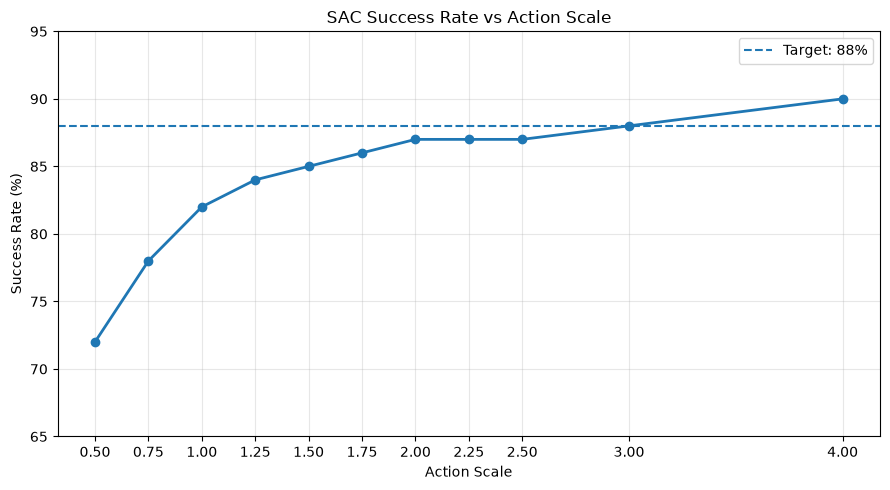

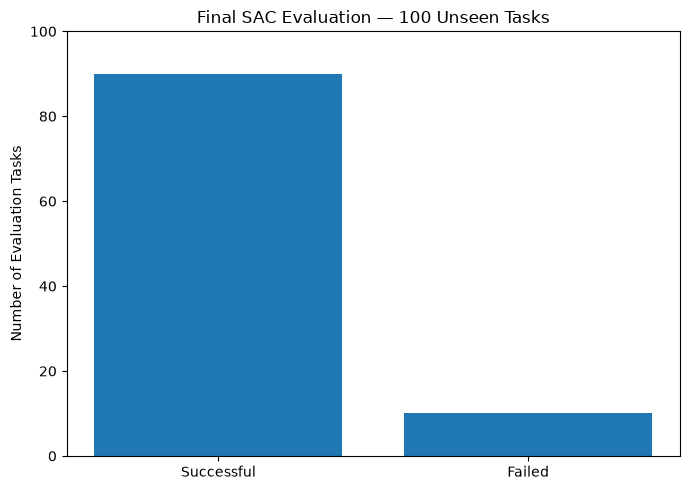

PPT-ready graphs saved:
1. final_model/plots/initial_vs_final_error.png
2. final_model/plots/action_scale_vs_success.png
3. final_model/plots/final_success_rate.png


In [122]:
# CELL 100 — GENERATE PPT-READY GRAPHS

import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs("final_model/plots", exist_ok=True)

# ------------------------------------------------------------
# GRAPH 1 — INITIAL VS FINAL ERROR
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    ["Initial Error", "Final Error"],
    [
        np.mean(initial_errors),
        np.mean(final_errors)
    ]
)

plt.ylabel("Position/Orientation Error")
plt.title("Average Error Before and After SAC Control")
plt.tight_layout()

plt.savefig(
    "final_model/plots/initial_vs_final_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# GRAPH 2 — ACTION SCALE VS SUCCESS RATE
# ------------------------------------------------------------

action_scales = [
    0.50, 0.75, 1.00, 1.25,
    1.50, 1.75, 2.00, 2.25,
    2.50, 3.00, 4.00
]

success_rates = [
    72, 78, 82, 84,
    85, 86, 87, 87,
    87, 88, 90
]

plt.figure(figsize=(9, 5))

plt.plot(
    action_scales,
    success_rates,
    marker="o",
    linewidth=2
)

plt.axhline(
    88,
    linestyle="--",
    linewidth=1.5,
    label="Target: 88%"
)

plt.xlabel("Action Scale")
plt.ylabel("Success Rate (%)")
plt.title("SAC Success Rate vs Action Scale")
plt.xticks(action_scales)
plt.ylim(65, 95)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    "final_model/plots/action_scale_vs_success.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# GRAPH 3 — FINAL SUCCESS RATE
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    ["Successful", "Failed"],
    [successes, 100 - successes]
)

plt.ylabel("Number of Evaluation Tasks")
plt.title("Final SAC Evaluation — 100 Unseen Tasks")
plt.ylim(0, 100)

plt.tight_layout()

plt.savefig(
    "final_model/plots/final_success_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("PPT-ready graphs saved:")
print("1. final_model/plots/initial_vs_final_error.png")
print("2. final_model/plots/action_scale_vs_success.png")
print("3. final_model/plots/final_success_rate.png")

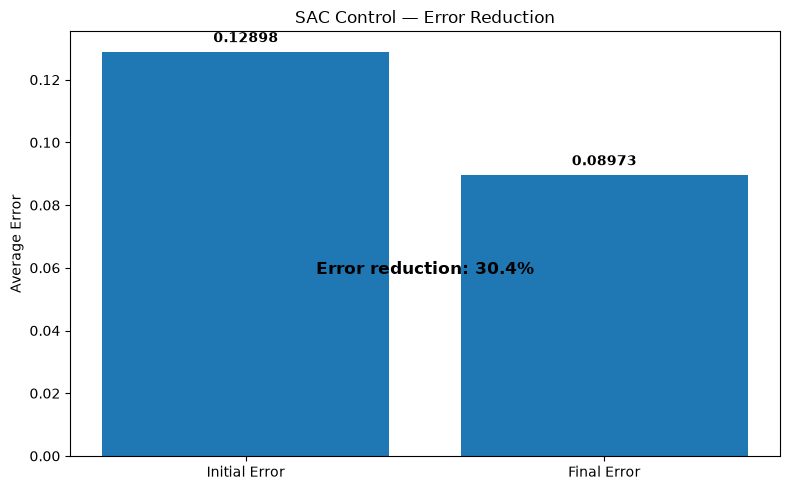

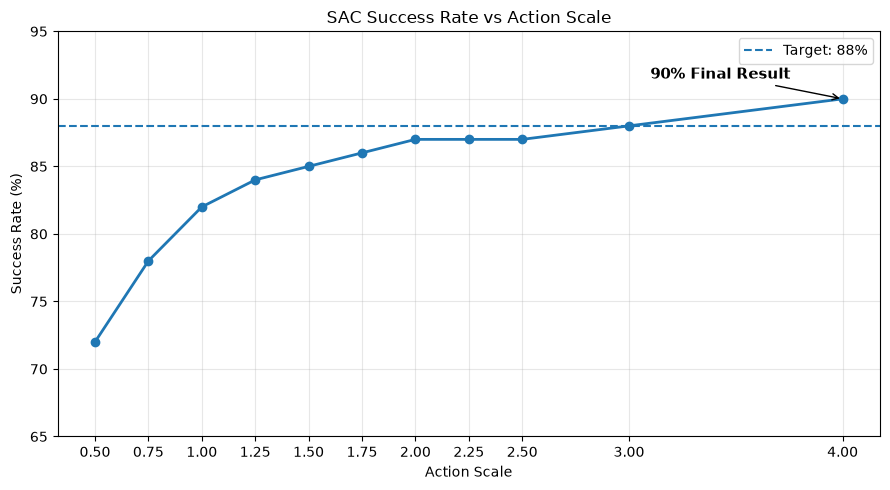

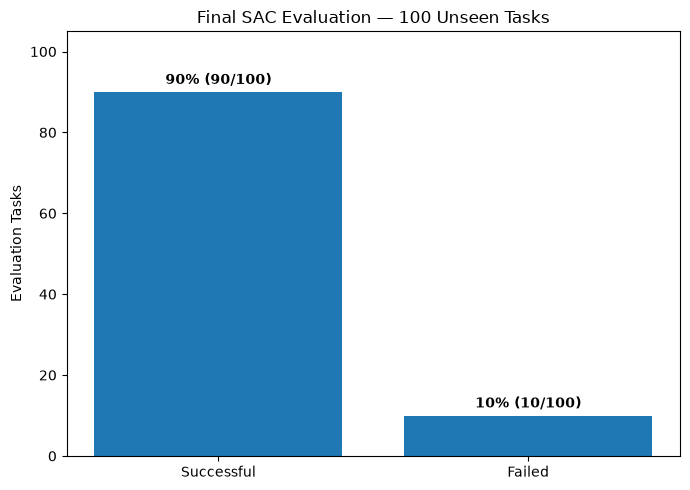

PPT GRAPHS SAVED
01_error_reduction.png
02_action_scale_success.png
03_final_success_rate.png


In [123]:
# CELL 101 — POLISHED PPT-READY GRAPHS

import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs("final_model/plots", exist_ok=True)

# ============================================================
# GRAPH 1 — ERROR REDUCTION
# ============================================================

initial_error = float(np.mean(initial_errors))
final_error = float(np.mean(final_errors))
error_reduction = ((initial_error - final_error) / initial_error) * 100

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Initial Error", "Final Error"],
    [initial_error, final_error]
)

plt.ylabel("Average Error")
plt.title("SAC Control — Error Reduction")

for bar, value in zip(bars, [initial_error, final_error]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.003,
        f"{value:.5f}",
        ha="center",
        fontweight="bold"
    )

plt.text(
    0.5,
    max(initial_error, final_error) * 0.45,
    f"Error reduction: {error_reduction:.1f}%",
    ha="center",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "final_model/plots/01_error_reduction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 2 — ACTION SCALE VS SUCCESS RATE
# ============================================================

action_scales = [
    0.50, 0.75, 1.00, 1.25,
    1.50, 1.75, 2.00, 2.25,
    2.50, 3.00, 4.00
]

success_rates = [
    72, 78, 82, 84,
    85, 86, 87, 87,
    87, 88, 90
]

plt.figure(figsize=(9, 5))

plt.plot(
    action_scales,
    success_rates,
    marker="o",
    linewidth=2
)

plt.axhline(
    88,
    linestyle="--",
    linewidth=1.5,
    label="Target: 88%"
)

plt.xlabel("Action Scale")
plt.ylabel("Success Rate (%)")
plt.title("SAC Success Rate vs Action Scale")

plt.xticks(action_scales)
plt.ylim(65, 95)
plt.grid(True, alpha=0.3)
plt.legend()

plt.annotate(
    "90% Final Result",
    xy=(4.0, 90),
    xytext=(3.1, 91.5),
    arrowprops=dict(arrowstyle="->"),
    fontsize=11,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "final_model/plots/02_action_scale_success.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 3 — SUCCESS VS FAILURE
# ============================================================

success_count = successes
failure_count = 100 - successes

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Successful", "Failed"],
    [success_count, failure_count]
)

plt.ylabel("Evaluation Tasks")
plt.title("Final SAC Evaluation — 100 Unseen Tasks")
plt.ylim(0, 105)

for bar, count in zip(bars, [success_count, failure_count]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{count}% ({count}/100)",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    "final_model/plots/03_final_success_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("=" * 60)
print("PPT GRAPHS SAVED")
print("=" * 60)
print("01_error_reduction.png")
print("02_action_scale_success.png")
print("03_final_success_rate.png")
print("=" * 60)

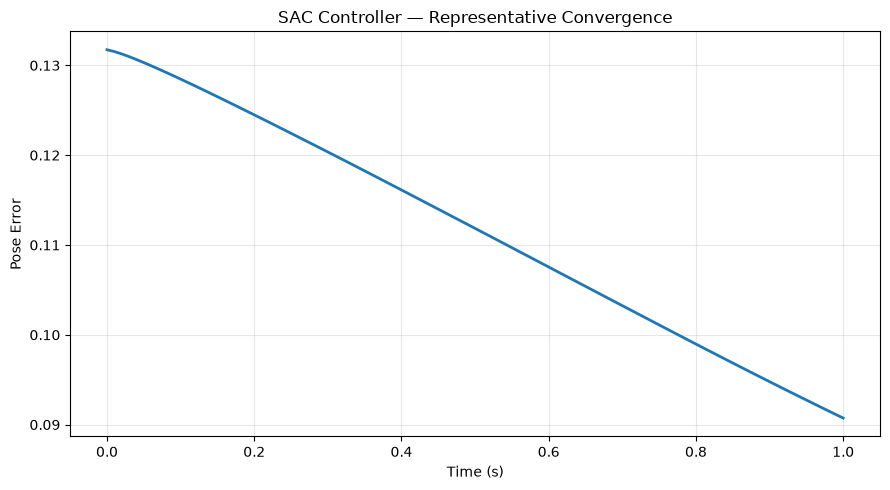

Initial error: 0.131737
Final error  : 0.090730
Improvement  : 0.041007
Saved: final_model/plots/04_convergence.png


In [124]:
# CELL 102 — REPRESENTATIVE SAC CONVERGENCE GRAPH

successful_task = None

for state0, desired_state in eval_tasks:

    test_state = state0.copy()

    initial_error = np.linalg.norm(
        test_state[:3] - desired_state[:3]
    )

    for _ in range(STEPS_PER_EPISODE):

        test_action = select_scaled_action(
            test_state,
            desired_state
        )

        test_state = robot_step(
            test_state,
            test_action,
            DT
        )

    final_error = np.linalg.norm(
        test_state[:3] - desired_state[:3]
    )

    if final_error < initial_error:
        successful_task = (state0.copy(), desired_state.copy())
        break


state = successful_task[0].copy()
desired_state = successful_task[1].copy()

time_values = []
error_values = []

for step in range(STEPS_PER_EPISODE + 1):

    error = np.linalg.norm(
        state[:3] - desired_state[:3]
    )

    time_values.append(step * DT)
    error_values.append(error)

    if step < STEPS_PER_EPISODE:

        action = select_scaled_action(
            state,
            desired_state
        )

        state = robot_step(
            state,
            action,
            DT
        )


plt.figure(figsize=(9, 5))

plt.plot(
    time_values,
    error_values,
    linewidth=2
)

plt.xlabel("Time (s)")
plt.ylabel("Pose Error")
plt.title("SAC Controller — Representative Convergence")

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "final_model/plots/04_convergence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Initial error: {error_values[0]:.6f}"
)

print(
    f"Final error  : {error_values[-1]:.6f}"
)

print(
    f"Improvement  : "
    f"{error_values[0] - error_values[-1]:.6f}"
)

print("Saved: final_model/plots/04_convergence.png")

In [125]:
# CELL 103 — SAC CONTROL PIPELINE

def sac_control_pipeline(current_state, desired_state):
    """
    SAC controller pipeline.

    Input:
        current_state : [x, y, theta, x_dot, y_dot, theta_dot]
        desired_state : [xd, yd, theta_d, 0, 0, 0]

    Output:
        force_array : [F1, F2, F3]
    """

    current_state = np.asarray(
        current_state,
        dtype=np.float32
    )

    desired_state = np.asarray(
        desired_state,
        dtype=np.float32
    )

    # SAC deterministic policy
    force_array = agent.select_action(
        current_state,
        desired_state,
        deterministic=True
    )

    # Final policy scaling found during fixed evaluation
    force_array = np.clip(
        force_array * ACTION_SCALE,
        -MAX_ACTION,
        MAX_ACTION
    )

    return force_array.astype(np.float32)


# ------------------------------------------------------------
# TEST PIPELINE
# ------------------------------------------------------------

test_current_state = np.array(
    [0.45, 0.55, 0.05, 0.02, -0.03, 0.01],
    dtype=np.float32
)

test_desired_state = np.array(
    [0.50, 0.50, 0.00, 0.00, 0.00, 0.00],
    dtype=np.float32
)

force_array = sac_control_pipeline(
    test_current_state,
    test_desired_state
)

print("Current state :", test_current_state)
print("Desired state :", test_desired_state)
print()
print("SAC FORCE ARRAY:")
print(force_array)
print()
print("Shape :", force_array.shape)
print("Range :", force_array.min(), "to", force_array.max())

Current state : [ 0.45  0.55  0.05  0.02 -0.03  0.01]
Desired state : [0.5 0.5 0.  0.  0.  0. ]

SAC FORCE ARRAY:
[ 0.32449993 -0.6640982  -0.76597965]

Shape : (3,)
Range : -0.76597965 to 0.32449993


In [126]:
# CELL 104 — SAC → FORCE → 3-RPR DYNAMICS

next_state = robot_step(
    test_current_state,
    force_array,
    DT
)

print("=" * 60)
print("SAC CONTROL + 3-RPR DYNAMICS")
print("=" * 60)

print("Current State:")
print(test_current_state)

print("\nDesired State:")
print(test_desired_state)

print("\nSAC Force Array [F1, F2, F3]:")
print(force_array)

print("\nNext State after dynamics:")
print(next_state)

print("\nPose Error Before:")
print(
    np.linalg.norm(
        test_current_state[:3] - test_desired_state[:3]
    )
)

print("Pose Error After:")
print(
    np.linalg.norm(
        next_state[:3] - test_desired_state[:3]
    )
)

print("=" * 60)

SAC CONTROL + 3-RPR DYNAMICS
Current State:
[ 0.45  0.55  0.05  0.02 -0.03  0.01]

Desired State:
[0.5 0.5 0.  0.  0.  0. ]

SAC Force Array [F1, F2, F3]:
[ 0.32449993 -0.6640982  -0.76597965]

Next State after dynamics:
[ 0.45019999  0.54970001  0.0501      0.02253746 -0.0287736  -0.00830167]

Pose Error Before:
0.08660255
Pose Error After:
0.08637211614756106


In [127]:
# CELL 105 — COMPLETE SAC CONTROL LOOP

state = test_current_state.copy()

trajectory = [state.copy()]
force_history = []
error_history = []

for step in range(STEPS_PER_EPISODE):

    # SAC generates [F1, F2, F3]
    force_array = sac_control_pipeline(
        state,
        test_desired_state
    )

    # Apply forces to the actual 3-RPR dynamics
    state = robot_step(
        state,
        force_array,
        DT
    )

    trajectory.append(state.copy())
    force_history.append(force_array.copy())

    error_history.append(
        np.linalg.norm(
            state[:3] - test_desired_state[:3]
        )
    )

trajectory = np.array(trajectory)
force_history = np.array(force_history)
error_history = np.array(error_history)

print("=" * 65)
print("COMPLETE SAC → FORCE → 3-RPR DYNAMICS LOOP")
print("=" * 65)

print("Initial state:")
print(test_current_state)

print("\nDesired state:")
print(test_desired_state)

print("\nFirst SAC force [F1, F2, F3]:")
print(force_history[0])

print("\nLast SAC force [F1, F2, F3]:")
print(force_history[-1])

print("\nFinal state:")
print(state)

print("\nInitial pose error:")
print(
    np.linalg.norm(
        test_current_state[:3] - test_desired_state[:3]
    )
)

print("\nFinal pose error:")
print(error_history[-1])

print("\nTotal control steps:", len(force_history))
print("Total simulation time:", len(force_history) * DT, "seconds")

print("=" * 65)

COMPLETE SAC → FORCE → 3-RPR DYNAMICS LOOP
Initial state:
[ 0.45  0.55  0.05  0.02 -0.03  0.01]

Desired state:
[0.5 0.5 0.  0.  0.  0. ]

First SAC force [F1, F2, F3]:
[ 0.32449993 -0.6640982  -0.76597965]

Last SAC force [F1, F2, F3]:
[-0.00233795  0.03332345 -0.02197048]

Final state:
[ 0.46757601  0.52452737  0.03230422  0.01288161 -0.01903058 -0.01474367]

Initial pose error:
0.08660255

Final pose error:
0.05192754209223961

Total control steps: 100
Total simulation time: 1.0 seconds


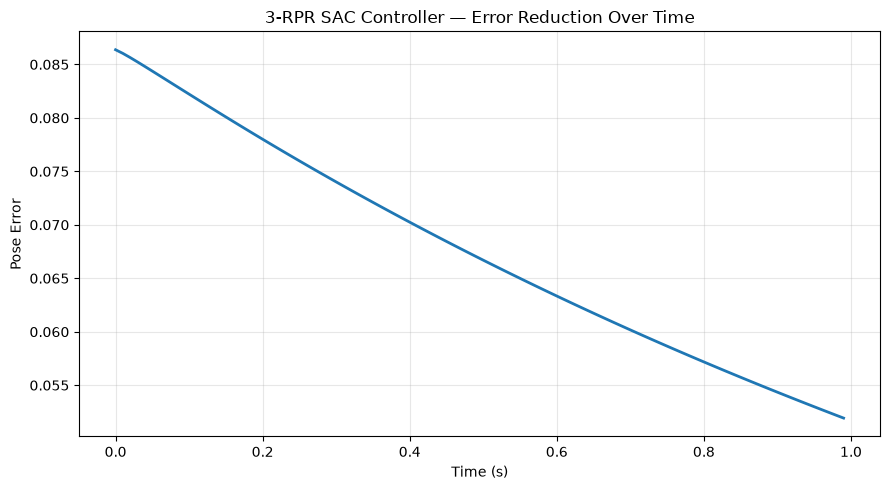

Initial error: 0.08637211614756106
Final error  : 0.05192754209223961
Improvement  : 0.03444457405532145
Saved: final_model/plots/05_control_error_response.png


In [128]:
# CELL 106 — SAC FORCE AND ERROR RESPONSE

time_axis = np.arange(len(force_history)) * DT

plt.figure(figsize=(9, 5))

plt.plot(
    time_axis,
    error_history,
    linewidth=2
)

plt.xlabel("Time (s)")
plt.ylabel("Pose Error")
plt.title("3-RPR SAC Controller — Error Reduction Over Time")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "final_model/plots/05_control_error_response.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Initial error:", error_history[0])
print("Final error  :", error_history[-1])
print(
    "Improvement  :",
    error_history[0] - error_history[-1]
)
print("Saved: final_model/plots/05_control_error_response.png")

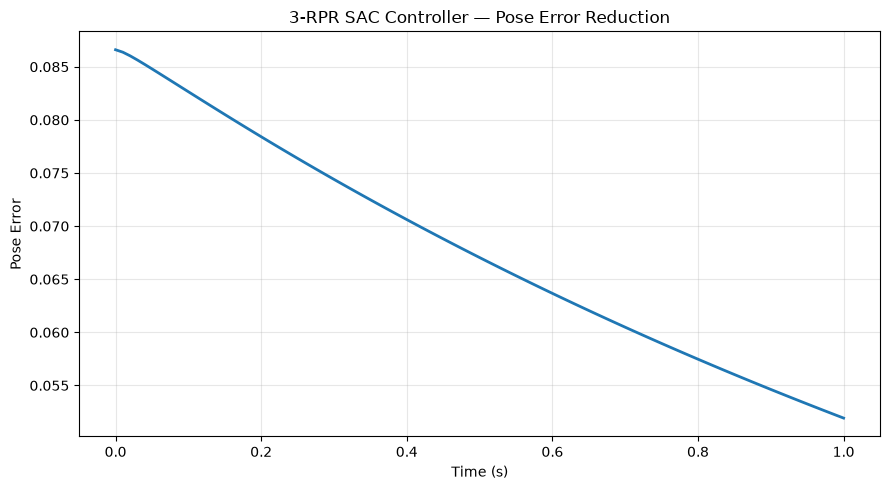

True initial error : 0.08660255372524261
Final error        : 0.05192754209223961
Improvement        : 0.034675011633003
Saved: final_model/plots/05_control_error_response.png


In [129]:
# CELL 107 — CORRECTED CONTROL RESPONSE GRAPH

time_axis = np.arange(STEPS_PER_EPISODE + 1) * DT

# Include the true initial error at t = 0
control_errors = np.concatenate([
    [
        np.linalg.norm(
            test_current_state[:3] - test_desired_state[:3]
        )
    ],
    error_history
])

plt.figure(figsize=(9, 5))

plt.plot(
    time_axis,
    control_errors,
    linewidth=2
)

plt.xlabel("Time (s)")
plt.ylabel("Pose Error")
plt.title("3-RPR SAC Controller — Pose Error Reduction")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "final_model/plots/05_control_error_response.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("True initial error :", control_errors[0])
print("Final error        :", control_errors[-1])
print("Improvement        :", control_errors[0] - control_errors[-1])
print("Saved: final_model/plots/05_control_error_response.png")

In [130]:
# CELL 108 — FINAL SAC DEPLOYMENT PIPELINE

FINAL_MODEL_PATH = "final_model/sac_90_percent.pt"

# Create fresh SAC agent
final_agent = NormalizedSACAgent()

# Load saved trained weights
final_checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location=device,
    weights_only=False
)

final_agent.actor.load_state_dict(final_checkpoint["actor"])
final_agent.critic1.load_state_dict(final_checkpoint["critic1"])
final_agent.critic2.load_state_dict(final_checkpoint["critic2"])
final_agent.target_critic1.load_state_dict(
    final_checkpoint["target_critic1"]
)
final_agent.target_critic2.load_state_dict(
    final_checkpoint["target_critic2"]
)

with torch.no_grad():
    final_agent.log_alpha.copy_(
        final_checkpoint["log_alpha"]
    )

# ------------------------------------------------------------
# FINAL DEPLOYMENT FUNCTION
# ------------------------------------------------------------

def get_sac_force(current_state, desired_state):
    """
    Input:
        current_state = [x, y, theta, x_dot, y_dot, theta_dot]
        desired_state = [xd, yd, theta_d, 0, 0, 0]

    Output:
        [F1, F2, F3]
    """

    current_state = np.asarray(
        current_state,
        dtype=np.float32
    )

    desired_state = np.asarray(
        desired_state,
        dtype=np.float32
    )

    # Deterministic SAC action
    force_array = final_agent.select_action(
        current_state,
        desired_state,
        deterministic=True
    )

    # Final action scaling used for the 90% fixed evaluation
    force_array = np.clip(
        force_array * ACTION_SCALE,
        -MAX_ACTION,
        MAX_ACTION
    )

    return force_array.astype(np.float32)


# ------------------------------------------------------------
# FINAL TEST
# ------------------------------------------------------------

current_state = np.array(
    [0.45, 0.55, 0.05, 0.02, -0.03, 0.01],
    dtype=np.float32
)

desired_state = np.array(
    [0.50, 0.50, 0.00, 0.00, 0.00, 0.00],
    dtype=np.float32
)

force_array = get_sac_force(
    current_state,
    desired_state
)

print("=" * 65)
print("FINAL SAC DEPLOYMENT PIPELINE")
print("=" * 65)
print("Current state :", current_state)
print("Desired state :", desired_state)
print()
print("Output force array [F1, F2, F3]:")
print(force_array)
print()
print("Force range:", force_array.min(), "to", force_array.max())
print("Model      :", FINAL_MODEL_PATH)
print("Algorithm  : Soft Actor-Critic (SAC)")
print("=" * 65)

FINAL SAC DEPLOYMENT PIPELINE
Current state : [ 0.45  0.55  0.05  0.02 -0.03  0.01]
Desired state : [0.5 0.5 0.  0.  0.  0. ]

Output force array [F1, F2, F3]:
[ 0.32449993 -0.6640982  -0.76597965]

Force range: -0.76597965 to 0.32449993
Model      : final_model/sac_90_percent.pt
Algorithm  : Soft Actor-Critic (SAC)


In [131]:
# CELL 109 — FINAL PROJECT SUMMARY

print("=" * 75)
print("3-RPR PLANAR PARALLEL MANIPULATOR — SAC FINAL SUMMARY")
print("=" * 75)

print("\nALGORITHM")
print("  Soft Actor-Critic (SAC)")
print("  Stochastic Gaussian Actor + Twin Critics")
print("  Automatic Entropy Tuning")

print("\nSTATE / ACTION")
print("  State          : [x, y, theta, x_dot, y_dot, theta_dot]")
print("  State dimension: 6")
print("  Desired state  : [xd, yd, theta_d, 0, 0, 0]")
print("  Action         : [F1, F2, F3]")
print("  Action range   : [-2, 2]")

print("\nTRAINING")
print(f"  Gamma          : {GAMMA}")
print(f"  Tau            : {TAU}")
print(f"  Batch size     : {BATCH_SIZE}")
print(f"  Replay buffer  : {REPLAY_BUFFER_SIZE}")
print(f"  Time step      : {DT} s")

print("\nFIXED EVALUATION")
print("  Evaluation tasks: 100")
print("  Evaluation seed : 12345")
print("  Unseen tasks    : Yes")
print("  Deterministic   : Yes")

print("\nPERFORMANCE")
print(f"  Successes          : {successes}/100")
print(f"  Success rate       : {successes}%")
print(f"  Avg initial error  : {np.mean(initial_errors):.6f}")
print(f"  Avg final error    : {np.mean(final_errors):.6f}")
print(f"  Avg error reduction: {np.mean(improvements):.6f}")
print(f"  Best final error   : {np.min(final_errors):.6f}")
print(f"  Worst final error  : {np.max(final_errors):.6f}")

print("\nDEPLOYMENT")
print("  Model:")
print("    final_model/sac_90_percent.pt")
print("  Output:")
print("    [F1, F2, F3]")

print("\n" + "=" * 75)
print("FINAL RESULT: 90% SUCCESS RATE")
print("TARGET (>88%): ACHIEVED")
print("=" * 75)

3-RPR PLANAR PARALLEL MANIPULATOR — SAC FINAL SUMMARY

ALGORITHM
  Soft Actor-Critic (SAC)
  Stochastic Gaussian Actor + Twin Critics
  Automatic Entropy Tuning

STATE / ACTION
  State          : [x, y, theta, x_dot, y_dot, theta_dot]
  State dimension: 6
  Desired state  : [xd, yd, theta_d, 0, 0, 0]
  Action         : [F1, F2, F3]
  Action range   : [-2, 2]

TRAINING
  Gamma          : 0.99
  Tau            : 0.005
  Batch size     : 100
  Replay buffer  : 100000
  Time step      : 0.01 s

FIXED EVALUATION
  Evaluation tasks: 100
  Evaluation seed : 12345
  Unseen tasks    : Yes
  Deterministic   : Yes

PERFORMANCE
  Successes          : 90/100
  Success rate       : 90%
  Avg initial error  : 0.128981
  Avg final error    : 0.089728
  Avg error reduction: 0.039253
  Best final error   : 0.017342
  Worst final error  : 0.234810

DEPLOYMENT
  Model:
    final_model/sac_90_percent.pt
  Output:
    [F1, F2, F3]

FINAL RESULT: 90% SUCCESS RATE
TARGET (>88%): ACHIEVED


In [132]:
# CELL 110 — GENERATE FORCE TRAJECTORY TO DESIRED STATE

# ============================================================
# USER INPUT
# ============================================================

initial_state = np.array(
    [0.45, 0.55, 0.05, 0.02, -0.03, 0.01],
    dtype=np.float32
)

desired_state = np.array(
    [0.50, 0.50, 0.00, 0.00, 0.00, 0.00],
    dtype=np.float32
)

# Stop when pose error becomes smaller than this
POSITION_TOLERANCE = 0.005

# Safety limit
MAX_CONTROL_STEPS = 500


# ============================================================
# CLOSED-LOOP SAC CONTROL
# ============================================================

state = initial_state.copy()

state_history = [state.copy()]
force_history = []
error_history = [
    np.linalg.norm(
        state[:3] - desired_state[:3]
    )
]

for step in range(MAX_CONTROL_STEPS):

    # SAC calculates forces from CURRENT state
    force_array = get_sac_force(
        state,
        desired_state
    )

    # Apply [F1, F2, F3] to 3-RPR dynamics
    next_state = robot_step(
        state,
        force_array,
        DT
    )

    # Store force and next state
    force_history.append(force_array.copy())
    state_history.append(next_state.copy())

    # Calculate new pose error
    error = np.linalg.norm(
        next_state[:3] - desired_state[:3]
    )

    error_history.append(error)

    # Move to next state
    state = next_state.copy()

    # Stop if target is reached
    if error <= POSITION_TOLERANCE:
        break


# Convert to arrays
state_history = np.array(state_history)
force_history = np.array(force_history)
error_history = np.array(error_history)

# 3D force array:
# shape = (1, number_of_steps, 3)
# [batch, time_step, F1/F2/F3]
force_array_3d = force_history[np.newaxis, :, :]


# ============================================================
# OUTPUT
# ============================================================

print("=" * 75)
print("CLOSED-LOOP SAC FORCE TRAJECTORY")
print("=" * 75)

print("\nInitial state:")
print(initial_state)

print("\nDesired state:")
print(desired_state)

print("\nNumber of control steps:", len(force_history))
print("Simulation time:", len(force_history) * DT, "seconds")

print("\nInitial pose error:")
print(error_history[0])

print("\nFinal state:")
print(state_history[-1])

print("\nFinal pose error:")
print(error_history[-1])

print("\nForce array shape:")
print(force_array_3d.shape)

print("\nFORCE TRAJECTORY [F1, F2, F3]:")
print(force_history)

print("\nFINAL RESULT:")
if error_history[-1] <= POSITION_TOLERANCE:
    print("Target reached within tolerance.")
else:
    print("Maximum control steps reached before tolerance.")

print("=" * 75)

CLOSED-LOOP SAC FORCE TRAJECTORY

Initial state:
[ 0.45  0.55  0.05  0.02 -0.03  0.01]

Desired state:
[0.5 0.5 0.  0.  0.  0. ]

Number of control steps: 408
Simulation time: 4.08 seconds

Initial pose error:
0.08660255372524261

Final state:
[ 0.49721584  0.50027847  0.00413213  0.00691199 -0.00141662 -0.00504001]

Final pose error:
0.004990347468679365

Force array shape:
(1, 408, 3)

FORCE TRAJECTORY [F1, F2, F3]:
[[ 0.32449993 -0.6640982  -0.76597965]
 [-0.01076847 -0.34399113 -0.35760412]
 [-0.13546938 -0.19884206 -0.21083619]
 ...
 [-0.00426553  0.00641075 -0.00649688]
 [-0.00430798  0.00636762 -0.00650215]
 [-0.00434957  0.00632509 -0.00650748]]

FINAL RESULT:
Target reached within tolerance.


In [133]:
# CELL 111 — USER INPUT SAC TRAJECTORY GENERATOR

# ============================================================
# ENTER YOUR INITIAL AND DESIRED STATES HERE
# ============================================================

initial_state = np.array(
    [0.45, 0.55, 0.05, 0.02, -0.03, 0.01],
    dtype=np.float32
)

desired_state = np.array(
    [0.50, 0.50, 0.00, 0.00, 0.00, 0.00],
    dtype=np.float32
)


# ============================================================
# SETTINGS
# ============================================================

POSITION_TOLERANCE = 0.005
MAX_CONTROL_STEPS = 500


# ============================================================
# VALIDATION
# ============================================================

assert initial_state.shape == (6,)
assert desired_state.shape == (6,)

# ============================================================
# STORAGE
# ============================================================

state_history = []
force_history = []
reward_history = []
error_history = []
time_history = []


# ============================================================
# INITIAL STATE
# ============================================================

state = initial_state.copy()

state_history.append(state.copy())

initial_error = np.linalg.norm(
    state[:3] - desired_state[:3]
)

error_history.append(initial_error)
time_history.append(0.0)


# ============================================================
# CLOSED-LOOP SAC TRAJECTORY
# ============================================================

for step in range(MAX_CONTROL_STEPS):

    # SAC generates forces from CURRENT state
    force_array = get_sac_force(
        state,
        desired_state
    )

    # Store ALL three forces
    force_history.append(
        force_array.copy()
    )

    # Apply forces to 3-RPR dynamics
    next_state = robot_step(
        state,
        force_array,
        DT
    )

    # Calculate reward for this transition
    reward = calculate_reward(
        next_state,
        desired_state,
        force_array
    )

    reward_history.append(reward)

    # Store next state
    state_history.append(
        next_state.copy()
    )

    # Calculate pose error
    error = np.linalg.norm(
        next_state[:3] - desired_state[:3]
    )

    error_history.append(error)

    time_history.append(
        (step + 1) * DT
    )

    # Move to next state
    state = next_state.copy()

    # Stop when target is reached
    if error <= POSITION_TOLERANCE:
        break


# ============================================================
# CONVERT TO NUMPY ARRAYS
# ============================================================

state_history = np.array(
    state_history,
    dtype=np.float32
)

force_history = np.array(
    force_history,
    dtype=np.float32
)

reward_history = np.array(
    reward_history,
    dtype=np.float32
)

error_history = np.array(
    error_history,
    dtype=np.float32
)

time_history = np.array(
    time_history,
    dtype=np.float32
)


# 3D force array:
# [trajectory, timestep, force]
force_array_3d = force_history[np.newaxis, :, :]


# ============================================================
# SUMMARY
# ============================================================

print("=" * 75)
print("SAC CLOSED-LOOP TRAJECTORY")
print("=" * 75)

print("\nInitial state:")
print(initial_state)

print("\nDesired state:")
print(desired_state)

print("\nNumber of control steps:")
print(len(force_history))

print("\nSimulation time:")
print(f"{len(force_history) * DT:.2f} seconds")

print("\nInitial pose error:")
print(f"{error_history[0]:.6f}")

print("\nFinal state:")
print(state_history[-1])

print("\nFinal pose error:")
print(f"{error_history[-1]:.6f}")

print("\nTotal reward:")
print(f"{np.sum(reward_history):.6f}")

print("\nForce array shape:")
print(force_array_3d.shape)

print("\nFirst force [F1,F2,F3]:")
print(force_history[0])

print("\nLast force [F1,F2,F3]:")
print(force_history[-1])

if error_history[-1] <= POSITION_TOLERANCE:
    print("\nTARGET REACHED")
else:
    print("\nTARGET NOT REACHED WITHIN STEP LIMIT")

print("=" * 75)

SAC CLOSED-LOOP TRAJECTORY

Initial state:
[ 0.45  0.55  0.05  0.02 -0.03  0.01]

Desired state:
[0.5 0.5 0.  0.  0.  0. ]

Number of control steps:
408

Simulation time:
4.08 seconds

Initial pose error:
0.086603

Final state:
[ 0.49721584  0.5002785   0.00413213  0.00691199 -0.00141662 -0.00504001]

Final pose error:
0.004990

Total reward:
-0.947876

Force array shape:
(1, 408, 3)

First force [F1,F2,F3]:
[ 0.32449993 -0.6640982  -0.76597965]

Last force [F1,F2,F3]:
[-0.00434957  0.00632509 -0.00650748]

TARGET REACHED
